<span style="color:#9A1A24;text-align:center">

# TÓPICOS DE MATEMÁTICA PARA SISTEMAS AUTÓNOMOS

</span>

***
<center><h1> TRABALHO LETIVO - ENTREGA 2 </h1></center>

***
<span style="color:#000000;text-align:LEFT">

**Nota 1**: Todos elementos do grupo são responsáveis por esta entrega<br>
**Nota 2**: Todos elementos do grupo tomaram conhecimento das regras estabelecidas para o funcionamento da u.c. no [**Moodle do ISEP**](https://moodle.isep.ipp.pt)<br>

</span>

***

## GRUPO  19
> N: 1211756  Nome: Geovani Lopes  \
> N: 1120542  Nome: Luis Lei  \
> N: 1261726  Nome: Hugo Amado

**Projeto:** TOMSA 2026 — Visualizador e Analisador de Trajetórias Multi-Robô (INESC TEC, Aguçadoura).
**Repositório:** https://github.com/Juninhoo/TOMSA

# Conteúdo

**Parte I — Fundamentos e dados**
- [1. Introdução](#cap1)
- [2. Arquitetura do programa](#cap2)
- [3. Tratamento dos dados](#cap3)
- [4. Sistemas de coordenadas](#cap4)

**Parte II — Matemática da orientação e do movimento**
- [5. Matrizes de rotação](#cap5)
- [6. Cálculo do rumo e da orientação](#cap6)
- [7. Trajetórias e movimento](#cap7)
- [8. Filtro de Kalman](#cap8)

**Parte III — Relações entre robôs**
- [9. Distâncias entre robôs](#cap9)
- [10. Deteção de proximidade e risco de colisão](#cap10)

**Parte IV — Programa, testes e resultados**
- [11. Visualização e dashboard](#cap11)
- [12. Testes e validação](#cap12)
- [13. Resultados e discussão](#cap13)
- [14. Conclusões](#cap14)

**Secções do modelo da unidade curricular**
- [Objetivos definidos *versus* atingidos](#objetivos) (no Capítulo 14)
- [Relevância das bibliotecas Python](#bibliotecas) (no Capítulo 2)
- [Resultados / Evidências](#evidencias) (Capítulos 12 e 13)
- [Análise crítica do trabalho da equipa](#equipa)

**Como ler este relatório.** Cada capítulo segue a mesma ordem: problema, fundamentação matemática, equações e significado das variáveis, código real do projeto (extraído **diretamente dos ficheiros** do repositório por células executáveis, com o número de linha), exemplo numérico com dados reais e interpretação. Tudo o que está marcado como *réplica* é uma reescrita em Python de lógica que, no projeto, vive em JavaScript (dentro de `web_server.py`), feita aqui só para a poder verificar numericamente.

## Como executar este notebook

1. Seguir o `README.md` (instalar as dependências num ambiente virtual): `pip install -r requirements.txt`.
2. Instalar o Jupyter (não está no `requirements.txt`): `pip install jupyter`.
3. Abrir com o terminal **na raiz do repositório**: `jupyter notebook TOMSA_TL2_GRUPOXX.ipynb`.
4. Executar todas as células por ordem (*Kernel → Restart & Run All*). Demora menos de 1 minuto.

O notebook **não grava resultados nem ficheiros de dados** no repositório (só o Python pode criar as suas pastas de cache `__pycache__`) e não usa caminhos absolutos: a primeira célula procura sozinha a pasta `multi_robot_system` a subir a partir da pasta atual.

## 0. Preparação do ambiente (ferramentas usadas ao longo do relatório)

In [1]:
import os, sys, re, ast, inspect, subprocess, tempfile, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def _procurar_raiz():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "multi_robot_system" / "main.py").is_file():
            return p
    raise FileNotFoundError("Abra o notebook a partir da pasta do repositório (a que contém multi_robot_system).")

RAIZ = _procurar_raiz()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
np.set_printoptions(precision=5, suppress=True, linewidth=150)
pd.set_option("display.width", 200, "display.max_columns", 30)

# --- mostrar código REAL do repositório, com o número de linha do ficheiro ----------------------
def _rel(ficheiro):
    return str(Path(ficheiro).resolve().relative_to(RAIZ))

def mostrar_codigo(obj, de=None, ate=None):
    """Imprime o código-fonte real de uma função/classe. 'de' e 'ate' são textos que marcam a primeira e a última linha a mostrar."""
    linhas, inicio = inspect.getsourcelines(obj)
    i0, i1 = 0, len(linhas) - 1
    if de is not None:
        i0 = next(k for k, l in enumerate(linhas) if de in l)
    if ate is not None:
        i1 = next(k for k, l in enumerate(linhas) if k >= i0 and ate in l)
    print(f"# {_rel(inspect.getsourcefile(obj))}, linhas {inicio + i0} a {inicio + i1}")
    for k in range(i0, i1 + 1):
        print(f"{inicio + k:4d}  {linhas[k].rstrip()}")

JS_FICHEIRO = "multi_robot_system/visualization/web_server.py"

def mostrar_js(nome):
    """Imprime uma função JavaScript real de web_server.py (com os comentários 'Método/Obtemos' que a antecedem)."""
    L = Path(JS_FICHEIRO).read_text(encoding="utf-8").splitlines()
    pad = re.compile(r"(function\s+" + re.escape(nome) + r"\s*\(|const\s+" + re.escape(nome) + r"\s*=)")
    i = next(k for k, l in enumerate(L) if pad.search(l))
    j = i
    while j > 0 and L[j - 1].strip().startswith("//"):
        j -= 1
    prof, fim, aberto = 0, i, False
    for k in range(i, len(L)):
        prof += L[k].count("{") - L[k].count("}")
        aberto = aberto or "{" in L[k]
        fim = k
        if (aberto and prof <= 0) or (not aberto and L[k].rstrip().endswith(";")):
            break
    print(f"# {JS_FICHEIRO}, linhas {j + 1} a {fim + 1}")
    for k in range(j, fim + 1):
        print(f"{k + 1:4d}  {L[k].rstrip()}")

def tmiss(t_abs):
    """Segundos absolutos (POSIX) para 'Xm Y.Ys' desde o início da missão (como no dashboard)."""
    s = t_abs - T0
    m = int(s // 60)
    return f"{m}m {s - 60 * m:.1f}s"

In [2]:
# Carregar a missão com o próprio código do projeto (mesma função que o dashboard usa)
from multi_robot_system.main import load_mission

ds, cfg = load_mission("multi_robot_system/config/mission_config.yaml")
IDS = sorted(ds.trajectories)
COR = {r: ds.trajectories[r].color for r in IDS}
T0 = ds.t0_mission                       # instante do primeiro registo de qualquer robô
print("\nRobôs:", IDS)


[INICIALIZAÇÃO] Origem de Referência: Lat=41.452310°, Lon=-8.812544°, Alt=56.46m
  -> A carregar e suavizar Robot 1 (AUV Alpha (Robot 1)) a partir de data/robot1_s1.csv...


     OK (9537 amostras processadas em 690.1ms, dur=5089.8s)
  -> A carregar e suavizar Robot 4 (AUV Bravo (Robot 4)) a partir de data/robot4_s1.csv...


     OK (5615 amostras processadas em 487.1ms, dur=2995.3s)
  -> A carregar e suavizar Robot 7 (AUV Charlie (Robot 7)) a partir de data/robot7_s1.csv...


     OK (15000 amostras processadas em 1070.3ms, dur=8012.7s)
[SINCRONIZAÇÃO] Janela temporal comum: 2396.3s sobreposta.

Robôs: ['Robot 1', 'Robot 4', 'Robot 7']


<a id="cap1"></a>
# CAPÍTULO 1 — INTRODUÇÃO

## 1.1 Contextualização

O INESC TEC opera veículos autónomos subaquáticos (AUV) na costa da Aguçadoura (Póvoa de Varzim). Cada veículo regista continuamente a sua odometria no formato de mensagem ROS `nav_msgs/Odometry`: posição geodésica, orientação em quaternião, as covariâncias da estimativa e as velocidades. O enunciado da unidade curricular fornece três destes registos, um por robô (**Robot 1**, **Robot 4** e **Robot 7**), com 9 537, 5 615 e 15 000 amostras a cerca de 1,9 amostras por segundo.

## 1.2 O problema

Os dados chegam numa forma pouco útil para raciocinar sobre o movimento: ângulos de latitude e longitude, um quaternião e relógios independentes. Para responder a perguntas simples, como *"para onde aponta o Robot 4 e a que distância está o Robot 1?"*, é preciso:

1. levar as posições para um referencial cartesiano em metros;
2. interpretar a orientação (quaternião) como rotação do corpo do robô;
3. alinhar no tempo robôs que não estiveram ativos em simultâneo;
4. suavizar o ruído e estimar velocidades;
5. medir distâncias, prever aproximações e avisar quando dois robôs ficam demasiado perto.

## 1.3 Objetivos

| N.º | Objetivo | Capítulo |
|---|---|---|
| O1 | Ler e limpar telemetria ROS em CSV, sem alterar os ficheiros originais | 3 |
| O2 | Converter WGS-84 em ECEF e NED, e vetores entre referenciais global e do corpo | 4 |
| O3 | Representar a atitude com quaterniões, matrizes de rotação e ângulos de Euler (ZYX) | 5 |
| O4 | Calcular rumo, rota e deriva | 6 |
| O5 | Reconstruir trajetórias e velocidades (Kalman e suavizador RTS) | 7 e 8 |
| O6 | Calcular distâncias, CPA e níveis de risco entre robôs | 9 e 10 |
| O7 | Visualizar tudo num dashboard interativo e validar com testes | 11 a 13 |

## 1.4 Importância da matemática na robótica

Nada disto é possível sem álgebra linear: **rotações** são matrizes ortogonais de determinante 1 (grupo $SO(3)$); a mudança de referencial é uma multiplicação matricial; o **filtro de Kalman** é álgebra de matrizes e probabilidade gaussiana; o **CPA** é a minimização de uma função quadrática do tempo; e a **geodesia** é geometria de um elipsoide. O objetivo deste relatório é mostrar cada uma destas ideias **no código que o grupo escreveu**.

## 1.5 Os três robôs

A tabela seguinte é calculada pelo próprio programa a partir dos CSV (os tempos são minutos desde o primeiro registo de qualquer robô).

,Etiqueta,Amostras,Início (min),Fim (min),Duração (min),Profundidade máx. (m),Caminho horizontal (m),Velocidade média (m por s)
Robô,,,,,,,,
Robot 1,AUV Alpha (Robot 1),9537,29.99,114.82,84.83,30.27,2022.15,0.39
Robot 4,AUV Bravo (Robot 4),5615,20.00,69.93,49.92,28.26,1324.37,0.43
Robot 7,AUV Charlie (Robot 7),15000,0.00,133.54,133.54,31.40,962.26,0.08


Janela temporal comum aos três robôs: 2396.3 s = 39.9 min  (de 30.0 a 69.9 min)


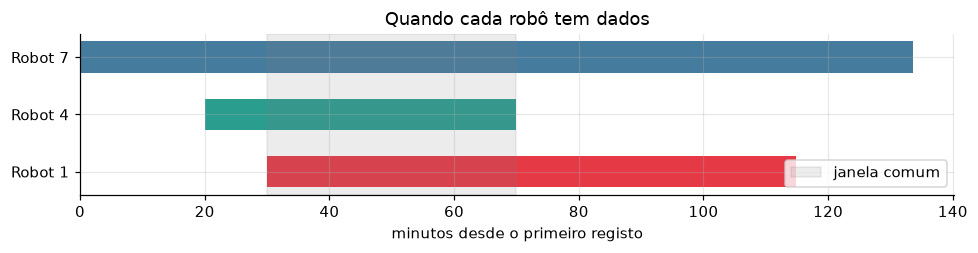

In [3]:
linhas = []
for r in IDS:
    t = ds.trajectories[r]
    linhas.append({
        "Robô": r, "Etiqueta": t.label, "Amostras": len(t.timestamps),
        "Início (min)": (t.timestamps[0] - T0) / 60, "Fim (min)": (t.timestamps[-1] - T0) / 60,
        "Duração (min)": t.duration_s / 60, "Profundidade máx. (m)": t.max_depth_m,
        "Caminho horizontal (m)": t.total_distance_m, "Velocidade média (m por s)": t.mean_speed_m_s,
    })
tab_robos = pd.DataFrame(linhas).set_index("Robô")
display(tab_robos.round(2))

J = ds.common_end - ds.common_start
print(f"Janela temporal comum aos três robôs: {J:.1f} s = {J/60:.1f} min  (de {(ds.common_start-T0)/60:.1f} a {(ds.common_end-T0)/60:.1f} min)")

# Gráfico de atividade (quando cada robô tem dados)
fig, ax = plt.subplots(figsize=(9, 2.4))
for k, r in enumerate(IDS):
    t = ds.trajectories[r]
    ax.barh(k, (t.timestamps[-1] - t.timestamps[0]) / 60, left=(t.timestamps[0] - T0) / 60, color=COR[r], height=0.55)
ax.axvspan((ds.common_start - T0) / 60, (ds.common_end - T0) / 60, color="gray", alpha=0.15, label="janela comum")
ax.set_yticks(range(len(IDS))); ax.set_yticklabels(IDS); ax.set_xlabel("minutos desde o primeiro registo")
ax.set_title("Quando cada robô tem dados"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Leitura.** Os três robôs só têm dados em simultâneo durante cerca de 40 minutos. O Robot 7 está ativo durante muito mais tempo mas desloca-se pouco (a sua velocidade média é muito inferior à dos outros dois). Esta característica dos dados condiciona todas as análises de distância: **fora da janela de um robô, qualquer distância que o envolva não existe**, e o programa trata essa situação (secção 9).

## 1.6 Organização do relatório

Os Capítulos 2 a 4 descrevem a arquitetura, os dados e os referenciais. Os Capítulos 5 a 8 contêm a matemática da orientação, do rumo, do movimento e do filtro de Kalman. Os Capítulos 9 e 10 tratam das relações entre robôs (distâncias, CPA, risco de colisão). Os Capítulos 11 a 14 descrevem o dashboard, os testes, os resultados e as conclusões, incluindo as secções exigidas pelo modelo da unidade curricular.

<a id="cap2"></a>
# CAPÍTULO 2 — ARQUITETURA DO PROGRAMA

O repositório tem **duas bases de código**: o código legado da Entrega 1 (`main.py` na raiz e `src/`, em Matplotlib) e o **código principal** em `multi_robot_system/`, que é o descrito neste relatório. O módulo principal separa quatro camadas: **dados** (`core/data`), **matemática** (`core/math`), **exportação** (`io_export`) e **visualização** (`visualization`).

## 2.1 Diagrama de módulos e fluxo de dados

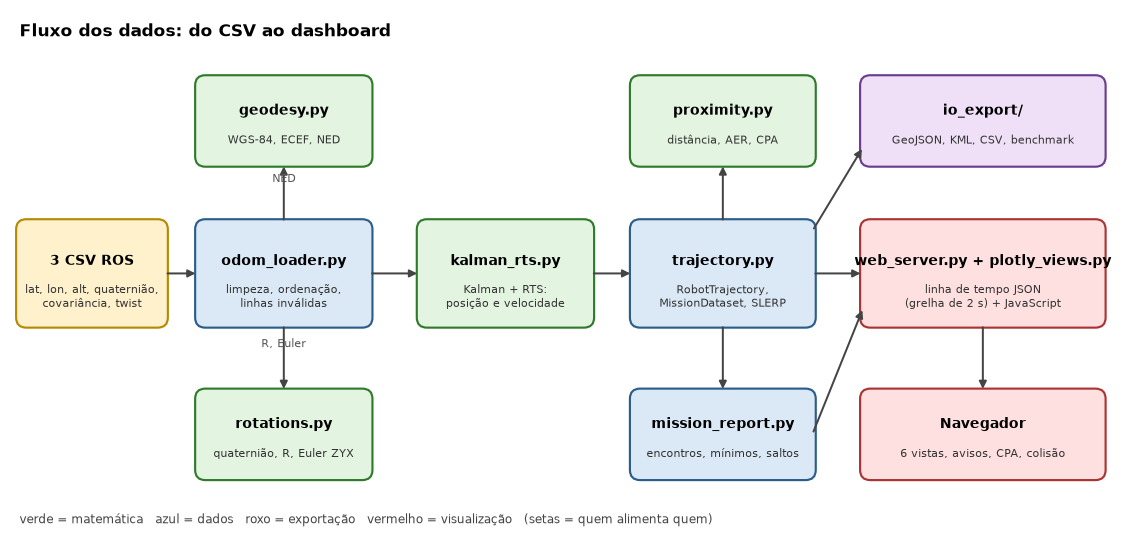

In [4]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 6.2))
ax.set_xlim(0, 13); ax.set_ylim(0, 6.2); ax.axis("off"); ax.grid(False)

def caixa(x, y, w, h, titulo, sub="", cor="#dbe9f6", borda="#2b5d8a"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc=cor, ec=borda, lw=1.4))
    ax.text(x + w / 2, y + h * (0.62 if sub else 0.5), titulo, ha="center", va="center", fontsize=9, fontweight="bold")
    if sub:
        ax.text(x + w / 2, y + h * 0.27, sub, ha="center", va="center", fontsize=7.3, color="#333")

def seta(x0, y0, x1, y1, txt=""):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color="#444", lw=1.3))
    if txt:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.13, txt, ha="center", fontsize=7, color="#555")

caixa(0.1, 2.5, 1.7, 1.2, "3 CSV ROS", "lat, lon, alt, quaternião,\ncovariância, twist", "#fff1cc", "#b58900")
caixa(2.2, 2.5, 2.0, 1.2, "odom_loader.py", "limpeza, ordenação,\nlinhas inválidas", "#dbe9f6")
caixa(2.2, 4.4, 2.0, 1.0, "geodesy.py", "WGS-84, ECEF, NED", "#e3f4e1", "#2f7a2b")
caixa(2.2, 0.7, 2.0, 1.0, "rotations.py", "quaternião, R, Euler ZYX", "#e3f4e1", "#2f7a2b")
caixa(4.8, 2.5, 2.0, 1.2, "kalman_rts.py", "Kalman + RTS:\nposição e velocidade", "#e3f4e1", "#2f7a2b")
caixa(7.3, 2.5, 2.1, 1.2, "trajectory.py", "RobotTrajectory,\nMissionDataset, SLERP", "#dbe9f6")
caixa(7.3, 4.4, 2.1, 1.0, "proximity.py", "distância, AER, CPA", "#e3f4e1", "#2f7a2b")
caixa(7.3, 0.7, 2.1, 1.0, "mission_report.py", "encontros, mínimos, saltos", "#dbe9f6")
caixa(10.0, 4.4, 2.8, 1.0, "io_export/", "GeoJSON, KML, CSV, benchmark", "#efe0f7", "#6a3d8f")
caixa(10.0, 2.5, 2.8, 1.2, "web_server.py + plotly_views.py", "linha de tempo JSON\n(grelha de 2 s) + JavaScript", "#ffe0e0", "#a33")
caixa(10.0, 0.7, 2.8, 1.0, "Navegador", "6 vistas, avisos, CPA, colisão", "#ffe0e0", "#a33")

seta(1.8, 3.1, 2.2, 3.1)
seta(3.2, 3.7, 3.2, 4.4, "NED"); seta(3.2, 2.5, 3.2, 1.7, "R, Euler")
seta(4.2, 3.1, 4.8, 3.1); seta(6.8, 3.1, 7.3, 3.1)
seta(8.35, 3.7, 8.35, 4.4); seta(8.35, 2.5, 8.35, 1.7)
seta(9.4, 3.1, 10.0, 3.1); seta(11.4, 2.5, 11.4, 1.7)
seta(9.4, 3.6, 10.0, 4.6); seta(9.4, 1.2, 10.0, 2.7)
ax.text(0.1, 5.9, "Fluxo dos dados: do CSV ao dashboard", fontsize=11, fontweight="bold")
ax.text(0.1, 0.15, "verde = matemática   azul = dados   roxo = exportação   vermelho = visualização   (setas = quem alimenta quem)", fontsize=8, color="#444")
plt.show()

## 2.2 Responsabilidade de cada módulo

| Módulo | Responsabilidade | Capítulo |
|---|---|---|
| `main.py` | Linha de comandos (`--web`, `--export`, ...), `load_mission`, `robots_from_files` | 3, 11 |
| `core/data/odom_loader.py` | Ler o CSV, limpar, converter para NED, calcular orientação, chamar o Kalman, detetar saltos | 3, 4, 5, 8 |
| `core/math/geodesy.py` | WGS-84, ECEF, NED, ENU, AER | 4 |
| `core/math/rotations.py` | Quaterniões, $\mathbf{R}\in SO(3)$, Euler ZYX, SLERP | 5 |
| `core/math/kalman_rts.py` | Filtro de Kalman, suavizador RTS, velocidade longitudinal, taxa de viragem | 7, 8 |
| `core/math/interpolators.py` | Comparação de interpoladores (linear, spline, Kalman+RTS) | 8 |
| `core/math/proximity.py` | Vetor relativo no corpo, AER, **CPA e TCPA** | 9, 10 |
| `core/data/trajectory.py` | `RobotTrajectory`, `MissionDataset` (estado no instante $t$, SLERP) | 3, 7 |
| `core/data/mission_report.py` | Encontros, mínimos por par, saltos | 9, 10 |
| `visualization/web_server.py` | Dashboard: HTML, JavaScript (rumo, distâncias, CPA, avisos, colisão), servidor HTTP | 6, 9, 10, 11 |
| `visualization/plotly_views.py` | Figuras Plotly (3D global, distâncias, casco) | 11 |
| `visualization/cockpit_view.py` | Cockpit em Plotly: **importado, mas nunca chamado**; o Cockpit real é desenhado em JavaScript | 11 |
| `io_export/` | GeoJSON, KML, CSV sincronizado, benchmark | 8, 11 |

## 2.3 Dependências entre módulos (extraídas do código)

A tabela é gerada por análise sintática (`ast`) dos ficheiros: não foi escrita à mão.

In [5]:
base = Path("multi_robot_system")
liga = []
for f in sorted(base.rglob("*.py")):
    if "tests" in f.parts or f.name == "__init__.py":
        continue
    arv = ast.parse(f.read_text(encoding="utf-8"))
    internos, externos = set(), set()
    for no in ast.walk(arv):
        if isinstance(no, ast.ImportFrom) and no.module:
            (internos if no.module.startswith("multi_robot_system") else externos).add(no.module.split(".")[-1] if no.module.startswith("multi_robot_system") else no.module.split(".")[0])
        elif isinstance(no, ast.Import):
            for n in no.names:
                externos.add(n.name.split(".")[0])
    liga.append({"Módulo": str(f.relative_to(base)), "Linhas": len(f.read_text(encoding="utf-8").splitlines()),
                 "Importa (do projeto)": ", ".join(sorted(internos)) or "-",
                 "Bibliotecas externas": ", ".join(sorted(externos - set(sys.stdlib_module_names))) or "-"})
display(pd.DataFrame(liga).set_index("Módulo"))

,Linhas,Importa (do projeto),Bibliotecas externas
Módulo,,,
core/data/mission_report.py,83,-,numpy
core/data/odom_loader.py,252,"geodesy, kalman_rts, rotations","numpy, pandas"
core/data/trajectory.py,162,proximity,"numpy, pandas, scipy"
core/math/geodesy.py,163,-,numpy
core/math/interpolators.py,114,kalman_rts,"numpy, scipy"
core/math/kalman_rts.py,172,-,numpy
core/math/proximity.py,141,-,numpy
core/math/rotations.py,123,-,numpy
io_export/benchmark_exporter.py,123,"interpolators, trajectory","matplotlib, numpy, pandas, scipy"


<a id="bibliotecas"></a>
## 2.4 Relevância das bibliotecas Python selecionadas

A contagem abaixo é feita sobre os ficheiros do projeto (código principal em `multi_robot_system`, testes incluídos): mostra **onde cada biblioteca é realmente importada**.

In [6]:
uso = {}
for f in Path("multi_robot_system").rglob("*.py"):
    arv = ast.parse(f.read_text(encoding="utf-8"))
    for no in ast.walk(arv):
        nomes = []
        if isinstance(no, ast.ImportFrom) and no.module:
            nomes = [no.module.split(".")[0]]
        elif isinstance(no, ast.Import):
            nomes = [n.name.split(".")[0] for n in no.names]
        for n in nomes:
            if n in {"numpy", "pandas", "scipy", "plotly", "yaml", "matplotlib", "pymap3d", "pyproj", "pytest"}:
                uso.setdefault(n, set()).add(str(f.relative_to("multi_robot_system")))
pyproj_legado = any("pyproj" in p.read_text(encoding="utf-8") for p in Path("tests").glob("*.py"))
req = [l.strip() for l in Path("requirements.txt").read_text().splitlines() if l.strip()]
linhas = []
for lib in ["numpy", "scipy", "pandas", "yaml", "plotly", "matplotlib", "pymap3d", "pyproj", "pytest"]:
    ficheiros = sorted(uso.get(lib, []))
    linhas.append({"Biblioteca": lib, "Ficheiros do código principal que a importam": len(ficheiros),
                   "Exemplos": ", ".join(ficheiros[:3]) or ("só nos testes do código legado (tests/)" if lib == "pyproj" and pyproj_legado else "-")})
display(pd.DataFrame(linhas).set_index("Biblioteca"))
print("requirements.txt:", ", ".join(req))

,Ficheiros do código principal que a importam,Exemplos
Biblioteca,,
numpy,20,"core/data/mission_report.py, core/data/odom_lo..."
scipy,4,"core/data/trajectory.py, core/math/interpolato..."
pandas,4,"core/data/odom_loader.py, core/data/trajectory..."
yaml,1,main.py
plotly,3,"visualization/cockpit_view.py, visualization/p..."
matplotlib,1,io_export/benchmark_exporter.py
pymap3d,1,tests/test_geodesy.py
pyproj,0,só nos testes do código legado (tests/)
pytest,4,"tests/test_cpa.py, tests/test_geodesy.py, test..."


requirements.txt: numpy>=1.24.0, pandas>=2.0.0, matplotlib>=3.7.0, pyyaml>=6.0, pymap3d>=3.0.0, pyproj>=3.5.0, scipy>=1.10.0, pytest>=7.0.0, plotly>=5.18.0


| Biblioteca | Papel no projeto | Justificação |
|---|---|---|
| **NumPy** | Toda a álgebra linear: matrizes de rotação, Kalman, distâncias | Operações vetorizadas sobre milhares de amostras (por exemplo, $N$ matrizes $3\times3$ de uma só vez em `quaternion_to_rotation_matrix`) e multiplicação matricial `@`. |
| **SciPy** | `CubicSpline` (interpoladores), `Rotation` e `Slerp` (`trajectory.py`) | Interpolação esférica de quaterniões e spline de referência, implementações validadas. |
| **pandas** | Leitura dos CSV, limpeza (`to_numeric`, `sort_values`), tabelas de resultados | Leitura robusta de ficheiros de 20 MB com tipos inferidos e tratamento de valores em falta. |
| **PyYAML** | Leitura de `mission_config.yaml` | Configuração legível e editável sem mexer no código. |
| **Plotly** | Figuras 3D e de distâncias do dashboard (`plotly_views.py`), motor `plotly.js` no navegador | Gráficos 3D interativos sem instalar nada no cliente além de um navegador. |
| **Matplotlib** | Figura do benchmark (`benchmark_exporter.py`), código legado e **este relatório** | Gráficos estáticos que ficam gravados no notebook. |
| **pymap3d** | **Só nos testes**: referência independente para validar `geodesy.py` | Autoridade externa para a conversão geodésica (o projeto implementa as fórmulas de raiz). |
| **pyproj** | **Só nos testes do código legado** (`tests/test_coordinates.py`) | Idem. |
| **pytest** | Suite de testes automáticos | 32 testes do código principal e 26 do legado. |

<a id="cap3"></a>
# CAPÍTULO 3 — TRATAMENTO DOS DADOS

## 3.1 Variáveis disponíveis

Cada CSV tem 21 colunas. O programa usa apenas as que a tabela abaixo marca como *obrigatória* ou *opcional*; o resto é ignorado. Os valores são os da primeira linha do ficheiro do Robot 1.

In [7]:
from multi_robot_system.core.data.odom_loader import (
    ODOM_REQUIRED_COLS, load_single_robot_csv, parse_covariance_diagonal,
    parse_declared_horizontal_sigma, detect_position_jumps)

df1 = pd.read_csv("multi_robot_system/data/robot1_s1.csv")
opcionais = ["pose.covariance", "twist.twist.linear.x", "twist.twist.linear.y", "twist.twist.linear.z"]
unid = {"Time": "s (POSIX)", "pose.pose.position.x": "graus (latitude)", "pose.pose.position.y": "graus (longitude)",
        "pose.pose.position.z": "m (altura elipsoidal)", "pose.covariance": "m², rad² (36 valores)",
        "twist.twist.linear.x": "m por s (corpo)", "twist.twist.linear.y": "m por s (corpo)", "twist.twist.linear.z": "m por s (corpo)"}
for c in ["x", "y", "z", "w"]:
    unid[f"pose.pose.orientation.{c}"] = "adimensional"
linhas = []
for c in df1.columns:
    papel = "obrigatória" if c in ODOM_REQUIRED_COLS else ("opcional" if c in opcionais else "ignorada")
    v = df1[c].iloc[0]
    linhas.append({"Coluna": c, "Papel": papel, "Unidade": unid.get(c, "-"), "1.ª linha": (str(v)[:38] + "...") if len(str(v)) > 40 else v})
display(pd.DataFrame(linhas).set_index("Coluna"))
print("frame_id / child_frame_id:", df1["header.frame_id"].iloc[0], "/", df1["child_frame_id"].iloc[0])

,Papel,Unidade,1.ª linha
Coluna,,,
Time,obrigatória,s (POSIX),1760097600.23955
header.seq,ignorada,-,73453
header.stamp.secs,ignorada,-,1760097600
header.stamp.nsecs,ignorada,-,93045711
header.frame_id,ignorada,-,world_ned
child_frame_id,ignorada,-,body
pose.pose.position.x,obrigatória,graus (latitude),41.452437
pose.pose.position.y,obrigatória,graus (longitude),-8.812361
pose.pose.position.z,obrigatória,m (altura elipsoidal),56.732758


frame_id / child_frame_id: world_ned / body


**Significado das grandezas usadas**

| Grandeza | Colunas | Tipo |
|---|---|---|
| **Tempo** | `Time` | medido |
| **Posição** | latitude $\varphi$, longitude $\lambda$, altura $h$ | medidas (estimadas a bordo pelo robô) |
| **Orientação** | quaternião $(q_x,q_y,q_z,q_w)$ | medida |
| **Velocidade (corpo)** | `twist.twist.linear` $(u,v,w)$ | medida |
| **Incerteza** | `pose.covariance`, diagonal de posição | medida |

## 3.2 Qualidade dos ficheiros originais

Antes de qualquer tratamento, verifica-se o estado dos ficheiros reais: valores em falta, instantes repetidos e ordenação.

In [8]:
linhas = []
for r, f in [("Robot 1", "robot1_s1"), ("Robot 4", "robot4_s1"), ("Robot 7", "robot7_s1")]:
    d = pd.read_csv(f"multi_robot_system/data/{f}.csv")
    t = d["Time"].values
    obrig = d[ODOM_REQUIRED_COLS]
    linhas.append({"Robô": r, "Linhas": len(d), "Valores em falta (colunas usadas)": int(obrig.isna().sum().sum()),
                   "Instantes repetidos": int((np.diff(t) <= 0).sum()), "Já ordenado": bool(np.all(np.diff(t) >= 0)),
                   "Passo mediano (s)": float(np.median(np.diff(t))), "Passo máximo (s)": float(np.max(np.diff(t))),
                   "Norma do quaternião (mín.)": float(np.sqrt((obrig.iloc[:, 4:8] ** 2).sum(axis=1)).min()),
                   "Norma do quaternião (máx.)": float(np.sqrt((obrig.iloc[:, 4:8] ** 2).sum(axis=1)).max())})
display(pd.DataFrame(linhas).set_index("Robô").round(6))
print("Início da missão (UTC):", pd.to_datetime(T0, unit="s", utc=True))

,Linhas,Valores em falta (colunas usadas),Instantes repetidos,Já ordenado,Passo mediano (s),Passo máximo (s),Norma do quaternião (mín.),Norma do quaternião (máx.)
Robô,,,,,,,,
Robot 1,9537,0,0,True,0.533978,0.547607,1.0,1.0
Robot 4,5615,0,0,True,0.533944,0.544263,1.0,1.0
Robot 7,15000,0,0,True,0.534162,0.547820,1.0,1.0


Início da missão (UTC): 2025-10-10 11:30:00.973070860+00:00


**Leitura.** Os ficheiros fornecidos **não têm** valores em falta nem instantes repetidos, estão ordenados e os quaterniões já são unitários. O programa não depende disso: trata também ficheiros imperfeitos (por exemplo, um CSV novo que o docente possa fornecer).

## 3.3 O percurso dos dados até ao `RobotTrajectory` (código real)

A função `load_single_robot_csv` faz, por esta ordem: (1) validar o cabeçalho; (2) converter as colunas obrigatórias para número e **ignorar linhas inválidas**; (3) ordenar por tempo; (4) afastar 1 milissegundo os **instantes repetidos**; (5) converter para NED; (6) tratar a orientação; (7) extrair a covariância; (8) correr Kalman e RTS; (9) ler a velocidade medida e detetar saltos. Os passos 2 a 4 são:

In [9]:
mostrar_codigo(load_single_robot_csv, de="# Linhas com valores em falta", ate='df["Time"] = tempos')

# multi_robot_system/core/data/odom_loader.py, linhas 150 a 169
 150      # Linhas com valores em falta ou ilegíveis nas colunas obrigatórias são ignoradas (e contadas no aviso)
 151      df[ODOM_REQUIRED_COLS] = df[ODOM_REQUIRED_COLS].apply(pd.to_numeric, errors="coerce")
 152      validas = np.isfinite(df[ODOM_REQUIRED_COLS].values).all(axis=1)
 153      if not validas.all():
 154          print(f"     [AVISO] {path.name}: {int((~validas).sum())} linhas com valores em falta foram ignoradas")
 155          df = df[validas]
 156      if len(df) < 2:
 157          raise ValueError(f"Ficheiro {path.name}: menos de 2 linhas válidas")
 158  
 159      # Ordenação estrita por tempo (preservando registos repetidos conforme Q23)
 160      df = df.sort_values(by="Time", kind="stable").reset_index(drop=True)
 161  
 162      # Registos com o mesmo instante ficam todos, afastados 1 ms (a interpolação exige tempos estritamente crescentes)
 163      tempos = df["Time"].values.astype(float)
 164   

**Explicação linha a linha**

- `df[ODOM_REQUIRED_COLS].apply(pd.to_numeric, errors="coerce")`: qualquer texto ilegível passa a `NaN`.
- `validas = np.isfinite(...).all(axis=1)`: uma linha só é válida se **as 8 colunas obrigatórias** forem finitas. As inválidas são removidas e contadas no aviso `[AVISO] ... linhas com valores em falta foram ignoradas`.
- `sort_values(by="Time", kind="stable")`: ordenação **estável**: registos com o mesmo instante mantêm a ordem original.
- O ciclo `for i in range(1, len(tempos))` garante tempos **estritamente crescentes** (soma 1 ms ao instante repetido). É necessário porque a interpolação SLERP e o filtro de Kalman exigem $t_k > t_{k-1}$.

## 3.4 Demonstração com um CSV deliberadamente sujo

Pega-se nas primeiras 400 linhas do Robot 4, introduz-se um valor em falta, três registos repetidos e dois registos fora de ordem, e passa-se tudo pela **função real** do projeto. Esta demonstração usa uma pasta temporária; os ficheiros originais não são tocados.

In [10]:
original = pd.read_csv("multi_robot_system/data/robot4_s1.csv").iloc[:400].copy()
sujo = original.copy()
sujo.loc[5, "pose.pose.position.x"] = np.nan                       # 1 valor em falta
sujo = pd.concat([sujo, original.iloc[10:13]])                      # 3 registos repetidos
sujo = pd.concat([sujo.iloc[:50], sujo.iloc[52:53], sujo.iloc[50:52], sujo.iloc[53:]])   # 2 linhas fora de ordem
with tempfile.TemporaryDirectory() as tmp:
    caminho = Path(tmp) / "sujo.csv"
    sujo.to_csv(caminho, index=False)
    res = load_single_robot_csv(str(caminho), "Robot 4", "Robot 4", "#2A9D8F", 41.4523, -8.8125, 56.5)
t = res["timestamps"]
print(f"\nLinhas no ficheiro sujo: {len(sujo)}  ->  linhas depois do tratamento: {len(t)}")
print("Tempos estritamente crescentes:", bool(np.all(np.diff(t) > 0)))
print("Posições todas finitas:", bool(np.all(np.isfinite(res['pos_ned']))))
print(f"Menor passo de tempo: {np.diff(t).min()*1000:.2f} ms (os repetidos foram afastados 1 ms)")

     [AVISO] sujo.csv: 1 linhas com valores em falta foram ignoradas
     [AVISO] sujo.csv: 3 registos com instante repetido foram afastados 1 ms

Linhas no ficheiro sujo: 403  ->  linhas depois do tratamento: 402
Tempos estritamente crescentes: True
Posições todas finitas: True
Menor passo de tempo: 1.00 ms (os repetidos foram afastados 1 ms)


**Interpretação.** 400 linhas originais, menos 1 inválida, mais 3 repetidas, dão 402: as 3 repetidas **ficam** (afastadas 1 ms) e a inválida sai. É exatamente o que o teste automático `test_instantes_repetidos_e_linhas_em_falta` verifica.

## 3.5 Conversões e unidades

| Passo | De | Para | Onde |
|---|---|---|---|
| Posição | $(\varphi,\lambda,h)$ em graus e metros (WGS-84) | $(N,E,D)$ em metros (NED) | `geodetic_to_ned` (Capítulo 4) |
| Orientação | $(q_x,q_y,q_z,q_w)$ | $\mathbf{R}$ ($3\times3$) e $(\text{roll},\text{pitch},\text{yaw})$ em graus | `rotations.py` (Capítulo 5) |
| Tempo | segundos POSIX | segundos desde o início da missão | `trajectory.py` (`t0_mission`) |
| Incerteza | covariância ROS (36 valores) | desvios-padrão $\sigma_N,\sigma_E,\sigma_D$ em metros | `parse_covariance_diagonal` |

## 3.6 Incerteza de medição

A covariância ROS é uma matriz $6\times6$ guardada por linhas num texto. A posição $(x,y,z)$ ocupa os elementos 0, 7 e 14 (diagonal). O código extrai a raiz quadrada com um **mínimo de variância de 0,001 m²** e, depois, o filtro de Kalman ainda **limita** $\sigma$ ao intervalo $[0{,}05;\,20]$ m.

In [11]:
mostrar_codigo(parse_covariance_diagonal)
print()
entrada = df1["pose.covariance"].iloc[0]
partes = entrada.strip("() \n\r\t").split(",")
print("Elementos 0, 7, 14 da covariância (1.ª linha do Robot 1):", [float(partes[i]) for i in (0, 7, 14)], "m²")
print("-> sigma extraído por parse_covariance_diagonal:", parse_covariance_diagonal(df1['pose.covariance'].iloc[:1])[0])
print("-> sigma horizontal declarado (sem mínimos):", parse_declared_horizontal_sigma(df1['pose.covariance'].iloc[:1])[0])

# O que o filtro de Kalman realmente recebe como incerteza (depois do clip [0.05, 20])
linhas = []
for r, f in [("Robot 1", "robot1_s1"), ("Robot 4", "robot4_s1"), ("Robot 7", "robot7_s1")]:
    d = pd.read_csv(f"multi_robot_system/data/{f}.csv", usecols=["pose.covariance"])
    s = parse_covariance_diagonal(d["pose.covariance"])
    ef = np.clip(s, 0.05, 20.0)
    linhas.append({"Robô": r, "sigma extraído mediano (m)": float(np.median(s)),
                   "sigma usado no Kalman, mínimo (m)": float(ef.min()), "sigma usado no Kalman, máximo (m)": float(ef.max()),
                   "amostras no limite inferior 0,05 m (%)": 100 * float(np.mean(ef[:, 0] <= 0.05 + 1e-12))})
display(pd.DataFrame(linhas).set_index("Robô").round(4))

# multi_robot_system/core/data/odom_loader.py, linhas 39 a 59
  39  def parse_covariance_diagonal(cov_series: pd.Series) -> np.ndarray:
  40      """Extrai os desvios-padrão [sigma_x, sigma_y, sigma_z] a partir da diagonal da covariância (36 elementos)."""
  41      stds = []
  42      for entry in cov_series:
  43          if not isinstance(entry, str):
  44              stds.append([0.8, 0.8, 0.8])
  45              continue
  46          clean = entry.strip("() \n\r\t")
  47          parts = clean.split(",")
  48          try:
  49              var_x = float(parts[0])
  50              var_y = float(parts[7])
  51              var_z = float(parts[14])
  52              stds.append([
  53                  float(np.sqrt(max(0.001, var_x))),
  54                  float(np.sqrt(max(0.001, var_y))),
  55                  float(np.sqrt(max(0.001, var_z)))
  56              ])
  57          except (IndexError, ValueError):
  58              stds.append([0.8, 0.8, 0.8])
  59      return np.

,sigma extraído mediano (m),"sigma usado no Kalman, mínimo (m)","sigma usado no Kalman, máximo (m)","amostras no limite inferior 0,05 m (%)"
Robô,,,,
Robot 1,0.0616,0.05,0.1378,17.6156
Robot 4,0.0555,0.05,0.1174,19.0739
Robot 7,0.0914,0.05,0.3906,37.4800


**Resultado importante.** No início do Robot 1, a covariância declarada é minúscula (variância de $1{,}7\times10^{-5}$ m², isto é, desvio-padrão de 4 mm), mas o código impõe um mínimo de 0,001 m² (desvio-padrão de 3,2 cm) e, depois, o `clip` do Kalman sobe-o para 5 cm. Ao longo dos três ficheiros, o desvio-padrão extraído tem mediana de 5,5 a 9,1 cm e, depois do `clip`, máximo de 0,12 a 0,39 m; o limite inferior de 0,05 m é o que vale em **18% a 37%** das amostras. Em qualquer caso, o filtro recebe incertezas de **poucos centímetros a poucos decímetros**: confia muito nas medições de posição e, por isso, altera pouco as posições (o efeito é quantificado na secção 8.5).

## 3.7 Interpolação

Há três interpolações diferentes no projeto, todas explícitas:

| Onde | O quê | Método |
|---|---|---|
| `MissionDataset.get_state_at_time` | posição, velocidade, velocidade longitudinal, taxa de viragem | linear por partes (`np.interp`) |
| idem | **atitude** | **SLERP** (`scipy.spatial.transform.Slerp`) |
| `web_server.py` | tudo, no navegador | grelha de 2 s, `np.interp` em Python e `valueAt` (linear) em JavaScript |

In [12]:
mostrar_codigo(type(ds).get_state_at_time, de="# Posições NED interpoladas", ate="R_mat = rot.as_matrix()[0]")

# multi_robot_system/core/data/trajectory.py, linhas 101 a 115
 101              # Posições NED interpoladas
 102              N = float(np.interp(t, traj.timestamps, traj.pos_ned[0]))
 103              E = float(np.interp(t, traj.timestamps, traj.pos_ned[1]))
 104              D = float(np.interp(t, traj.timestamps, traj.pos_ned[2]))
 105  
 106              # Velocidades interpoladas
 107              vN = float(np.interp(t, traj.timestamps, traj.vel_ned[0]))
 108              vE = float(np.interp(t, traj.timestamps, traj.vel_ned[1]))
 109              vD = float(np.interp(t, traj.timestamps, traj.vel_ned[2]))
 110  
 111              # Atitude por SLERP
 112              rot = self._slerp_interpolators[r_id]([t])
 113              quat = rot.as_quat()[0]  # [qx, qy, qz, qw]
 114              euler = rot.as_euler("xyz", degrees=True)[0]  # [roll, pitch, yaw]
 115              R_mat = rot.as_matrix()[0]


In [13]:
# Exemplo numérico: interpolar à mão a coordenada Norte do Robot 1 entre duas amostras reais
tr = ds.trajectories["Robot 1"]
k = 4000
t_a, t_b = tr.timestamps[k], tr.timestamps[k + 1]
t = t_a + 0.3 * (t_b - t_a)                      # 30% do caminho entre as duas amostras
N_a, N_b = tr.pos_ned[0, k], tr.pos_ned[0, k + 1]
manual = N_a + (N_b - N_a) * (t - t_a) / (t_b - t_a)
print(f"N[k]={N_a:.5f} m, N[k+1]={N_b:.5f} m, t entre elas a 30%")
print(f"Interpolação manual N(t) = {manual:.5f} m")
print(f"np.interp (o que o código faz) = {np.interp(t, tr.timestamps, tr.pos_ned[0]):.5f} m")
print(f"get_state_at_time(...)['Robot 1']['pos_ned'][0] = {ds.get_state_at_time(t)['Robot 1']['pos_ned'][0]:.5f} m")

N[k]=140.22730 m, N[k+1]=140.49094 m, t entre elas a 30%
Interpolação manual N(t) = 140.30639 m
np.interp (o que o código faz) = 140.30639 m
get_state_at_time(...)['Robot 1']['pos_ned'][0] = 140.30639 m


## 3.8 Saltos de posição (valores anómalos)

Nem todos os valores inválidos são `NaN`: alguns são posições fisicamente impossíveis. `detect_position_jumps` marca como salto qualquer passo cuja **velocidade implícita** $\dfrac{\|\Delta\mathbf{p}\|}{\Delta t}$ seja superior a **2,5 m por segundo** (estes robôs andam abaixo de 1 m por segundo); amostras seguidas a menos de 5 s contam como um só evento.

In [14]:
mostrar_codigo(detect_position_jumps)
linhas = []
for r in IDS:
    for e in ds.trajectories[r].jump_events:
        linhas.append({"Robô": r, "Instante da missão": tmiss(e["t"]), "Salto (m)": e["m"], "Profundidade (m)": e["depth_m"],
                       "Estado": "imerso" if e["depth_m"] > 3 else "à superfície"})
print()
display(pd.DataFrame(linhas).set_index("Robô").round(2))

# multi_robot_system/core/data/odom_loader.py, linhas 76 a 105
  76  def detect_position_jumps(timestamps: np.ndarray, pos_ned_raw: np.ndarray,
  77                            max_speed_m_s: float = 2.5, group_s: float = 5.0) -> List[Dict]:
  78      """Saltos de posição no registo bruto: velocidade implícita acima de max_speed_m_s (estes robots andam a menos de 1 m/s).
  79  
  80      Amostras seguidas a menos de group_s segundos contam como um só evento. m = distância total saltada [m].
  81      """
  82      t = np.asarray(timestamps, dtype=float)
  83      if len(t) < 3:
  84          return []
  85      dt = np.diff(t)
  86      step = np.linalg.norm(np.diff(pos_ned_raw, axis=1), axis=0)
  87      ok = dt > 1e-6
  88      idx = np.where(ok & (step / np.where(ok, dt, 1.0) > max_speed_m_s))[0]
  89      groups, cur = [], []
  90      for j in idx:
  91          if cur and t[j] - t[cur[-1]] > group_s:
  92              groups.append(cur)
  93              cur = []
  94          cur

,Instante da missão,Salto (m),Profundidade (m),Estado
Robô,,,,
Robot 1,111m 55.6s,17.60,-0.29,à superfície
Robot 1,112m 4.1s,5.50,-0.23,à superfície
Robot 4,69m 1.6s,3.18,-0.23,à superfície
Robot 7,66m 46.4s,27.72,30.77,imerso
Robot 7,114m 54.3s,44.64,2.16,à superfície


**Interpretação.** Há 5 saltos nos dados reais: dois do Robot 1, um do Robot 4 e dois do Robot 7. Quatro dos cinco acontecem com o robô **à superfície** (profundidade abaixo de 3 m) e um, do Robot 7, a cerca de 30,8 m de profundidade (imerso). Os dados não dizem qual a causa; o programa **não corrige** estes saltos, apenas os assinala (Cockpit e relatório).

<a id="cap4"></a>
# CAPÍTULO 4 — SISTEMAS DE COORDENADAS

## 4.1 O problema

A posição chega em **graus** (latitude e longitude) e a altura em metros, referidas a um elipsoide. Para medir distâncias, somar vetores e rodar com matrizes é preciso um referencial **cartesiano em metros**. O programa usa três referenciais:

| Referencial | Eixos | Onde |
|---|---|---|
| **WGS-84 geodésico** $(\varphi,\lambda,h)$ | latitude, longitude, altura elipsoidal | entrada (CSV) |
| **ECEF** (*Earth-Centered, Earth-Fixed*) | $X,Y,Z$ com origem no centro da Terra | passo intermédio |
| **NED** (referencial **global** do programa) | $N$ Norte, $E$ Este, $D$ *Down* (para baixo) | todo o resto |
| **Corpo do robô** (referencial **local**) | $x$ proa, $y$ estibordo (direita), $z$ quilha (baixo) | vizinhos, vistas |

Em NED a profundidade é $D$ positivo para baixo, o que dá profundidades positivas (0 m na superfície). Não há referencial "ENU" em uso no dashboard (a função `geodetic_to_enu` existe no módulo mas o carregador usa NED).

## 4.2 Fundamentação: de WGS-84 para ECEF

O elipsoide WGS-84 tem semieixo maior $a = 6\,378\,137{,}0$ m e achatamento $f = 1/298{,}257223563$. A excentricidade ao quadrado é $e^2 = 2f - f^2$. O **raio de curvatura na vertical principal** é

$$N(\varphi) = \frac{a}{\sqrt{1 - e^2\sin^2\varphi}}$$

e as coordenadas ECEF de um ponto $(\varphi,\lambda,h)$ são

$$X = (N+h)\cos\varphi\cos\lambda,\qquad Y = (N+h)\cos\varphi\sin\lambda,\qquad Z = \big(N(1-e^2)+h\big)\sin\varphi .$$

## 4.3 De ECEF para NED

Dada uma origem local $(\varphi_0,\lambda_0,h_0)$, com ECEF $(X_0,Y_0,Z_0)$, o vetor diferença $\Delta=(X-X_0,\;Y-Y_0,\;Z-Z_0)^{T}$ é rodado para o plano tangente local:

$$\begin{bmatrix} N\\E\\D\end{bmatrix} = \mathbf{R}_{e}^{n}\,\Delta,\qquad
\mathbf{R}_{e}^{n} = \begin{bmatrix}
-\sin\varphi_0\cos\lambda_0 & -\sin\varphi_0\sin\lambda_0 & \cos\varphi_0\\
-\sin\lambda_0 & \cos\lambda_0 & 0\\
-\cos\varphi_0\cos\lambda_0 & -\cos\varphi_0\sin\lambda_0 & -\sin\varphi_0
\end{bmatrix}$$

As três linhas são os versores Norte, Este e *Down* escritos em ECEF. A matriz é ortogonal com determinante $+1$.

## 4.4 Código real

In [15]:
from multi_robot_system.core.math import geodesy as G
mostrar_codigo(G.geodetic_to_ecef)
print()
mostrar_codigo(G.ecef_to_ned)
print()
mostrar_codigo(G.geodetic_to_ned)

# multi_robot_system/core/math/geodesy.py, linhas 30 a 46
  30  def geodetic_to_ecef(
  31      lat_deg: Union[float, np.ndarray],
  32      lon_deg: Union[float, np.ndarray],
  33      h: Union[float, np.ndarray]
  34  ) -> Tuple[Union[float, np.ndarray], Union[float, np.ndarray], Union[float, np.ndarray]]:
  35      """Converte coordenadas geodésicas (latitude, longitude em graus, altura elipsoidal em m)
  36  
  37      para o referencial cartesiano geocêntrico ECEF (X, Y, Z em metros).
  38      """
  39      lat_rad = np.radians(lat_deg)
  40      lon_rad = np.radians(lon_deg)
  41      N = WGS84_A / np.sqrt(1.0 - WGS84_E2 * np.sin(lat_rad)**2)
  42  
  43      X = (N + h) * np.cos(lat_rad) * np.cos(lon_rad)
  44      Y = (N + h) * np.cos(lat_rad) * np.sin(lon_rad)
  45      Z = (N * (1.0 - WGS84_E2) + h) * np.sin(lat_rad)
  46      return X, Y, Z

# multi_robot_system/core/math/geodesy.py, linhas 72 a 97
  72  def ecef_to_ned(
  73      X: Union[float, np.ndarray],
  74      Y: U

**Explicação.** `geodetic_to_ecef` é a transcrição direta das três equações da secção 4.2 (`N` é o raio de curvatura, `WGS84_E2` é $e^2$). `ecef_to_ned` calcula a origem em ECEF, subtrai, e aplica as três linhas de $\mathbf{R}_e^n$ **escritas por extenso** (`N = -s_phi*c_lam*dX - ...`); `geodetic_to_ned` é a composição das duas. Todas as funções aceitam *arrays* de NumPy, por isso as 15 000 amostras de um robô são convertidas numa só chamada.

## 4.5 Origem do referencial local

O NED precisa de uma origem. A configuração tem duas opções (`mission_config.yaml`, secção `origin`): `data_mean` (por omissão), em que a origem vem **dos dados**, e `fixed`, que usa a "Surface Reference" do enunciado.

In [16]:
from multi_robot_system.core.data.odom_loader import compute_reference_origin
mostrar_codigo(compute_reference_origin)
og = cfg["origin_resolved"]
lat0, lon0, h0 = og["latitude"], og["longitude"], og["altitude"]
print(f"\nOrigem em uso (modo {og['mode']}): lat0={lat0:.6f}°, lon0={lon0:.6f}°, h0={h0:.2f} m")

# Distância entre a origem dos dados e a Surface Reference oficial do enunciado
ref = cfg["origin"]
n_, e_, d_ = G.geodetic_to_ned(ref["latitude"], ref["longitude"], ref["altitude"], lat0, lon0, h0)
print(f"Surface Reference oficial vista da origem dos dados: N={n_:.1f} m, E={e_:.1f} m, D={d_:.1f} m (distância horizontal {np.hypot(n_, e_):.1f} m)")

# A distância entre dois pontos depende da origem? (1.as amostras de Robot 1 e Robot 4, duas origens)
b4 = pd.read_csv("multi_robot_system/data/robot4_s1.csv", nrows=1).iloc[0]
a1 = pd.read_csv("multi_robot_system/data/robot1_s1.csv", nrows=1).iloc[0]
def dist_com_origem(o):
    pa = np.array(G.geodetic_to_ned(a1["pose.pose.position.x"], a1["pose.pose.position.y"], a1["pose.pose.position.z"], *o))
    pb = np.array(G.geodetic_to_ned(b4["pose.pose.position.x"], b4["pose.pose.position.y"], b4["pose.pose.position.z"], *o))
    return np.linalg.norm(pa - pb)
d_a = dist_com_origem((lat0, lon0, h0)); d_b = dist_com_origem((ref["latitude"], ref["longitude"], ref["altitude"]))
print(f"Distância entre 1.as amostras de R1 e R4: origem dos dados = {d_a:.6f} m; origem oficial = {d_b:.6f} m; diferença = {abs(d_a-d_b)*1000:.4f} mm")

# multi_robot_system/core/data/odom_loader.py, linhas 108 a 120
 108  def compute_reference_origin(file_paths: List[str]) -> Tuple[float, float, float]:
 109      """Origem local calculada a partir dos dados, igual à do visualizador de referência (trajectories/).
 110  
 111      - lat0, lon0: média de todas as amostras de todos os robôs.
 112      - h_ref (superfície da água): média, entre robôs, da mediana das primeiras 50 amostras de altura.
 113      """
 114      lats, lons, h_refs = [], [], []
 115      for fp in file_paths:
 116          df = pd.read_csv(fp, usecols=["pose.pose.position.x", "pose.pose.position.y", "pose.pose.position.z"])
 117          lats.append(df["pose.pose.position.x"].values)
 118          lons.append(df["pose.pose.position.y"].values)
 119          h_refs.append(float(df["pose.pose.position.z"].iloc[:50].median()))
 120      return float(np.nanmean(np.concatenate(lats))), float(np.nanmean(np.concatenate(lons))), float(np.nanmean(h_refs))

Origem em uso (m

**Interpretação.** A origem é só um ponto de referência: mudá-la desloca as coordenadas e, a esta escala (centenas de metros), altera as distâncias entre robôs em frações de milímetro (resultado acima). A escolha `data_mean` dá coordenadas menores nas vistas e é praticamente inócua para as análises de proximidade.

## 4.6 Exemplo numérico real: a primeira amostra do Robot 1

Seguem-se, passo a passo, as equações das secções 4.2 e 4.3 aplicadas a um ponto real, comparadas com a função do projeto e com a biblioteca independente `pymap3d`.

In [17]:
lat, lon, h = [float(df1[c].iloc[0]) for c in ("pose.pose.position.x", "pose.pose.position.y", "pose.pose.position.z")]
print(f"Amostra: lat={lat:.10f}°, lon={lon:.10f}°, h={h:.4f} m")

# 1) raio de curvatura e ECEF, equação a equação
fi, la = np.radians(lat), np.radians(lon)
Nfi = G.WGS84_A / np.sqrt(1 - G.WGS84_E2 * np.sin(fi) ** 2)
X = (Nfi + h) * np.cos(fi) * np.cos(la); Y = (Nfi + h) * np.cos(fi) * np.sin(la); Z = (Nfi * (1 - G.WGS84_E2) + h) * np.sin(fi)
print(f"N(phi) = {Nfi:.4f} m   ->   ECEF = ({X:.4f}, {Y:.4f}, {Z:.4f}) m")

# 2) ECEF da origem e diferença
fi0, la0 = np.radians(lat0), np.radians(lon0)
N0 = G.WGS84_A / np.sqrt(1 - G.WGS84_E2 * np.sin(fi0) ** 2)
X0 = (N0 + h0) * np.cos(fi0) * np.cos(la0); Y0 = (N0 + h0) * np.cos(fi0) * np.sin(la0); Z0 = (N0 * (1 - G.WGS84_E2) + h0) * np.sin(fi0)
delta = np.array([X - X0, Y - Y0, Z - Z0])
print("Delta ECEF (m):", delta)

# 3) matriz R_e^n e rotação
sf, cf, sl, cl = np.sin(fi0), np.cos(fi0), np.sin(la0), np.cos(la0)
Ren = np.array([[-sf * cl, -sf * sl, cf], [-sl, cl, 0.0], [-cf * cl, -cf * sl, -sf]])
print("\nR_e^n =\n", Ren)
print("R R^T - I (deve ser ~0):", np.abs(Ren @ Ren.T - np.eye(3)).max(), "   det(R) =", round(np.linalg.det(Ren), 12))
ned_manual = Ren @ delta
ned_proj = np.array(G.geodetic_to_ned(lat, lon, h, lat0, lon0, h0))
print("\nNED à mão     :", ned_manual)
print("NED do projeto:", ned_proj, "   diferença máx.:", np.abs(ned_manual - ned_proj).max(), "m")

try:
    import pymap3d as pm
    ned_ref = np.array(pm.geodetic2ned(lat, lon, h, lat0, lon0, h0))
    print("NED pymap3d   :", ned_ref, "   diferença máx. vs projeto:", np.abs(ned_ref - ned_proj).max(), "m")
except ImportError:
    print("pymap3d não instalado (só é usada como referência de teste).")
# comparação com o valor guardado na trajetória (1.ª amostra bruta)
print("Valor guardado em RobotTrajectory.pos_ned_raw[:, 0]:", ds.trajectories["Robot 1"].pos_ned_raw[:, 0])
print(f"Distância horizontal da 1.ª amostra à origem: {np.hypot(ned_proj[0], ned_proj[1]):.1f} m")

Amostra: lat=41.4524366842°, lon=-8.8123612694°, h=56.7328 m
N(phi) = 6387513.5818 m   ->   ECEF = (4731004.2824, -733443.3445, 4200251.9815) m
Delta ECEF (m): [-6.69819 16.48399 10.76918]

R_e^n =
 [[-0.65418  0.10142  0.74951]
 [ 0.1532   0.98819  0.     ]
 [-0.74066  0.11483 -0.662  ]]
R R^T - I (deve ser ~0): 1.1102230246251565e-16    det(R) = 1.0

NED à mão     : [14.1252  15.26322 -0.27529]
NED do projeto: [14.1252  15.26322 -0.27529]    diferença máx.: 0.0 m
NED pymap3d   : [14.1252  15.26322 -0.27529]    diferença máx. vs projeto: 1.3196927994840735e-09 m
Valor guardado em RobotTrajectory.pos_ned_raw[:, 0]: [14.1252  15.26322 -0.27529]
Distância horizontal da 1.ª amostra à origem: 20.8 m


**Interpretação.** O cálculo à mão (equações escritas diretamente) reproduz a função do projeto ao nível do erro de arredondamento (da ordem de $10^{-9}$ m ou menos) e coincide com o `pymap3d`. A matriz $\mathbf{R}_e^n$ confirma-se ortogonal com determinante 1.

## 4.7 O referencial local do robô

Cada robô tem o seu referencial: $x$ para a proa, $y$ para estibordo, $z$ para baixo (em NED, com o robô direito, a quilha aponta para $D$ positivo). Se $\mathbf{R}_i$ for a matriz do corpo do robô $i$ para NED (Capítulo 5), a posição do robô $j$ vista do robô $i$ é

$$\mathbf{p}_j^{(i)} = \mathbf{R}_i^{T}\,\big(\mathbf{p}_j - \mathbf{p}_i\big),$$

porque a inversa de uma rotação é a sua transposta. A partir deste vetor $(x,y,z)$ calculam-se o **azimute**, a **elevação** e a **distância oblíqua** (AER) com

$$\text{az}=\operatorname{atan2}(y,x),\qquad \text{el}=\operatorname{atan2}\!\big(-z,\sqrt{x^2+y^2}\big),\qquad \rho=\sqrt{x^2+y^2+z^2}.$$

O azimute é **positivo para estibordo**, e a elevação positiva **para cima**.

In [18]:
from multi_robot_system.core.math import proximity as P
mostrar_codigo(P.compute_relative_body_vector)
print()
mostrar_codigo(P.vector_to_aer)
print()
mostrar_js("toBody")

# multi_robot_system/core/math/proximity.py, linhas 31 a 41
  31  def compute_relative_body_vector(
  32      pos_i: np.ndarray,
  33      R_wb_i: np.ndarray,
  34      pos_j: np.ndarray
  35  ) -> np.ndarray:
  36      """Transforma a posição do robô j para o referencial próprio do corpo do robô i.
  37  
  38      p_j^(i) = (R_wb_i)^T * (pos_j - pos_i).
  39      """
  40      diff_w = pos_j - pos_i
  41      return R_wb_i.T @ diff_w

# multi_robot_system/core/math/proximity.py, linhas 44 a 59
  44  def vector_to_aer(p_body: np.ndarray) -> Tuple[float, float, float]:
  45      """Converte um vetor cartesiano no referencial do corpo (x frente, y direita, z baixo)
  46  
  47      em coordenadas esféricas relativas de visada (Azimuth, Elevation, Slant Range).
  48      """
  49      x, y, z = p_body[0], p_body[1], p_body[2]
  50      slant_range = float(np.sqrt(x**2 + y**2 + z**2))
  51  
  52      # Azimute no plano horizontal do corpo (-180° a +180°, 0° à frente, +90° estibordo)
  53

**Onde aparece no código.** A mesma transformação existe **duas vezes**: em Python (`compute_relative_body_vector`, que usa a matriz $\mathbf{R}$ completa) e em JavaScript (`toBody`, que a reconstrói a partir de roll, pitch e yaw e é a usada pelo dashboard). Verifica-se agora que dão o mesmo resultado.

## 4.8 Exemplo numérico: o Robot 1 a ver o Robot 4 no instante de maior aproximação

Primeiro encontra-se o instante em que os robôs 1 e 4 estão mais próximos (cálculo da secção 9, feito pelo programa).

In [19]:
from multi_robot_system.core.data.mission_report import compute_mission_report
rep = compute_mission_report(ds, danger_m=10.0, warning_m=30.0)
par14 = next(p for p in rep["pairs"] if (p["a"], p["b"]) == ("Robot 1", "Robot 4"))
TE = T0 + par14["t_min"]                       # instante (absoluto) de maior aproximação entre Robot 1 e Robot 4
est = ds.get_state_at_time(TE)
print(f"Instante de maior aproximação Robot 1 - Robot 4: {tmiss(TE)} (distância {par14['d_min']:.2f} m)\n")

p1, p4 = est["Robot 1"]["pos_ned"], est["Robot 4"]["pos_ned"]
R1 = est["Robot 1"]["R_wb"]
d_ned = p4 - p1
print("Posição Robot 1 (N,E,D):", p1, "m")
print("Posição Robot 4 (N,E,D):", p4, "m")
print("Diferença em NED       :", d_ned, "m")
print("R_wb do Robot 1 (corpo -> NED):\n", R1)

corpo = P.compute_relative_body_vector(p1, R1, p4)
az, el, rho = P.vector_to_aer(corpo)
print("\nVetor no corpo do Robot 1 (x proa, y estibordo, z quilha):", corpo, "m")
print(f"AER: azimute = {az:.2f}°, elevação = {el:.2f}°, distância = {rho:.3f} m")

# Réplica em Python da função JavaScript toBody (usa roll, pitch, yaw)
def to_body_js(yaw_deg, pitch_deg, roll_deg, dN, dE, dD):
    psi, the, phi = np.radians([yaw_deg, pitch_deg, roll_deg])
    cP, sP, cT, sT, cF, sF = np.cos(psi), np.sin(psi), np.cos(the), np.sin(the), np.cos(phi), np.sin(phi)
    return np.array([cT * cP * dN + cT * sP * dE - sT * dD,
                     (sF * sT * cP - cF * sP) * dN + (sF * sT * sP + cF * cP) * dE + sF * cT * dD,
                     (cF * sT * cP + sF * sP) * dN + (cF * sT * sP - sF * cP) * dE + cF * cT * dD])
roll, pitch, yaw = est["Robot 1"]["euler_deg"]
corpo_js = to_body_js(yaw, pitch, roll, *d_ned)
print("Réplica de toBody (JavaScript):", corpo_js, "   diferença máx.:", np.abs(corpo_js - corpo).max(), "m")
print(f"Norma conservada (rotação não muda comprimentos): |d_NED| = {np.linalg.norm(d_ned):.6f} m, |d_corpo| = {np.linalg.norm(corpo):.6f} m")

Instante de maior aproximação Robot 1 - Robot 4: 54m 9.3s (distância 27.68 m)

Posição Robot 1 (N,E,D): [52.08909 82.59133 28.59792] m
Posição Robot 4 (N,E,D): [ 32.01968 101.63265  27.80174] m
Diferença em NED       : [-20.06941  19.04132  -0.79618] m
R_wb do Robot 1 (corpo -> NED):
 [[ 0.00527 -0.99471 -0.10258]
 [ 0.99998  0.00507  0.00227]
 [-0.00174 -0.10259  0.99472]]

Vetor no corpo do Robot 1 (x proa, y estibordo, z quilha): [18.93657 20.14142  1.3101 ] m
AER: azimute = 46.77°, elevação = -2.71°, distância = 27.676 m
Réplica de toBody (JavaScript): [18.93657 20.14142  1.3101 ]    diferença máx.: 1.0658141036401503e-14 m
Norma conservada (rotação não muda comprimentos): |d_NED| = 27.676468 m, |d_corpo| = 27.676468 m


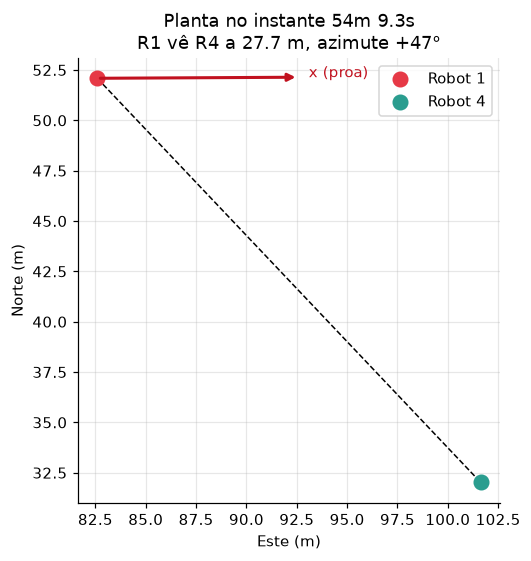

In [20]:
# Vista de cima no plano horizontal (N para cima, E para a direita), com a proa do Robot 1
fig, ax = plt.subplots(figsize=(5.2, 5.2))
for r in ("Robot 1", "Robot 4"):
    ax.scatter(est[r]["pos_ned"][1], est[r]["pos_ned"][0], s=90, color=COR[r], zorder=3, label=r)
psi = np.radians(est["Robot 1"]["euler_deg"][2])
ax.annotate("", xy=(p1[1] + 10 * np.sin(psi), p1[0] + 10 * np.cos(psi)), xytext=(p1[1], p1[0]),
            arrowprops=dict(arrowstyle="-|>", color="#c1121f", lw=2))
ax.text(p1[1] + 10.5 * np.sin(psi), p1[0] + 10.5 * np.cos(psi), "x (proa)", color="#c1121f")
ax.plot([p1[1], p4[1]], [p1[0], p4[0]], "k--", lw=1)
ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)"); ax.set_aspect("equal"); ax.legend()
ax.set_title(f"Planta no instante {tmiss(TE)}\nR1 vê R4 a {rho:.1f} m, azimute {az:+.0f}°")
plt.tight_layout(); plt.show()

**Interpretação.** O vetor em NED e o vetor no corpo têm a **mesma norma** (a rotação conserva comprimentos) e a réplica da função JavaScript dá o mesmo resultado que a versão matricial de Python, com diferença de arredondamento. O azimute mede para que lado do nariz do Robot 1 fica o Robot 4; o sinal e a figura são coerentes (positivo = direita da proa).

<a id="cap5"></a>
# CAPÍTULO 5 — MATRIZES DE ROTAÇÃO

## 5.1 O problema

O robô regista a sua orientação como um **quaternião unitário** $\mathbf{q}=(q_x,q_y,q_z,q_w)$, que é compacto e não tem singularidades, mas pouco intuitivo. O programa precisa de (a) uma **matriz de rotação** $\mathbf{R}$ para mudar de referencial e (b) os três ângulos **roll, pitch e yaw** para mostrar a atitude.

## 5.2 Ângulos e significado físico

Com os eixos do corpo $x$ (proa), $y$ (estibordo) e $z$ (quilha):

| Ângulo | Eixo | Significado | Sinal positivo |
|---|---|---|---|
| **Roll** $\phi$ (rolamento) | $x$ | inclinação para os lados | o lado direito desce |
| **Pitch** $\theta$ (arfagem) | $y$ | inclinação para cima ou para baixo | o nariz sobe |
| **Yaw** $\psi$ (guinada) | $z$ | para onde aponta o nariz no plano horizontal | para a direita (Norte para Este) |

## 5.3 Matrizes de rotação elementares

Rodar um **referencial** (ou um vetor) por um ângulo em torno de cada eixo:

$$\mathbf{R}_x(\phi)=\begin{bmatrix}1&0&0\\0&\cos\phi&-\sin\phi\\0&\sin\phi&\cos\phi\end{bmatrix},\quad
\mathbf{R}_y(\theta)=\begin{bmatrix}\cos\theta&0&\sin\theta\\0&1&0\\-\sin\theta&0&\cos\theta\end{bmatrix},\quad
\mathbf{R}_z(\psi)=\begin{bmatrix}\cos\psi&-\sin\psi&0\\\sin\psi&\cos\psi&0\\0&0&1\end{bmatrix}$$

## 5.4 Convenção usada no programa: ZYX (aeroespacial)

O código (`euler_zyx_to_rotation_matrix`, `rotations.py`) define

$$\boxed{\;\mathbf{R}=\mathbf{R}_z(\psi)\,\mathbf{R}_y(\theta)\,\mathbf{R}_x(\phi)\;}$$

e **a matriz leva um vetor do corpo para o NED**: $\mathbf{v}^{NED}=\mathbf{R}\,\mathbf{v}^{corpo}$. Multiplicando:

$$\mathbf{R}=\begin{bmatrix}
\cos\psi\cos\theta & \cos\psi\sin\theta\sin\phi-\sin\psi\cos\phi & \cos\psi\sin\theta\cos\phi+\sin\psi\sin\phi\\
\sin\psi\cos\theta & \sin\psi\sin\theta\sin\phi+\cos\psi\cos\phi & \sin\psi\sin\theta\cos\phi-\cos\psi\sin\phi\\
-\sin\theta & \cos\theta\sin\phi & \cos\theta\cos\phi
\end{bmatrix}$$

**Duas leituras equivalentes.** (i) *Extrínseca*: rodar o vetor primeiro em $x$ (roll), depois em $y$ (pitch), depois em $z$ (yaw), sempre em torno dos eixos **fixos** do NED. (ii) *Intrínseca*: rodar primeiro o yaw em torno de $z$, depois o pitch em torno do **novo** $y$, depois o roll em torno do **novo** $x$. É a ordem em que um piloto descreve a atitude: primeiro o rumo, depois a arfagem, depois o rolamento.

**As colunas de $\mathbf{R}$ são os eixos do corpo escritos em NED.** A primeira coluna, $(\cos\psi\cos\theta,\;\sin\psi\cos\theta,\;-\sin\theta)^T$, é a direção da proa. Esta é a leitura usada pelo dashboard para desenhar as setas $x,y,z$ do robô (`bodyAxesNED`).

## 5.5 Porque é que a ordem importa

O produto de matrizes **não é comutativo**: em geral $\mathbf{R}_z\mathbf{R}_y\neq\mathbf{R}_y\mathbf{R}_z$. Fisicamente, rodar 90° em torno de $z$ e depois 90° em torno de $y$ não leva ao mesmo sítio que fazer o inverso (demonstração na secção 5.9). A convenção tem de ser **a mesma** em quem calcula (o robô, que publica o quaternião, e o nosso programa). O programa usa ZYX, a convenção aeroespacial do ROS para roll, pitch e yaw.

## 5.6 Do quaternião à matriz

Para um quaternião unitário, a matriz de rotação é

$$\mathbf{R}(\mathbf{q})=\begin{bmatrix}
1-2(q_y^2+q_z^2) & 2(q_xq_y-q_zq_w) & 2(q_xq_z+q_yq_w)\\
2(q_xq_y+q_zq_w) & 1-2(q_x^2+q_z^2) & 2(q_yq_z-q_xq_w)\\
2(q_xq_z-q_yq_w) & 2(q_yq_z+q_xq_w) & 1-2(q_x^2+q_y^2)
\end{bmatrix}$$

e comparando com a matriz ZYX da secção 5.4 obtêm-se os ângulos:

$$\phi=\operatorname{atan2}\!\big(2(q_wq_x+q_yq_z),\;1-2(q_x^2+q_y^2)\big),\quad
\theta=\arcsin\!\big(2(q_wq_y-q_zq_x)\big),\quad
\psi=\operatorname{atan2}\!\big(2(q_wq_z+q_xq_y),\;1-2(q_y^2+q_z^2)\big).$$

Estas são exatamente as três linhas de `quaternion_to_euler_zyx`. O pitch usa $\arcsin$, por isso fica em $[-90^\circ,90^\circ]$; no pitch de $\pm90^\circ$ o roll e o yaw ficam indeterminados (*gimbal lock*) e o código **satura** o argumento do $\arcsin$ com `np.clip` para não produzir `NaN`.

## 5.7 Código real

In [21]:
from multi_robot_system.core.math import rotations as ROT
mostrar_codigo(ROT.quaternion_to_rotation_matrix, ate="return np.array([")
print("   ...  (a versão em lote, para arrays (N,4), repete as mesmas 9 fórmulas)")
print()
mostrar_codigo(ROT.quaternion_to_euler_zyx)
print()
mostrar_codigo(ROT.euler_zyx_to_rotation_matrix)

# multi_robot_system/core/math/rotations.py, linhas 23 a 31
  23  def quaternion_to_rotation_matrix(q: np.ndarray) -> np.ndarray:
  24      """Converte um quaternião [qx, qy, qz, qw] ou array (N, 4) numa matriz de rotação R in SO(3)."""
  25      q = np.asarray(q, dtype=float)
  26      if q.ndim == 1:
  27          qx, qy, qz, qw = q
  28          norm = np.sqrt(qx**2 + qy**2 + qz**2 + qw**2)
  29          if norm > 1e-15:
  30              qx, qy, qz, qw = qx / norm, qy / norm, qz / norm, qw / norm
  31          return np.array([
   ...  (a versão em lote, para arrays (N,4), repete as mesmas 9 fórmulas)

# multi_robot_system/core/math/rotations.py, linhas 59 a 84
  59  def quaternion_to_euler_zyx(
  60      qx: Union[float, np.ndarray],
  61      qy: Union[float, np.ndarray],
  62      qz: Union[float, np.ndarray],
  63      qw: Union[float, np.ndarray],
  64      degrees: bool = True
  65  ) -> Tuple[Union[float, np.ndarray], Union[float, np.ndarray], Union[float, np.ndarray]]:
  66

**Explicação linha a linha**

`quaternion_to_rotation_matrix`
- `q = np.asarray(q, dtype=float)`: aceita um quaternião (4 valores) ou $N$ quaterniões (matriz $N\times4$, versão em lote).
- `norm = ...; qx, qy, qz, qw = qx / norm, ...`: **renormaliza** o quaternião para evitar erros de arredondamento (a fórmula só vale para $\|\mathbf{q}\|=1$).
- `return np.array([[1.0 - 2.0*(qy**2 + qz**2), ...]])`: a matriz da secção 5.6, linha a linha.

`quaternion_to_euler_zyx`
- `sinr_cosp` e `cosr_cosp`: numerador e denominador do roll; `np.arctan2` dá o ângulo no quadrante correto.
- `sinp = np.clip(sinp, -1.0, 1.0)`: protege o $\arcsin$ de valores ligeiramente fora de $[-1,1]$.
- `siny_cosp` e `cosy_cosp`: idem para o yaw.
- `degrees=True`: converte para graus no fim.

`euler_zyx_to_rotation_matrix`
- `cr, sr = cos(roll), sin(roll)`, etc.: calcula uma só vez cada seno e cosseno.
- A matriz devolvida é o produto $\mathbf{R}_z\mathbf{R}_y\mathbf{R}_x$ já expandido (secção 5.4), por isso o comentário do código diz `R = Rz(yaw) * Ry(pitch) * Rx(roll)`.

## 5.8 Exemplo numérico com verificação

Usa-se o quaternião real da primeira amostra do Robot 1. Verifica-se: (1) ortonormalidade; (2) que $\mathbf{R}_z\mathbf{R}_y\mathbf{R}_x$ calculado **a partir dos ângulos** reproduz a matriz obtida **diretamente do quaternião**; (3) que a primeira coluna é a direção da proa; (4) coerência com a biblioteca SciPy.

In [22]:
q = df1[["pose.pose.orientation.x", "pose.pose.orientation.y", "pose.pose.orientation.z", "pose.pose.orientation.w"]].iloc[0].values.astype(float)
print("Quaternião (qx, qy, qz, qw) =", q, "   ||q|| =", np.linalg.norm(q))

R = ROT.quaternion_to_rotation_matrix(q)
roll, pitch, yaw = ROT.quaternion_to_euler_zyx(*q, degrees=False)
print(f"\nÂngulos: roll = {np.degrees(roll):.4f}°, pitch = {np.degrees(pitch):.4f}°, yaw = {np.degrees(yaw):.4f}°")
print("\nR (a partir do quaternião) =\n", R)

# (1) propriedades de SO(3)
print("\n(1) max|R^T R - I| =", np.abs(R.T @ R - np.eye(3)).max(), "   det(R) =", round(float(np.linalg.det(R)), 12))

# (2) produto das três rotações elementares
Rx = np.array([[1, 0, 0], [0, np.cos(roll), -np.sin(roll)], [0, np.sin(roll), np.cos(roll)]])
Ry = np.array([[np.cos(pitch), 0, np.sin(pitch)], [0, 1, 0], [-np.sin(pitch), 0, np.cos(pitch)]])
Rz = np.array([[np.cos(yaw), -np.sin(yaw), 0], [np.sin(yaw), np.cos(yaw), 0], [0, 0, 1]])
R_prod = Rz @ Ry @ Rx
print("\nRx =\n", Rx, "\nRy =\n", Ry, "\nRz =\n", Rz)
print("\n(2) max|Rz Ry Rx - R(quaternião)| =", np.abs(R_prod - R).max())
print("    max|euler_zyx_to_rotation_matrix - R(quaternião)| =", np.abs(ROT.euler_zyx_to_rotation_matrix(roll, pitch, yaw) - R).max())

# (3) primeira coluna = proa em NED
proa = R[:, 0]
print("\n(3) proa em NED (1.ª coluna) =", proa, "   atan2(R21, R11) =", np.degrees(np.arctan2(R[1, 0], R[0, 0])), "°  (= yaw)")

# (4) SciPy: 'xyz' minúsculo = rotações extrínsecas x, y, z = a nossa convenção ZYX
from scipy.spatial.transform import Rotation as SR
rot = SR.from_quat(q)
print("(4) SciPy as_euler('xyz') =", rot.as_euler("xyz", degrees=True), "   max|R_scipy - R| =", np.abs(rot.as_matrix() - R).max())

# Vetor de exemplo: um vetor que aponta 10 m à frente do robô, em NED
v_corpo = np.array([10.0, 0.0, 0.0])
print("\nVetor de 10 m na proa, em NED:", R @ v_corpo, "   e de volta ao corpo (R^T):", R.T @ (R @ v_corpo))

Quaternião (qx, qy, qz, qw) = [-0.00736 -0.00071  0.99016  0.13975]    ||q|| = 1.0

Ângulos: roll = -0.1986°, pitch = 0.8239°, yaw = 163.9315°

R (a partir do quaternião) =
 [[-0.96083 -0.27674 -0.01478]
 [ 0.27676 -0.96094  0.00065]
 [-0.01438 -0.00347  0.99989]]

(1) max|R^T R - I| = 8.881784197001252e-16    det(R) = 1.0

Rx =
 [[ 1.       0.       0.     ]
 [ 0.       0.99999  0.00347]
 [ 0.      -0.00347  0.99999]] 
Ry =
 [[ 0.9999   0.       0.01438]
 [ 0.       1.       0.     ]
 [-0.01438  0.       0.9999 ]] 
Rz =
 [[-0.96093 -0.27679  0.     ]
 [ 0.27679 -0.96093  0.     ]
 [ 0.       0.       1.     ]]

(2) max|Rz Ry Rx - R(quaternião)| = 4.440892098500626e-16
    max|euler_zyx_to_rotation_matrix - R(quaternião)| = 4.440892098500626e-16

(3) proa em NED (1.ª coluna) = [-0.96083  0.27676 -0.01438]    atan2(R21, R11) = 163.9315223119443 °  (= yaw)
(4) SciPy as_euler('xyz') = [ -0.19858   0.82394 163.93152]    max|R_scipy - R| = 2.220446049250313e-16

Vetor de 10 m na proa, em NE

**Interpretação.** (1) $\mathbf{R}^T\mathbf{R}=\mathbf{I}$ e $\det\mathbf{R}=+1$: a matriz é uma rotação própria. (2) Os três produtos coincidem até ao erro de arredondamento: o `euler_zyx_to_rotation_matrix` e o `quaternion_to_rotation_matrix` descrevem a **mesma** rotação, o que confirma que a convenção ZYX está aplicada de forma consistente nas duas direções. (3) A primeira coluna é a proa em NED e o seu rumo é o yaw. (4) O SciPy, com a convenção `xyz` extrínseca, dá os mesmos ângulos e a mesma matriz. Esta equivalência é relevante: `MissionDataset.get_state_at_time` obtém roll, pitch e yaw com `rot.as_euler("xyz")` do SciPy, e não com `quaternion_to_euler_zyx`; os dois caminhos coincidem.

## 5.9 A ordem das rotações em números

In [23]:
def Rx_(a): return np.array([[1, 0, 0], [0, np.cos(a), -np.sin(a)], [0, np.sin(a), np.cos(a)]])
def Ry_(a): return np.array([[np.cos(a), 0, np.sin(a)], [0, 1, 0], [-np.sin(a), 0, np.cos(a)]])
def Rz_(a): return np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])

a = np.radians(90.0)
v = np.array([1.0, 0.0, 0.0])
print("Rz(90°) depois Ry(90°) [Ry @ Rz]  ->", np.round(Ry_(a) @ Rz_(a) @ v, 6))
print("Ry(90°) depois Rz(90°) [Rz @ Ry]  ->", np.round(Rz_(a) @ Ry_(a) @ v, 6))
print("\nRz@Ry - Ry@Rz (comutador) =\n", np.round(Rz_(a) @ Ry_(a) - Ry_(a) @ Rz_(a), 6))

# Com os ângulos reais do Robot 1 a diferença é pequena, mas existe
Rzyx = Rz_(yaw) @ Ry_(pitch) @ Rx_(roll)
Rxyz = Rx_(roll) @ Ry_(pitch) @ Rz_(yaw)
print(f"\nCom os ângulos reais do Robot 1: max|Rz Ry Rx - Rx Ry Rz| = {np.abs(Rzyx - Rxyz).max():.4f}  (ordem trocada dá outra atitude)")

Rz(90°) depois Ry(90°) [Ry @ Rz]  -> [ 0.  1. -0.]
Ry(90°) depois Rz(90°) [Rz @ Ry]  -> [ 0.  0. -1.]

Rz@Ry - Ry@Rz (comutador) =
 [[ 0. -1. -1.]
 [-1.  0.  1.]
 [-1. -1.  0.]]

Com os ângulos reais do Robot 1: max|Rz Ry Rx - Rx Ry Rz| = 0.0292  (ordem trocada dá outra atitude)


**Interpretação.** Com 90° em cada eixo os dois resultados são vetores diferentes, o que mostra que **trocar a ordem muda a rotação**. Para os ângulos reais do Robot 1 (yaw grande, roll e pitch pequenos) a troca de ordem também altera a matriz. É por isso que o programa tem de usar a mesma convenção que gerou o quaternião e é por isso que a conversão de ida e volta é testada (secção 12).

## 5.10 Gama dos ângulos nos dados reais e risco de *gimbal lock*

In [24]:
linhas = []
for r in IDS:
    e = ds.trajectories[r].euler_deg
    linhas.append({"Robô": r, "roll mín": e[:, 0].min(), "roll máx": e[:, 0].max(), "pitch mín": e[:, 1].min(), "pitch máx": e[:, 1].max(),
                   "|pitch| máx (graus)": np.abs(e[:, 1]).max()})
display(pd.DataFrame(linhas).set_index("Robô").round(2))
print("O pitch fica sempre muito longe de ±90°: o gimbal lock não afeta estes dados.")

,roll mín,roll máx,pitch mín,pitch máx,|pitch| máx (graus)
Robô,,,,,
Robot 1,-30.82,11.16,-9.22,5.45,9.22
Robot 4,-18.96,8.47,-12.04,10.69,12.04
Robot 7,-12.95,7.98,-22.85,26.13,26.13


O pitch fica sempre muito longe de ±90°: o gimbal lock não afeta estes dados.


## 5.11 Onde estas matrizes aparecem no programa

| Uso | Onde |
|---|---|
| $\mathbf{R}$ de todas as amostras (`rot_matrices`, $N\times3\times3$) | `odom_loader.py`, `quaternion_to_rotation_matrix` em lote |
| roll, pitch, yaw de cada amostra | `odom_loader.py`, `quaternion_to_euler_zyx` |
| Atitude entre amostras | `trajectory.py`, **SLERP** (secção 7) |
| Vetores para o corpo ($\mathbf{R}^T$) | `proximity.py` e `toBody` em JavaScript |
| Eixos e casco do robô desenhados em NED | `bodyAxesNED`, `subMeshAt` em JavaScript |
| Quaternião a partir de roll, pitch, yaw (Cockpit) | `quaternionOf` em JavaScript: $q_w=c_rc_pc_y+s_rs_ps_y$ etc. |

<a id="cap6"></a>
# CAPÍTULO 6 — CÁLCULO DO RUMO E DA ORIENTAÇÃO

## 6.1 Conceitos

Há três ângulos que costumam confundir-se. O programa calcula e mostra os três:

| Conceito | Definição | Fórmula no código | Onde se vê |
|---|---|---|---|
| **Yaw** $\psi$ | ângulo do eixo $x$ do corpo no plano horizontal, de Norte para Este | $\operatorname{atan2}\big(2(q_wq_z+q_xq_y),\,1-2(q_y^2+q_z^2)\big)$ | cabeçalho do Cockpit |
| **Rumo** (*heading*) | o **yaw** em graus entre 0° e 360° (Norte = 0°, Este = 90°) | `wrap360(yaw)` | bússola, fita de rumo da 1.ª pessoa |
| **Rota** (*course over ground*) | direção real do movimento sobre o fundo | $\chi=\operatorname{atan2}(v_E,\,v_N)$ | seta âmbar da bússola |
| **Deriva** | diferença entre a rota e o rumo | $\beta=\text{wrap180}(\chi-\psi)$ | "deriva" no Cockpit |
| **Orientação** | atitude 3D completa: roll, pitch, yaw ou $\mathbf{R}$ | Capítulo 5 | Cockpit (horizonte), casco 3D |

No programa, **rumo e yaw são o mesmo número** (o rumo é o yaw reduzido a 0°–360°). A **rota** só é conhecida quando o robô anda (o código usa a velocidade horizontal estimada **superior a 0,3 m por segundo**); parado, a direção do movimento não é definida.

## 6.2 A função $\operatorname{atan2}$ e o quadrante

Dado um vetor horizontal $(\Delta N,\Delta E)$ o ângulo em relação ao Norte (sentido horário) é $\operatorname{atan2}(\Delta E,\Delta N)$. Esta função recebe os **dois** componentes e, por isso, devolve o ângulo no intervalo $(-180^\circ,180^\circ]$ **no quadrante certo**. A alternativa $\arctan(\Delta E\,/\,\Delta N)$ perde o sinal de cada componente e só dá valores entre $-90^\circ$ e $90^\circ$: não distingue, por exemplo, Nordeste de Sudoeste.

In [25]:
casos = [("Norte", 1, 0), ("Nordeste", 1, 1), ("Este", 0, 1), ("Sudeste", -1, 1), ("Sul", -1, 0),
         ("Sudoeste", -1, -1), ("Oeste", 0, -1), ("Noroeste", 1, -1)]
linhas = []
for nome, dN, dE in casos:
    ingenuo = np.degrees(np.arctan(dE / dN)) if dN != 0 else np.nan
    a2 = np.degrees(np.arctan2(dE, dN))
    linhas.append({"Direção": nome, "dN": dN, "dE": dE, "arctan(dE por dN) (errado)": ingenuo,
                   "atan2(dE, dN)": a2, "rumo 0-360° (correto)": a2 % 360})
display(pd.DataFrame(linhas).set_index("Direção").round(1))

,dN,dE,arctan(dE por dN) (errado),"atan2(dE, dN)",rumo 0-360° (correto)
Direção,,,,,
Norte,1,0,0.0,0.0,0.0
Nordeste,1,1,45.0,45.0,45.0
Este,0,1,NaN,90.0,90.0
Sudeste,-1,1,-45.0,135.0,135.0
Sul,-1,0,-0.0,180.0,180.0
Sudoeste,-1,-1,45.0,-135.0,225.0
Oeste,0,-1,NaN,-90.0,270.0
Noroeste,1,-1,-45.0,-45.0,315.0


**Interpretação.** O $\arctan$ simples dá **45°** tanto para Nordeste $(1,1)$ como para Sudoeste $(-1,-1)$ e não existe para Norte e Sul ($\Delta N$ ou $\Delta E$ nulos). O $\operatorname{atan2}$ distingue-os (45° e $-135^\circ$) e a redução módulo 360° dá o rumo de bússola (45° e 225°).

## 6.3 Tratamento dos ângulos no código

O dashboard usa duas funções de normalização, escritas em JavaScript:

- `wrap360(a)` leva qualquer ângulo ao intervalo $[0,360)$, usado para **rumos**;
- `wrap180(a)` leva ao intervalo $[-180,180)$, usado para **diferenças** de ângulo (deriva, azimute relativo): a diferença mais curta entre dois rumos.

In [26]:
mostrar_js("wrap360")
mostrar_js("wrap180")
print()
mostrar_js("compassPanel")

# multi_robot_system/visualization/web_server.py, linhas 1360 a 1362
1360          // Método: resto da divisão por 360 corrigido para positivo.
1361          // Obtemos: um ângulo entre 0 e 360 (rumo).
1362          const wrap360 = (a) => ((a % 360) + 360) % 360;
# multi_robot_system/visualization/web_server.py, linhas 1363 a 1365
1363          // Método: deslocar 180, resto da divisão por 360, voltar a deslocar.
1364          // Obtemos: um ângulo entre -180 e 180 (diferenças de rumo).
1365          const wrap180 = (a) => (((a + 180) % 360) + 360) % 360 - 180;

# multi_robot_system/visualization/web_server.py, linhas 1440 a 1467
1440          // Método: o rumo (heading) vem do quaternião; a rota (course) é a direção da velocidade estimada, com
1441          // atan2(vE, vN), e só se mostra acima de 0.3 m por segundo; a deriva é rota menos rumo.
1442          // Obtemos: a bússola com o nariz (rumo), a direção em que realmente anda (rota) e o desvio entre os dois.
1443          functio

**Explicação linha a linha de `compassPanel`**

- `spd = Math.hypot(s.vN, s.vE)`: velocidade horizontal $\sqrt{v_N^2+v_E^2}$.
- `cog = spd > 0.3 ? wrap360(Math.atan2(s.vE, s.vN)/DEG) : null`: a rota é $\operatorname{atan2}(v_E,v_N)$ em graus, reduzida a 0°–360°, **só** se $spd>0{,}3$ m por segundo.
- `polar(a, rr)`: converte (ângulo de bússola, raio) em coordenadas do ecrã: $x=c_x+r\sin a$, $y=c_y-r\cos a$ (o Norte aponta para cima, o ângulo cresce no sentido horário).
- O polígono ciano (a proa) usa `s.yaw`, a seta âmbar tracejada usa `cog`.
- `beta = wrap180(cog - wrap360(s.yaw))`: a deriva.

## 6.4 Ângulos contínuos: `np.unwrap`

O yaw que sai do quaternião salta de $+180^\circ$ para $-180^\circ$ quando o robô passa pelo Sul. Interpolar linearmente entre $179^\circ$ e $-179^\circ$ daria $0^\circ$ (apontando para Norte!), o que é um erro grave. Antes de enviar a série para o navegador, o Python faz `np.unwrap`, que torna o ângulo **contínuo** (por exemplo 179°, 181°, 183°...).

In [27]:
def mostrar_linhas(ficheiro, padrao, n=4):
    """Imprime n linhas a partir da primeira que contém 'padrao' (código real do ficheiro)."""
    L = Path(ficheiro).read_text(encoding="utf-8").splitlines()
    i = next(k for k, l in enumerate(L) if padrao in l)
    print(f"# {ficheiro}, linhas {i + 1} a {i + n}")
    for k in range(i, i + n):
        print(f"{k + 1:4d}  {L[k].rstrip()}")

mostrar_linhas(JS_FICHEIRO, "def _unwrap_deg", 4)

# Exemplo real: primeira vez que o yaw do Robot 1 passa de +180 para -180 (ou o contrário)
yaw1 = ds.trajectories["Robot 1"].euler_deg[:, 2]
salto = np.where(np.abs(np.diff(yaw1)) > 180)[0]
print(f"\nRobot 1: o yaw bruto tem {len(salto)} saltos de ±360° em {len(yaw1)} amostras")
k = salto[0]
print("yaw bruto  em k-1, k, k+1, k+2 :", np.round(yaw1[k - 1:k + 3], 2))
yaw_u = np.degrees(np.unwrap(np.radians(yaw1)))
print("yaw contínuo (np.unwrap)       :", np.round(yaw_u[k - 1:k + 3], 2))
meio = 0.5 * (yaw1[k] + yaw1[k + 1])
meio_u = 0.5 * (yaw_u[k] + yaw_u[k + 1])
print(f"Ponto médio ingénuo entre as duas amostras: {meio:.2f}° (errado, aponta para o lado oposto);  com unwrap: {meio_u:.2f}° (≡ {meio_u % 360:.2f}° no intervalo 0-360)")

# multi_robot_system/visualization/web_server.py, linhas 95 a 98
  95          def _unwrap_deg(a):
  96              # Método: np.unwrap tira os saltos de 360 graus. Obtemos: ângulos contínuos (359 para 1 deixa de ser um salto),
  97              # necessários para interpolar e alisar o rumo no navegador.
  98              return np.degrees(np.unwrap(np.radians(a)))

Robot 1: o yaw bruto tem 12 saltos de ±360° em 9537 amostras
yaw bruto  em k-1, k, k+1, k+2 : [ 178.19  179.62 -179.3  -178.55]
yaw contínuo (np.unwrap)       : [178.19 179.62 180.7  181.45]
Ponto médio ingénuo entre as duas amostras: 0.16° (errado, aponta para o lado oposto);  com unwrap: 180.16° (≡ 180.16° no intervalo 0-360)


## 6.5 Do rumo ao vizinho: o rumo para outro robô

O **rumo para** o robô vizinho (*bearing*) é o ângulo da linha que os liga, em relação ao Norte: $\operatorname{atan2}(\Delta E,\Delta N)$, onde $(\Delta N,\Delta E)$ é a diferença de posições. O **azimute relativo** (em relação à proa) é a diferença entre esse rumo e o rumo do próprio robô. No código, `nearestNeighbour` calcula os dois: o rumo (`brg`) a partir de NED e o azimute (`az`) a partir do vetor no corpo.

In [28]:
mostrar_js("nearestNeighbour")

# multi_robot_system/visualization/web_server.py, linhas 1633 a 1658
1633          // Método: para cada outro robô ativo, distância 3D, azimute e elevação (rodando o vetor para o corpo com
1634          // toBody), rumo absoluto e aproximação = menos (d·rv) a dividir pela distância; guarda-se o mais próximo.
1635          // Obtemos: o vizinho mais próximo com tudo o que o painel de bordo mostra.
1636          function nearestNeighbour(id, f) {
1637              const me = timeline.robots[id];
1638              if (!me || !isActive(me, f)) return null;
1639              const s = fullStateAt(me, f);
1640              let best = null;
1641              robotKeys.forEach(function (o) {
1642                  if (o === id) return;
1643                  const ro = timeline.robots[o];
1644                  if (!isActive(ro, f)) return;
1645                  const t = fullStateAt(ro, f);
1646                  const dN = t.N - s.N, dE = t.E - s.E, dD = t.D - s.D;
1647                  const rn

## 6.6 Exemplo numérico: rumo, rota, deriva e rumo ao vizinho

No instante de maior aproximação, para o Robot 1 e o Robot 4. A rota usa a **velocidade estimada** (Kalman e RTS) do estado interpolado; a limiar de 0,3 m por segundo é a do código.

In [29]:
wrap360 = lambda a: (a % 360 + 360) % 360
wrap180 = lambda a: ((a + 180) % 360 + 360) % 360 - 180

linhas = []
for r in ("Robot 1", "Robot 4"):
    s = est[r]
    vN, vE, vD = s["vel_ned"]
    vh = np.hypot(vN, vE)
    yaw_r = s["euler_deg"][2]
    cog = wrap360(np.degrees(np.arctan2(vE, vN))) if vh > 0.3 else np.nan
    linhas.append({"Robô": r, "yaw (°)": yaw_r, "rumo 0-360 (°)": wrap360(yaw_r), "vel. horizontal (m por s)": vh,
                   "rota (°)": cog, "deriva (°)": wrap180(cog - wrap360(yaw_r)) if vh > 0.3 else np.nan})
display(pd.DataFrame(linhas).set_index("Robô").round(2))

# rumo de R1 para R4 e azimute relativo, de duas formas
dN, dE, dD = (est["Robot 4"]["pos_ned"] - est["Robot 1"]["pos_ned"])
brg = wrap360(np.degrees(np.arctan2(dE, dN)))
yaw_1 = wrap360(est["Robot 1"]["euler_deg"][2])
print(f"\nRumo de R1 para R4 (atan2(dE, dN)) = {brg:.2f}°;   rumo de R1 = {yaw_1:.2f}°")
print(f"Azimute relativo pela diferença de rumos: wrap180({brg:.2f} - {yaw_1:.2f}) = {wrap180(brg - yaw_1):+.2f}°")
print(f"Azimute relativo pelo vetor no corpo (secção 4.8, com roll e pitch)     = {az:+.2f}°")

,yaw (°),rumo 0-360 (°),vel. horizontal (m por s),rota (°),deriva (°)
Robô,,,,,
Robot 1,89.70,89.70,0.46,90.38,0.69
Robot 4,109.34,109.34,0.42,99.39,-9.95



Rumo de R1 para R4 (atan2(dE, dN)) = 136.51°;   rumo de R1 = 89.70°
Azimute relativo pela diferença de rumos: wrap180(136.51 - 89.70) = +46.81°
Azimute relativo pelo vetor no corpo (secção 4.8, com roll e pitch)     = +46.77°


**Interpretação.** O rumo é o yaw reduzido a 0°–360°. A **deriva** quantifica o quanto o movimento sobre o fundo se afasta da proa, por exemplo por corrente ou por o robô andar de lado. O azimute relativo obtido pela **diferença de rumos** (plano horizontal) é quase igual ao obtido pelo **vetor no corpo**: a pequena diferença vem de este último incluir o roll e o pitch (a diferença de rumos ignora-os).

## 6.7 Como é mostrado no dashboard

No separador **Cockpit**, a bússola desenha a proa (ciano), a rota (âmbar) e escreve "rumo", "rota" e "deriva". Na **Vista 1.ª Pessoa**, a fita de rumo mostra `RUMO` em graus ao centro, as marcas N, NE, E, SE, S, SO, O e NO, e um losango na direção do vizinho mais próximo (`brg`). Reproduz-se a bússola do Cockpit para o instante em estudo:

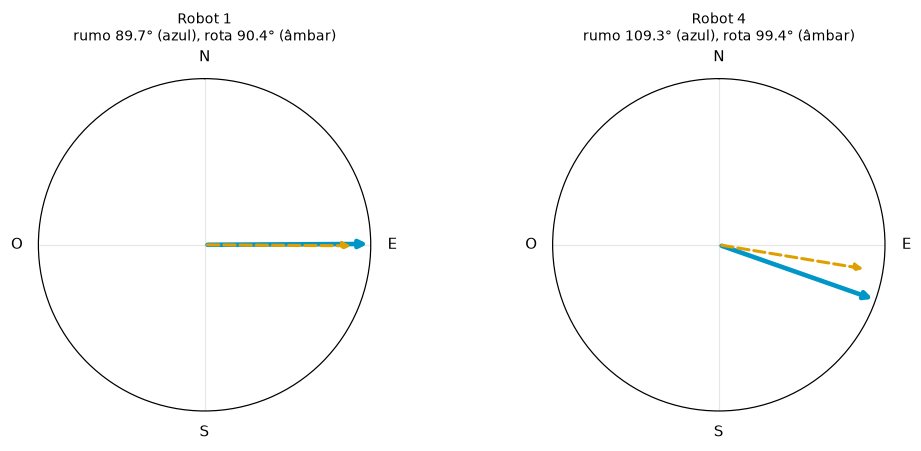

In [30]:
fig = plt.figure(figsize=(9.5, 4.2))
for k, r in enumerate(("Robot 1", "Robot 4")):
    ax = fig.add_subplot(1, 2, k + 1, projection="polar")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    s = est[r]
    yaw_r = np.radians(wrap360(s["euler_deg"][2]))
    vh = np.hypot(*s["vel_ned"][:2])
    ax.annotate("", xy=(yaw_r, 1.0), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="#0096c7", lw=3))
    if vh > 0.3:
        cog = np.arctan2(s["vel_ned"][1], s["vel_ned"][0])
        ax.annotate("", xy=(cog, 0.9), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="#e09f00", lw=2, ls="--"))
    ax.set_yticks([]); ax.set_xticks(np.radians([0, 90, 180, 270])); ax.set_xticklabels(["N", "E", "S", "O"])
    ax.set_title(f"{r}\nrumo {np.degrees(yaw_r):.1f}° (azul)" + (f", rota {np.degrees(cog) % 360:.1f}° (âmbar)" if vh > 0.3 else ", parado"), fontsize=9)
plt.tight_layout(); plt.show()

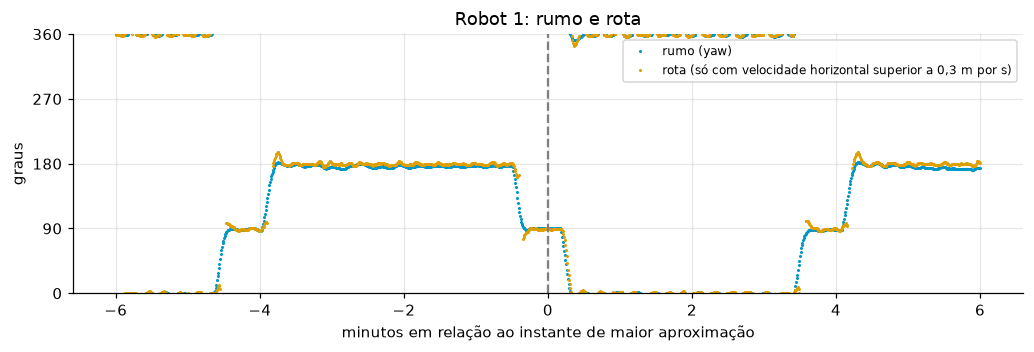

In [31]:
# Evolução do rumo e da rota do Robot 1 em redor do instante de maior aproximação (±6 min)
tr = ds.trajectories["Robot 1"]
m = (tr.timestamps > TE - 360) & (tr.timestamps < TE + 360)
t_min = (tr.timestamps[m] - TE) / 60
yaw_s = wrap360(tr.euler_deg[m, 2])
cog_s = wrap360(np.degrees(np.arctan2(tr.vel_ned[1, m], tr.vel_ned[0, m])))
vh_s = np.hypot(tr.vel_ned[0, m], tr.vel_ned[1, m])
cog_s = np.where(vh_s > 0.3, cog_s, np.nan)
fig, ax = plt.subplots(figsize=(9.5, 3.3))
ax.plot(t_min, yaw_s, ".", ms=2, color="#0096c7", label="rumo (yaw)")
ax.plot(t_min, cog_s, ".", ms=2, color="#e09f00", label="rota (só com velocidade horizontal superior a 0,3 m por s)")
ax.axvline(0, color="gray", ls="--"); ax.set_ylim(0, 360); ax.set_yticks(range(0, 361, 90))
ax.set_xlabel("minutos em relação ao instante de maior aproximação"); ax.set_ylabel("graus"); ax.set_title("Robot 1: rumo e rota")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

**Leitura.** Os pontos que "saltam" entre 0° e 360° são o efeito da escala circular (não são erros). As zonas em que a rota desaparece são aquelas em que o robô está quase parado (velocidade abaixo de 0,3 m por segundo). Onde ambos existem, a rota segue o rumo com pequenas diferenças: a **deriva**.

<a id="cap7"></a>
# CAPÍTULO 7 — TRAJETÓRIAS E MOVIMENTO

## 7.1 Medido, calculado e estimado

Para não misturar conceitos, o programa distingue três tipos de valores. Esta distinção é essencial para saber **quanto confiar** em cada número que o dashboard mostra.

| Tipo | Significado | Exemplos neste projeto |
|---|---|---|
| **Medido** | vem diretamente do CSV, sem tratamento matemático | tempo, latitude, longitude, altura, quaternião, covariância, velocidade `twist` no corpo |
| **Calculado** | resulta de uma fórmula **determinística** a partir de valores medidos | posição NED, matriz $\mathbf{R}$, roll, pitch, yaw, distâncias, rumo ao vizinho, velocidade por diferenças finitas, saltos |
| **Estimado** | resulta de um **estimador estatístico** (usa um modelo e as incertezas) | posição suavizada e velocidade NED (Kalman e RTS), covariância posterior, **velocidade longitudinal** (projeção da velocidade estimada), taxa de viragem |
| **Interpolado** | valor entre duas amostras | `np.interp` e SLERP; grelha de 2 s no navegador |
| **Previsto** | extrapolação para o futuro | previsão de 60 s e CPA, em linha reta |

## 7.2 Como o programa guarda uma trajetória

Cada robô é um objeto `RobotTrajectory` (`trajectory.py`) com uma amostra por instante de tempo:

In [32]:
import dataclasses
from multi_robot_system.core.data.trajectory import RobotTrajectory
tr1 = ds.trajectories["Robot 1"]
tipo = {"timestamps": "medido", "lat": "medido", "lon": "medido", "alt": "medido", "quaternions": "medido (normalizado)",
        "pos_ned_raw": "calculado (geodesia)", "rot_matrices": "calculado", "euler_deg": "calculado",
        "pos_ned": "estimado (Kalman+RTS)", "vel_ned": "estimado (Kalman+RTS)", "cov_diag": "estimado (Kalman+RTS)",
        "speed_longitudinal": "estimado (projeção)", "turn_rate_yaw": "calculado (derivada do yaw)",
        "vel_body_meas": "medido (twist)", "sigma_h_decl": "medido (covariância)", "jump_events": "calculado",
        "robot_id": "-", "label": "-", "color": "-"}
linhas = []
for f in dataclasses.fields(RobotTrajectory):
    v = getattr(tr1, f.name)
    forma = tuple(np.shape(v)) if isinstance(v, np.ndarray) else (f"lista de {len(v)}" if isinstance(v, list) else "-")
    linhas.append({"Campo": f.name, "Forma": forma, "Tipo": tipo.get(f.name, "-")})
display(pd.DataFrame(linhas).set_index("Campo"))

,Forma,Tipo
Campo,,
robot_id,-,-
label,-,-
color,-,-
timestamps,"(9537,)",medido
lat,"(9537,)",medido
lon,"(9537,)",medido
alt,"(9537,)",medido
pos_ned,"(3, 9537)",estimado (Kalman+RTS)
quaternions,"(9537, 4)",medido (normalizado)


## 7.3 O tempo

O CSV traz o instante em segundos POSIX (a partir de 1970). O programa mantém esse valor absoluto e define o **tempo da missão** como o tempo desde o primeiro registo de qualquer robô, `t0_mission`. O dashboard mostra esse tempo no formato `minutos m segundos s`. Os robôs têm janelas diferentes (Capítulo 1), por isso o estado de um robô só existe se $t$ estiver dentro dessa janela (`get_state_at_time` ignora os robôs inativos).

## 7.4 Velocidades

Há quatro velocidades diferentes no projeto, que não devem ser confundidas:

1. **Medida** pelo robô (`twist.twist.linear`), no referencial do corpo: $u$ (proa), $v$ (estibordo), $w$ (baixo).
2. **Por diferenças finitas** das posições brutas: $\mathbf{v}_k\approx\dfrac{\mathbf{p}_{k+1}-\mathbf{p}_k}{\Delta t}$ (muito ruidosa).
3. **Estimada pelo Kalman e RTS** (`vel_ned`): componentes $(v_N,v_E,v_D)$ em NED (Capítulo 8).
4. **Longitudinal** (`speed_longitudinal`): a velocidade estimada **projetada na proa**,

$$v_{long}=v_N\cos\psi+v_E\sin\psi,$$

onde $\psi$ é o yaw. É o produto escalar da velocidade horizontal com o vetor unitário da proa $(\cos\psi,\sin\psi)$. É o número mostrado como "velocidade" nas vistas.

A **taxa de viragem** (*yaw rate*) é a derivada do yaw **contínuo** (sem saltos de 360°): $\dot\psi_k\approx\dfrac{\psi_{k}-\psi_{k-1}}{t_k-t_{k-1}}$, em graus por segundo.

In [33]:
from multi_robot_system.core.math import kalman_rts as K
mostrar_codigo(K.compute_longitudinal_speed)
print()
mostrar_codigo(K.compute_turn_rate)

# multi_robot_system/core/math/kalman_rts.py, linhas 147 a 160
 147  def compute_longitudinal_speed(vel_ned: np.ndarray, yaw_deg: np.ndarray) -> np.ndarray:
 148      """Calcula a velocidade linear orientada na direção do movimento longitudinal (m/s).
 149  
 150      Args:
 151          vel_ned: Array (3, N) com [vN, vE, vD].
 152          yaw_deg: Array (N,) com o ângulo de proa em graus (Norte=0°, Este=90°).
 153      """
 154      yaw_rad = np.radians(yaw_deg)
 155      head_x = np.cos(yaw_rad)  # vetor unitário no plano horizontal N
 156      head_y = np.sin(yaw_rad)  # vetor unitário no plano horizontal E
 157  
 158      # Produto escalar com o vetor de velocidade horizontal
 159      v_long = vel_ned[0] * head_x + vel_ned[1] * head_y
 160      return v_long

# multi_robot_system/core/math/kalman_rts.py, linhas 163 a 172
 163  def compute_turn_rate(yaw_deg: np.ndarray, timestamps: np.ndarray) -> np.ndarray:
 164      """Calcula a velocidade angular de viragem (yaw rate) em graus

**Explicação linha a linha**

- `yaw_rad = np.radians(yaw_deg)`; `head_x = np.cos(yaw_rad)`; `head_y = np.sin(yaw_rad)`: componentes Norte e Este do vetor unitário da proa.
- `v_long = vel_ned[0]*head_x + vel_ned[1]*head_y`: produto escalar $v_N\cos\psi+v_E\sin\psi$. A componente vertical $v_D$ **não** entra: é velocidade horizontal ao longo da proa.
- `np.unwrap(np.radians(yaw_deg))`: yaw contínuo (secção 6.4).
- `dt = np.where(dt <= 1e-6, 1e-3, dt)`: protege a divisão contra passos de tempo nulos.
- `rates = np.diff(yaw_unwrapped) / dt` e `np.concatenate([[rates[0]], rates])`: a derivada tem $N-1$ valores; repete-se o primeiro para ter $N$.

### Comparação entre velocidade medida e estimada (Robot 1)

A velocidade **medida** pelo robô ($u$ de `twist`) e a **estimada** a partir das posições (projeção na proa) são independentes: concordar entre si é uma validação do filtro e da projeção.

In [34]:
linhas = []
for r in IDS:
    t = ds.trajectories[r]
    u = t.vel_body_meas[0]
    v_est = t.speed_longitudinal
    # velocidade por diferenças finitas das posições brutas, projetada na proa (para mostrar o ruído)
    dt = np.diff(t.timestamps)
    dN = np.diff(t.pos_ned_raw[0]) / dt; dE = np.diff(t.pos_ned_raw[1]) / dt
    psi = np.radians(0.5 * (t.euler_deg[:-1, 2] + t.euler_deg[1:, 2]))
    v_fd = dN * np.cos(psi) + dE * np.sin(psi)
    linhas.append({"Robô": r,
                   "média u medida (m por s)": u.mean(), "média estimada (m por s)": v_est.mean(),
                   "RMS(estimada - medida)": np.sqrt(np.mean((v_est - u) ** 2)),
                   "correlação": np.corrcoef(v_est, u)[0, 1],
                   "desvio-padrão das diferenças finitas (m por s)": np.std(v_fd - 0.5 * (u[:-1] + u[1:]))})
display(pd.DataFrame(linhas).set_index("Robô").round(3))

,média u medida (m por s),média estimada (m por s),RMS(estimada - medida),correlação,desvio-padrão das diferenças finitas (m por s)
Robô,,,,,
Robot 1,0.379,0.383,0.081,0.926,0.108
Robot 4,0.418,0.417,0.033,0.994,0.039
Robot 7,-0.027,-0.025,0.348,0.302,0.731


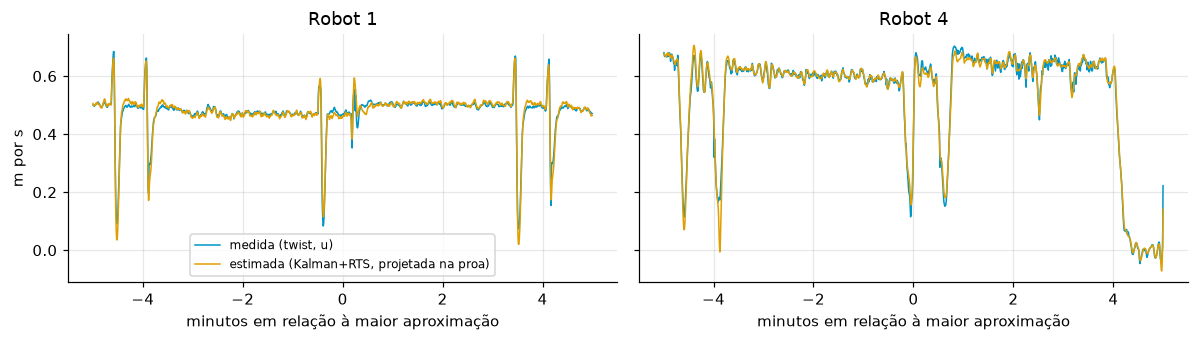

In [35]:
# Janela de 10 minutos em torno do instante de maior aproximação (como no painel "Velocidade: medida e estimada")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, r in zip(axs, ("Robot 1", "Robot 4")):
    t = ds.trajectories[r]
    m = (t.timestamps > TE - 300) & (t.timestamps < TE + 300)
    x = (t.timestamps[m] - TE) / 60
    ax.plot(x, t.vel_body_meas[0][m], color="#0096c7", lw=1, label="medida (twist, u)")
    ax.plot(x, t.speed_longitudinal[m], color="#e09f00", lw=1, label="estimada (Kalman+RTS, projetada na proa)")
    ax.set_title(r); ax.set_xlabel("minutos em relação à maior aproximação")
axs[0].set_ylabel("m por s"); axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretação.** Para o Robot 1 e o Robot 4, a velocidade estimada pelas posições (que só usa latitude, longitude, altura e o yaw) acompanha a velocidade que o próprio robô mede (`twist`): a correlação é de 0,93 e 0,99 e a médias (0,38 e 0,42 m por segundo) são quase iguais. Isto valida duas coisas ao mesmo tempo: a geodesia (as posições têm a escala correta em metros) e a projeção na proa. Para o **Robot 7** o acordo é fraco (correlação de 0,30): este robô quase não se desloca (velocidade média próxima de zero) e o sinal útil fica abaixo do ruído das posições. A última coluna mostra que as diferenças finitas diretas se afastam mais da velocidade medida do que a estimada pelo filtro (0,108 contra 0,081; 0,039 contra 0,033; 0,731 contra 0,348), ligeiramente para os robôs 1 e 4 e muito para o Robot 7; a medida direta do efeito do filtro está na secção 8.5.

## 7.5 Distâncias percorridas e deslocamento

- **Caminho horizontal** (`total_distance_m`): soma dos passos horizontais $\sum_k\sqrt{\Delta N_k^2+\Delta E_k^2}$ sobre a trajetória **suavizada**.
- **Caminho 3D**: o mesmo com $\Delta D$ (não existe no código; calcula-se aqui só para comparação).
- **Deslocamento**: distância em linha reta entre o primeiro e o último ponto, $\|\mathbf{p}_{N}-\mathbf{p}_{0}\|$.

In [36]:
mostrar_codigo(RobotTrajectory.total_distance_m.fget)
linhas = []
for r in IDS:
    t = ds.trajectories[r]
    p = t.pos_ned
    d3 = np.sum(np.linalg.norm(np.diff(p, axis=1), axis=0))
    desl = np.linalg.norm(p[:, -1] - p[:, 0])
    linhas.append({"Robô": r, "Caminho horizontal (m)": t.total_distance_m, "Caminho 3D (m)": d3,
                   "Deslocamento início-fim (m)": desl, "Profundidade máx. (m)": t.max_depth_m,
                   "Duração (s)": t.duration_s, "Velocidade média do caminho (m por s)": t.total_distance_m / t.duration_s})
print()
display(pd.DataFrame(linhas).set_index("Robô").round(2))

# multi_robot_system/core/data/trajectory.py, linhas 49 a 53
  49      @property
  50      def total_distance_m(self) -> float:
  51          """Método: somar os passos horizontais entre amostras seguidas (raiz de dN2 + dE2). Obtemos: caminho percorrido [m]."""
  52          diffs = np.diff(self.pos_ned[:2, :], axis=1)
  53          return float(np.sum(np.sqrt(diffs[0]**2 + diffs[1]**2)))



,Caminho horizontal (m),Caminho 3D (m),Deslocamento início-fim (m),Profundidade máx. (m),Duração (s),Velocidade média do caminho (m por s)
Robô,,,,,,
Robot 1,2022.15,2089.25,133.69,30.27,5089.79,0.40
Robot 4,1324.37,1392.81,63.85,28.26,2995.32,0.44
Robot 7,962.26,1161.72,23.59,31.40,8012.67,0.12


## 7.6 Movimento em 3D

As trajetórias suavizadas dos três robôs em NED, com a profundidade para baixo (eixo invertido para a leitura ser natural: mais fundo em baixo).

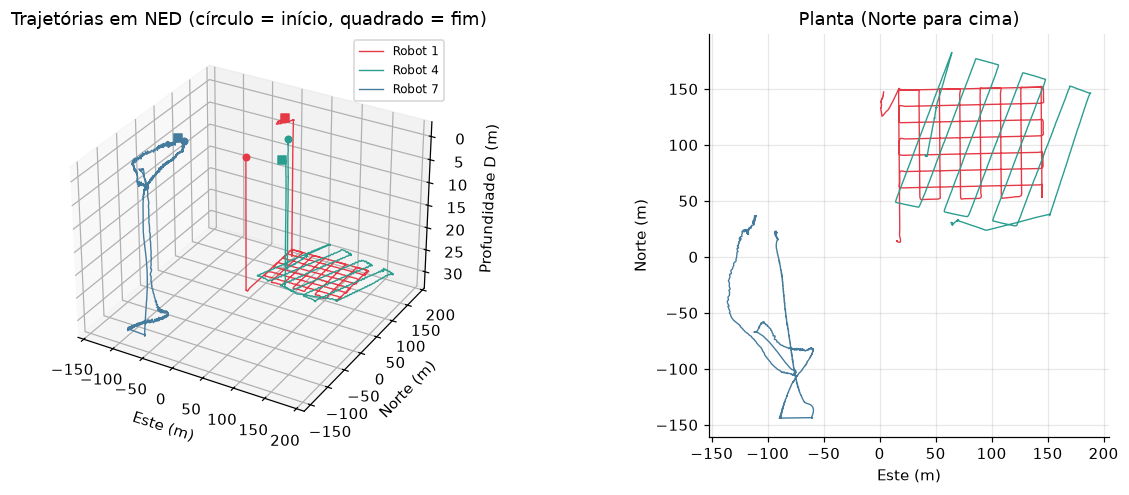

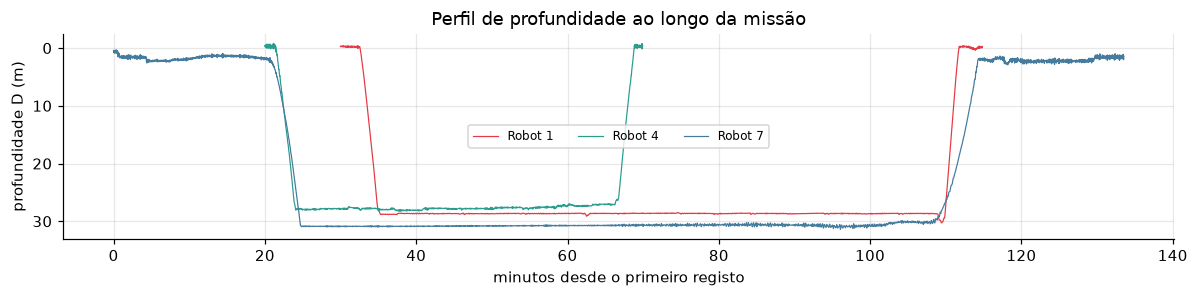

In [37]:
fig = plt.figure(figsize=(12, 4.6))
ax = fig.add_subplot(1, 2, 1, projection="3d")
for r in IDS:
    p = ds.trajectories[r].pos_ned
    ax.plot(p[1], p[0], p[2], color=COR[r], lw=0.9, label=r)
    ax.scatter(p[1, 0], p[0, 0], p[2, 0], color=COR[r], s=18, marker="o")
    ax.scatter(p[1, -1], p[0, -1], p[2, -1], color=COR[r], s=28, marker="s")
ax.invert_zaxis(); ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)"); ax.set_zlabel("Profundidade D (m)")
ax.set_title("Trajetórias em NED (círculo = início, quadrado = fim)"); ax.legend(fontsize=8)

ax2 = fig.add_subplot(1, 2, 2)
for r in IDS:
    p = ds.trajectories[r].pos_ned
    ax2.plot(p[1], p[0], color=COR[r], lw=0.9, label=r)
ax2.set_aspect("equal"); ax2.set_xlabel("Este (m)"); ax2.set_ylabel("Norte (m)"); ax2.set_title("Planta (Norte para cima)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 2.8))
for r in IDS:
    t = ds.trajectories[r]
    ax.plot((t.timestamps - T0) / 60, t.pos_ned[2], color=COR[r], lw=0.8, label=r)
ax.invert_yaxis(); ax.set_xlabel("minutos desde o primeiro registo"); ax.set_ylabel("profundidade D (m)"); ax.legend(ncol=3, fontsize=8)
ax.set_title("Perfil de profundidade ao longo da missão"); plt.tight_layout(); plt.show()

## 7.7 Como o movimento é atualizado ao longo do tempo

O programa **não integra** velocidades para obter posições: a posição em cada instante vem dos dados (suavizados) e é **interpolada** entre amostras. Em Python, `MissionDataset.get_state_at_time(t)` devolve, para cada robô ativo, a posição NED, a velocidade, a atitude (por SLERP), a velocidade longitudinal e a taxa de viragem. No navegador, a reprodução é um ciclo (`requestAnimationFrame`) que avança o relógio da missão: $t\leftarrow t+\Delta t_{real}\times\text{velocidade}$.

In [38]:
mostrar_js("runPlaybackLoop")

# multi_robot_system/visualization/web_server.py, linhas 2151 a 2184
2151          // Método: requestAnimationFrame; o tempo avança dtSec vezes a velocidade escolhida (dtSec limitado a 0.25 s
2152          // para não saltar depois de uma pausa) e os gráficos só se refazem cerca de 30 vezes por segundo.
2153          // Obtemos: reprodução fluida mesmo com 50 vezes a velocidade.
2154          function runPlaybackLoop(timestamp) {
2155              if (!isPlaying) { lastFrameTimestamp = null; return; }
2156              if (!lastFrameTimestamp) lastFrameTimestamp = timestamp;
2157              const dtSec = Math.min(0.25, (timestamp - lastFrameTimestamp) / 1000.0);
2158              lastFrameTimestamp = timestamp;
2159  
2160              let effectiveSpeed = speed;
2161              if (speed >= 500.0) effectiveSpeed = (t_max - t0_base) / 2.0;   // missão completa em ~2 segundos
2162  
2163              const prevTime = currentTime;
2164              currentTime += dtSec * effectiveSpe

**Explicação.** `dtSec` é o tempo real decorrido desde o último quadro (limitado a 0,25 s para não dar um salto depois de uma pausa). `currentTime += dtSec * effectiveSpeed` avança o relógio da missão à velocidade escolhida (0,25x a 50x; no modo "Ultra" `effectiveSpeed = (t_max - t0_base)/2`, para percorrer a missão em cerca de 2 s). Quando passa o fim, volta ao início. Se existir colisão e o tempo atravessar o instante dela, a reprodução pára aí (Capítulo 10). Os gráficos só se refazem a cada 33 ms (cerca de 30 por segundo).

### O estado num instante

O dicionário abaixo é o que o programa sabe do Robot 1 no instante de maior aproximação.

In [39]:
st = est["Robot 1"]
for k, v in st.items():
    if isinstance(v, np.ndarray) and v.ndim == 2:
        print(f"{k:20s} matriz {v.shape}")
    elif isinstance(v, np.ndarray):
        print(f"{k:20s} {np.round(v, 4)}")
    else:
        print(f"{k:20s} {v if not isinstance(v, float) else round(v, 4)}")

robot_id             Robot 1
label                AUV Alpha (Robot 1)
color                #E63946
pos_ned              [52.0891 82.5913 28.5979]
vel_ned              [-0.0031  0.4613  0.0102]
quaternion           [-0.037  -0.0356  0.7043  0.708 ]
euler_deg            [-5.8885  0.0998 89.6978]
R_wb                 matriz (3, 3)
speed_longitudinal   0.4613
turn_rate_yaw        0.2569
depth_m              28.5979


### Previsão de 60 s

A linha de previsão (tecla `P`) é uma **extrapolação linear**: $\mathbf{p}(t+\tau)=\mathbf{p}(t)+\mathbf{v}\,\tau$, para $\tau\in[0,60]$ s, com a velocidade estimada. Se $v_D<0$ (a subir) e a reta sair da água, termina à superfície ($D=0$), em $\tau=-D/v_D$. É uma **previsão**, não uma medição: pressupõe que o robô mantém a velocidade.

In [40]:
mostrar_linhas(JS_FICHEIRO, "// Previsão em linha reta", 8)

# multi_robot_system/visualization/web_server.py, linhas 749 a 756
 749                  // Previsão em linha reta com a velocidade estimada, durante PRED_H segundos (pára à superfície)
 750                  traceIdx.push(predBase + i);
 751                  if (act && predictOn) {
 752                      const pvN = valueAt(r.vN, f), pvE = valueAt(r.vE, f), pvD = valueAt(r.vD, f);
 753                      let horizonS = PRED_H;
 754                      if (pvD < 0 && s.D + horizonS * pvD < 0) horizonS = Math.max(0, -s.D / pvD);
 755                      X.push([s.E, s.E + horizonS * pvE]); Y.push([s.N, s.N + horizonS * pvN]); Z.push([s.D, s.D + horizonS * pvD]);
 756                  } else { X.push([]); Y.push([]); Z.push([]); }


<a id="cap8"></a>
# CAPÍTULO 8 — FILTRO DE KALMAN

**O projeto usa um filtro de Kalman.** Está em `multi_robot_system/core/math/kalman_rts.py` (classe `TrajectoryKalmanRTS`), é chamado por `odom_loader.load_single_robot_csv` para cada robô, e é seguido de um **suavizador de Rauch-Tung-Striebel (RTS)**. Não é um filtro "em tempo real": como o RTS usa as medições futuras, o conjunto funciona como um **suavizador offline**.

## 8.1 O que é um filtro de Kalman?

**O problema.** Medimos a posição de um robô com ruído e queremos a melhor estimativa da posição **e** da velocidade, que não é medida diretamente (pelo menos não com a mesma qualidade). Cada medição isolada é pouco fiável; mas sabemos que o robô é um corpo físico que não muda de posição ao acaso.

**Estimar um estado.** O *estado* é o conjunto mínimo de grandezas que descreve o sistema e permite prever o futuro. Aqui é a posição e a velocidade. Estimar o estado é calcular, a cada instante, o valor mais provável dessas grandezas e **a sua incerteza**.

**A ideia.** O filtro alterna dois passos:
1. **Predição**: usa um modelo de movimento para prever onde o robô deve estar agora, e aumenta a incerteza (o futuro é menos certo).
2. **Correção**: compara a previsão com a medição nova e mistura as duas, dando mais peso a quem tem **menos incerteza**. O peso é o **ganho de Kalman**.

**Porque se usa em robótica.** É o estimador ótimo para sistemas lineares com ruído gaussiano, é recursivo (guarda só o último estado e a sua covariância, não o histórico) e é a base da fusão de sensores em navegação.

## 8.2 Fundamentação matemática

**Vetor de estado** ($6\times1$), com a posição e a velocidade em NED:

$$\mathbf{x}_k=\begin{bmatrix}N&E&D&v_N&v_E&v_D\end{bmatrix}^{T}$$

**Modelo de evolução** (velocidade constante com aceleração aleatória):

$$\mathbf{x}_k=\mathbf{F}_k\,\mathbf{x}_{k-1}+\mathbf{w}_k,\qquad \mathbf{w}_k\sim\mathcal{N}(\mathbf{0},\mathbf{Q}_k),\qquad
\mathbf{F}_k=\begin{bmatrix}\mathbf{I}_3&\Delta t\,\mathbf{I}_3\\\mathbf{0}_3&\mathbf{I}_3\end{bmatrix},\quad \Delta t=t_k-t_{k-1}$$

Isto é, $\mathbf{p}_k=\mathbf{p}_{k-1}+\mathbf{v}_{k-1}\Delta t$ e $\mathbf{v}_k=\mathbf{v}_{k-1}$.

**Ruído de processo** (modelo CWNA, *Continuous White Noise Acceleration*, com densidade espetral $q$ igual em cada eixo):

$$\mathbf{Q}_k=q\begin{bmatrix}\tfrac{\Delta t^3}{3}\mathbf{I}_3&\tfrac{\Delta t^2}{2}\mathbf{I}_3\\[2pt]\tfrac{\Delta t^2}{2}\mathbf{I}_3&\Delta t\,\mathbf{I}_3\end{bmatrix}$$

**Observação** (só a posição é medida; $\mathbf{z}_k$ vem do CSV já em NED):

$$\mathbf{z}_k=\mathbf{H}\,\mathbf{x}_k+\mathbf{v}_k,\qquad \mathbf{H}=\begin{bmatrix}\mathbf{I}_3&\mathbf{0}_3\end{bmatrix}\ (3\times6),\qquad \mathbf{v}_k\sim\mathcal{N}(\mathbf{0},\mathbf{R}_k),\quad \mathbf{R}_k=\operatorname{diag}(\sigma_N^2,\sigma_E^2,\sigma_D^2)$$

**Predição:**

$$\hat{\mathbf{x}}_{k|k-1}=\mathbf{F}_k\hat{\mathbf{x}}_{k-1|k-1},\qquad \mathbf{P}_{k|k-1}=\mathbf{F}_k\mathbf{P}_{k-1|k-1}\mathbf{F}_k^{T}+\mathbf{Q}_k$$

**Correção:**

$$\mathbf{y}_k=\mathbf{z}_k-\mathbf{H}\hat{\mathbf{x}}_{k|k-1}\ \text{(inovação)},\qquad
\mathbf{S}_k=\mathbf{H}\mathbf{P}_{k|k-1}\mathbf{H}^{T}+\mathbf{R}_k,\qquad
\mathbf{K}_k=\mathbf{P}_{k|k-1}\mathbf{H}^{T}\mathbf{S}_k^{-1}$$

$$\hat{\mathbf{x}}_{k|k}=\hat{\mathbf{x}}_{k|k-1}+\mathbf{K}_k\mathbf{y}_k,\qquad \mathbf{P}_{k|k}=(\mathbf{I}-\mathbf{K}_k\mathbf{H})\,\mathbf{P}_{k|k-1}$$

O **ganho de Kalman** $\mathbf{K}_k$ ($6\times3$) é grande quando a previsão é incerta ($\mathbf{P}$ grande) e a medição é boa ($\mathbf{R}$ pequeno), e pequeno no caso contrário.

**Suavizador de Rauch-Tung-Striebel** (passagem regressiva, de $k=N-1$ até $0$), que corrige cada estimativa com a informação do futuro:

$$\mathbf{C}_k=\mathbf{P}_{k|k}\,\mathbf{F}_{k+1}^{T}\,\mathbf{P}_{k+1|k}^{-1},\qquad
\hat{\mathbf{x}}^{s}_{k}=\hat{\mathbf{x}}_{k|k}+\mathbf{C}_k\big(\hat{\mathbf{x}}^{s}_{k+1}-\hat{\mathbf{x}}_{k+1|k}\big),\qquad
\mathbf{P}^{s}_{k}=\mathbf{P}_{k|k}+\mathbf{C}_k\big(\mathbf{P}^{s}_{k+1}-\mathbf{P}_{k+1|k}\big)\mathbf{C}_k^{T}$$

## 8.3 Implementação no projeto

| Item | No código |
|---|---|
| Onde | `core/math/kalman_rts.py`, `TrajectoryKalmanRTS.smooth(timestamps, positions_ned, meas_cov_stds)` |
| Quem chama | `odom_loader.load_single_robot_csv` (se `filter.use_rts_smoother` for verdadeiro) |
| Estado estimado | posição NED (3) e velocidade NED (3) |
| Medições | só a **posição NED** $(3\times N)$ calculada a partir de lat, lon e altura; a velocidade `twist` **não** entra no filtro |
| Dimensões | $\mathbf{x}$: 6; $\mathbf{P},\mathbf{F},\mathbf{Q}$: $6\times6$; $\mathbf{H}$: $3\times6$; $\mathbf{R},\mathbf{S}$: $3\times3$; $\mathbf{K}$: $6\times3$ |
| Parâmetro $q$ | `process_noise_q`, **0,05** (do YAML) |
| $\mathbf{R}_k$ | diagonal de `pose.covariance`, com mínimo 0,05 m e máximo 20 m; 0,8 m se não houver covariância |
| Inicialização | $\mathbf{x}_0$ = primeira posição e velocidade por diferença com a segunda amostra; $\mathbf{P}_0=\operatorname{diag}(\sigma_0^2,\sigma_0^2,\sigma_0^2,4,4,4)$ |

### Como o filtro é chamado

In [41]:
from multi_robot_system.core.data.odom_loader import load_single_robot_csv
mostrar_codigo(load_single_robot_csv, de="# Suavização com Filtro de Kalman", ate="cov_diag_smooth = np.zeros")

# multi_robot_system/core/data/odom_loader.py, linhas 201 a 212
 201      # Suavização com Filtro de Kalman + Suavizador RTS
 202      if apply_rts and len(timestamps) > 5:
 203          smoother = TrajectoryKalmanRTS(process_noise_q=process_noise_q)
 204          pos_ned_smooth, vel_ned_smooth, cov_diag_smooth = smoother.smooth(
 205              timestamps, pos_ned_raw, cov_stds
 206          )
 207      else:
 208          pos_ned_smooth = pos_ned_raw
 209          dt_v = np.gradient(timestamps)
 210          dt_v = np.where(dt_v <= 0, 1e-4, dt_v)
 211          vel_ned_smooth = np.gradient(pos_ned_raw, dt_v, axis=1)
 212          cov_diag_smooth = np.zeros((len(timestamps), 6))


### Inicialização, matrizes $\mathbf{H}$ e $\mathbf{P}_0$

In [42]:
mostrar_codigo(K.TrajectoryKalmanRTS.smooth, de="# Matriz de observação H", ate="P_pred[0] = P_filt[0]")

# multi_robot_system/core/math/kalman_rts.py, linhas 52 a 73
  52          # Matriz de observação H (observa posições N, E, D)
  53          H = np.zeros((3, 6))
  54          H[0, 0] = H[1, 1] = H[2, 2] = 1.0
  55          HT = H.T
  56  
  57          # Estado inicial (k=0)
  58          dt_init = max(1e-3, timestamps[1] - timestamps[0])
  59          v0 = (positions_ned[:, 1] - positions_ned[:, 0]) / dt_init
  60          x_filt[0] = np.array([
  61              positions_ned[0, 0], positions_ned[1, 0], positions_ned[2, 0],
  62              v0[0], v0[1], v0[2]
  63          ])
  64  
  65          P_filt[0] = np.diag([
  66              (meas_cov_stds[0, 0] if meas_cov_stds is not None else self.default_meas_std)**2,
  67              (meas_cov_stds[0, 1] if meas_cov_stds is not None else self.default_meas_std)**2,
  68              (meas_cov_stds[0, 2] if meas_cov_stds is not None else self.default_meas_std)**2,
  69              4.0, 4.0, 4.0  # Incerteza inicial da velocidade
  

**Explicação linha a linha**

- `H = np.zeros((3, 6)); H[0, 0] = H[1, 1] = H[2, 2] = 1.0`: a matriz $\mathbf{H}=[\mathbf{I}_3\ \mathbf{0}_3]$: só as três primeiras componentes (posição) são observadas.
- `dt_init = max(1e-3, timestamps[1] - timestamps[0])` e `v0 = (positions_ned[:, 1] - positions_ned[:, 0]) / dt_init`: a velocidade inicial é a diferença finita entre as duas primeiras posições.
- `x_filt[0] = np.array([pos..., v0...])`: $\hat{\mathbf{x}}_0=[\mathbf{p}_0,\mathbf{v}_0]$.
- `P_filt[0] = np.diag([...**2, ..., 4.0, 4.0, 4.0])`: incerteza inicial da posição igual à variância da medição e **4 (m por s)²** na velocidade, isto é, desvio-padrão de 2 m por segundo, muito largo, para o filtro aprender depressa a velocidade real.
- `x_pred[0] = x_filt[0]; P_pred[0] = P_filt[0]`: guardam-se as previsões de cada passo para o suavizador regressivo.

### Passagem progressiva: predição e correção

In [43]:
mostrar_codigo(K.TrajectoryKalmanRTS.smooth, de="I6 = np.eye(6)", ate="P_filt[k] = (I6 - K_k @ H) @ P_p")

# multi_robot_system/core/math/kalman_rts.py, linhas 78 a 119
  78          I6 = np.eye(6)
  79          for k in range(1, N_pts):
  80              dt = max(1e-4, timestamps[k] - timestamps[k - 1])
  81  
  82              # Matriz de transição F
  83              F = np.eye(6)
  84              F[0, 3] = F[1, 4] = F[2, 5] = dt
  85              F_list[k] = F
  86  
  87              # Matriz de ruído de processo Q (CWNA)
  88              q = self.q
  89              dt2 = dt**2
  90              dt3 = dt**3
  91              Q = np.zeros((6, 6))
  92              for i in range(3):
  93                  Q[i, i] = (dt3 / 3.0) * q
  94                  Q[i, i + 3] = (dt2 / 2.0) * q
  95                  Q[i + 3, i] = (dt2 / 2.0) * q
  96                  Q[i + 3, i + 3] = dt * q
  97  
  98              # Predição
  99              x_p = F @ x_filt[k - 1]
 100              P_p = F @ P_filt[k - 1] @ F.T + Q
 101  
 102              x_pred[k] = x_p
 103              P_pred[k] = P_p
 104

**Explicação linha a linha**

- `dt = max(1e-4, timestamps[k] - timestamps[k-1])`: o passo de tempo (varia ligeiramente, cerca de 0,53 s).
- `F = np.eye(6); F[0, 3] = F[1, 4] = F[2, 5] = dt`: matriz $\mathbf{F}_k$ com $\Delta t$ no bloco superior direito.
- O ciclo `for i in range(3)` preenche $\mathbf{Q}_k$: `Q[i,i] = dt^3/3 * q`, `Q[i,i+3] = Q[i+3,i] = dt^2/2 * q`, `Q[i+3,i+3] = dt * q`. São os blocos da matriz CWNA acima.
- `x_p = F @ x_filt[k-1]` e `P_p = F @ P_filt[k-1] @ F.T + Q`: **predição**.
- `sig = np.clip(meas_cov_stds[k], 0.05, 20.0); R_k = np.diag(sig**2)`: $\mathbf{R}_k$ vem da covariância declarada, limitada. Se não houver covariância, `R_k = np.eye(3) * default_meas_std**2` com **0,8 m**.
- `y_k = z_k - H @ x_p` (inovação), `S_k = H @ P_p @ HT + R_k`, `K_k = P_p @ HT @ np.linalg.inv(S_k)`: ganho de Kalman.
- `x_filt[k] = x_p + K_k @ y_k` e `P_filt[k] = (I6 - K_k @ H) @ P_p`: **correção**.

### Passagem regressiva (suavizador RTS)

In [44]:
mostrar_codigo(K.TrajectoryKalmanRTS.smooth, de="x_smooth = np.zeros((N_pts, 6))", ate="P_smooth[k] = P_filt[k] + C_k")

# multi_robot_system/core/math/kalman_rts.py, linhas 124 a 138
 124          x_smooth = np.zeros((N_pts, 6))
 125          P_smooth = np.zeros((N_pts, 6, 6))
 126  
 127          x_smooth[-1] = x_filt[-1]
 128          P_smooth[-1] = P_filt[-1]
 129  
 130          for k in range(N_pts - 2, -1, -1):
 131              P_p_next = P_pred[k + 1]
 132              F_next = F_list[k + 1]
 133  
 134              # Ganho do suavizador: C_k = P_filt[k] * F_{k+1}^T * (P_pred[k+1])^-1
 135              C_k = P_filt[k] @ F_next.T @ np.linalg.inv(P_p_next)
 136  
 137              x_smooth[k] = x_filt[k] + C_k @ (x_smooth[k + 1] - x_pred[k + 1])
 138              P_smooth[k] = P_filt[k] + C_k @ (P_smooth[k + 1] - P_p_next) @ C_k.T


**Explicação linha a linha**

- `x_smooth[-1] = x_filt[-1]`: o último estado já tem toda a informação; é o ponto de partida da recursão.
- `C_k = P_filt[k] @ F_next.T @ np.linalg.inv(P_p_next)`: ganho do suavizador.
- `x_smooth[k] = x_filt[k] + C_k @ (x_smooth[k+1] - x_pred[k+1])`: corrige a estimativa do instante $k$ com a diferença entre o que se estimou *depois* e o que se tinha previsto.
- `P_smooth[k] = ...`: covariância suavizada.
- Saídas: `smoothed_pos` ($3\times N$, é `pos_ned`), `smoothed_vel` ($3\times N$, é `vel_ned`) e `smoothed_cov_diag` ($N\times6$, é `cov_diag`).

## 8.4 Exemplo numérico

Usam-se as **duas primeiras amostras reais** do Robot 1 e calculam-se à mão, com NumPy e sem chamar a classe, a inicialização, a predição e a correção. No fim compara-se com `TrajectoryKalmanRTS.smooth` chamada com os mesmos dois pontos. Com $N=2$, o suavizador deixa o último estado inalterado ($\hat{\mathbf{x}}^s_1=\hat{\mathbf{x}}_{1|1}$), por isso o resultado da classe deve coincidir com a correção calculada à mão.

In [45]:
d2 = pd.read_csv("multi_robot_system/data/robot1_s1.csv", nrows=2)
t2 = d2["Time"].values
z2 = ds.trajectories["Robot 1"].pos_ned_raw[:, :2]          # posições NED brutas, (3, 2)
stds2 = parse_covariance_diagonal(d2["pose.covariance"])    # (2, 3)
q_ = 0.05

print("z0 =", z2[:, 0], "m;  z1 =", z2[:, 1], "m;  t1 - t0 =", round(t2[1] - t2[0], 6), "s")
print("sigma0 (da covariância: raiz de 0,001) =", stds2[0], "m   sigma1 =", stds2[1], "m   (R usa o mínimo 0,05 m)")

# --- Inicialização ---
dt = t2[1] - t2[0]
v0 = (z2[:, 1] - z2[:, 0]) / dt
x0 = np.r_[z2[:, 0], v0]
P0 = np.diag([*(stds2[0] ** 2), 4.0, 4.0, 4.0])
print("\nv0 = (z1 - z0) / dt =", v0, "m por s")
print("x0 =", x0)
print("P0 =\n", P0)

# --- Matrizes do modelo ---
F = np.eye(6); F[0, 3] = F[1, 4] = F[2, 5] = dt
I3 = np.eye(3)
Q = q_ * np.block([[dt**3 / 3 * I3, dt**2 / 2 * I3], [dt**2 / 2 * I3, dt * I3]])
H = np.hstack([I3, np.zeros((3, 3))])
print(f"\ndt = {dt:.6f} s")
print("F =\n", F)
print("Q = q * [[dt^3/3 I, dt^2/2 I], [dt^2/2 I, dt I]]   (q = 0.05) =\n", Q)

z0 = [14.1252  15.26322 -0.27529] m;  z1 = [14.23057 15.21744 -0.23047] m;  t1 - t0 = 0.522733 s
sigma0 (da covariância: raiz de 0,001) = [0.03162 0.03162 0.03162] m   sigma1 = [0.03162 0.03162 0.03162] m   (R usa o mínimo 0,05 m)

v0 = (z1 - z0) / dt = [ 0.20158 -0.08758  0.08575] m por s
x0 = [14.1252  15.26322 -0.27529  0.20158 -0.08758  0.08575]
P0 =
 [[0.001 0.    0.    0.    0.    0.   ]
 [0.    0.001 0.    0.    0.    0.   ]
 [0.    0.    0.001 0.    0.    0.   ]
 [0.    0.    0.    4.    0.    0.   ]
 [0.    0.    0.    0.    4.    0.   ]
 [0.    0.    0.    0.    0.    4.   ]]

dt = 0.522733 s
F =
 [[1.      0.      0.      0.52273 0.      0.     ]
 [0.      1.      0.      0.      0.52273 0.     ]
 [0.      0.      1.      0.      0.      0.52273]
 [0.      0.      0.      1.      0.      0.     ]
 [0.      0.      0.      0.      1.      0.     ]
 [0.      0.      0.      0.      0.      1.     ]]
Q = q * [[dt^3/3 I, dt^2/2 I], [dt^2/2 I, dt I]]   (q = 0.05) =
 [[0.00238 0. 

In [46]:
# --- Predição ---
x_pred = F @ x0
P_pred = F @ P0 @ F.T + Q
print("x_pred = F x0 =", x_pred)
print("P_pred = F P0 F^T + Q  (diagonal) =", np.diag(P_pred))

# --- Correção ---
sig = np.clip(stds2[1], 0.05, 20.0)
Rk = np.diag(sig ** 2)
y_k = z2[:, 1] - H @ x_pred
S = H @ P_pred @ H.T + Rk
Kg = P_pred @ H.T @ np.linalg.inv(S)
x_upd = x_pred + Kg @ y_k
P_upd = (np.eye(6) - Kg @ H) @ P_pred
print("\nR1 = diag(clip(sigma1, 0.05, 20)^2) =", np.diag(Rk))
print("inovação y = z1 - H x_pred =", y_k, "m")
print("S = H P_pred H^T + R =\n", S)
print("Ganho de Kalman K (6x3) =\n", Kg)
print("\nx_upd = x_pred + K y =", x_upd)
print("P_upd (diagonal)      =", np.diag(P_upd))

# --- Comparação com a classe do projeto ---
sm_pos, sm_vel, sm_cov = K.TrajectoryKalmanRTS(process_noise_q=q_).smooth(t2, z2, stds2)
print("\nClasse TrajectoryKalmanRTS, 2.º ponto: pos =", sm_pos[:, 1], " vel =", sm_vel[:, 1])
print("Cálculo à mão                         : pos =", x_upd[:3], " vel =", x_upd[3:])
print("Diferença máxima:", np.abs(np.r_[sm_pos[:, 1], sm_vel[:, 1]] - x_upd).max())

x_pred = F x0 = [14.23057 15.21744 -0.23047  0.20158 -0.08758  0.08575]
P_pred = F P0 F^T + Q  (diagonal) = [1.09638 1.09638 1.09638 4.02614 4.02614 4.02614]

R1 = diag(clip(sigma1, 0.05, 20)^2) = [0.0025 0.0025 0.0025]
inovação y = z1 - H x_pred = [0. 0. 0.] m
S = H P_pred H^T + R =
 [[1.09888 0.      0.     ]
 [0.      1.09888 0.     ]
 [0.      0.      1.09888]]
Ganho de Kalman K (6x3) =
 [[0.99772 0.      0.     ]
 [0.      0.99772 0.     ]
 [0.      0.      0.99772]
 [1.909   0.      0.     ]
 [0.      1.909   0.     ]
 [0.      0.      1.909  ]]

x_upd = x_pred + K y = [14.23057 15.21744 -0.23047  0.20158 -0.08758  0.08575]
P_upd (diagonal)      = [0.00249 0.00249 0.00249 0.0215  0.0215  0.0215 ]

Classe TrajectoryKalmanRTS, 2.º ponto: pos = [14.23057 15.21744 -0.23047]  vel = [ 0.20158 -0.08758  0.08575]
Cálculo à mão                         : pos = [14.23057 15.21744 -0.23047]  vel = [ 0.20158 -0.08758  0.08575]
Diferença máxima: 0.0


**Interpretação.**

- A **inovação** $\mathbf{y}$ é a diferença entre a medição e a previsão; neste primeiro passo é **nula**, por construção: a velocidade inicial foi calculada a partir dos mesmos dois pontos, logo a previsão do ponto 1 coincide com a sua medição. Por isso a velocidade estimada fica igual a $\mathbf{v}_0$ e só a covariância muda.
- $\mathbf{P}_{pred}$ é **muito maior** do que $\mathbf{R}$ na posição: a incerteza da velocidade inicial (4 (m por s)²) multiplicada por $\Delta t^2$ domina. Por isso o ganho $\mathbf{K}$ da posição fica **muito próximo de 1**: o filtro quase só acredita na medição.
- O ganho da **velocidade** (as últimas três linhas de $\mathbf{K}$) é a forma como a inovação de posição corrige a velocidade: aqui vale $1{,}909\approx\dfrac{1}{\Delta t}$ (com $\Delta t=0{,}5227$ s).
- A classe e o cálculo à mão **coincidem** (diferença de arredondamento): o que se descreveu nas equações é o que o código faz.

### Réplica completa do filtro: verificação em todos os pontos de um robô

Para garantir que a explicação cobre **toda** a classe (incluindo o suavizador RTS), reescreve-se o algoritmo, desta vez em forma de blocos, e compara-se com a classe sobre os 9 537 pontos do Robot 1.

In [47]:
def kalman_rts_replica(t, z, stds, q):
    n = len(t); I3 = np.eye(3); I6 = np.eye(6)
    H = np.hstack([I3, np.zeros((3, 3))])
    xf = np.zeros((n, 6)); Pf = np.zeros((n, 6, 6)); xp = np.zeros((n, 6)); Pp = np.zeros((n, 6, 6)); Fl = np.zeros((n, 6, 6)); Kl = np.zeros((n, 6, 3))
    xf[0] = np.r_[z[:, 0], (z[:, 1] - z[:, 0]) / max(1e-3, t[1] - t[0])]
    Pf[0] = np.diag([*(stds[0] ** 2), 4.0, 4.0, 4.0]); xp[0] = xf[0]; Pp[0] = Pf[0]
    for k in range(1, n):
        dt = max(1e-4, t[k] - t[k - 1])
        F = np.block([[I3, dt * I3], [np.zeros((3, 3)), I3]]); Fl[k] = F
        Q = q * np.block([[dt**3 / 3 * I3, dt**2 / 2 * I3], [dt**2 / 2 * I3, dt * I3]])
        x_ = F @ xf[k - 1]; P_ = F @ Pf[k - 1] @ F.T + Q
        xp[k], Pp[k] = x_, P_
        R_ = np.diag(np.clip(stds[k], 0.05, 20.0) ** 2)
        S_ = H @ P_ @ H.T + R_
        Kl[k] = P_ @ H.T @ np.linalg.inv(S_)
        xf[k] = x_ + Kl[k] @ (z[:, k] - H @ x_)
        Pf[k] = (I6 - Kl[k] @ H) @ P_
    xs = xf.copy(); Ps = Pf.copy()
    for k in range(n - 2, -1, -1):
        C = Pf[k] @ Fl[k + 1].T @ np.linalg.inv(Pp[k + 1])
        xs[k] = xf[k] + C @ (xs[k + 1] - xp[k + 1])
        Ps[k] = Pf[k] + C @ (Ps[k + 1] - Pp[k + 1]) @ C.T
    return xs, Kl, xf

tr1 = ds.trajectories["Robot 1"]
stds1 = parse_covariance_diagonal(df1["pose.covariance"])
xs, Kl, xf = kalman_rts_replica(tr1.timestamps, tr1.pos_ned_raw, stds1, 0.05)
print("Robot 1, todos os pontos:")
print(f"  max|posição réplica - projeto| = {np.abs(xs[:, :3].T - tr1.pos_ned).max():.2e} m")
print(f"  max|velocidade réplica - projeto| = {np.abs(xs[:, 3:].T - tr1.vel_ned).max():.2e} m por s")

k = 3000
print(f"\nGanho de Kalman a meio do registo (k = {k}):")
print("  bloco de posição (3x3), diagonal :", np.round(np.diag(Kl[k][:3, :]), 4))
print("  bloco de velocidade (3x3), diagonal:", np.round(np.diag(Kl[k][3:, :]), 4), "(unidade: 1 por s)")

Robot 1, todos os pontos:
  max|posição réplica - projeto| = 0.00e+00 m
  max|velocidade réplica - projeto| = 0.00e+00 m por s

Ganho de Kalman a meio do registo (k = 3000):
  bloco de posição (3x3), diagonal : [0.7744 0.785  0.8448]
  bloco de velocidade (3x3), diagonal: [0.9891 1.0292 1.2863] (unidade: 1 por s)


**Interpretação.** A réplica, escrita de outra forma, reproduz a saída da classe ao nível do arredondamento numérico, nos 9 537 pontos. Isto confirma que as matrizes, a ordem das operações e a inicialização descritas neste capítulo são as do projeto. No passo inicial o ganho de posição é 0,998 (o filtro acredita quase só na medição, porque a velocidade inicial é muito incerta). Mais adiante, em regime estável (por exemplo $k=3000$), baixa para cerca de 0,77 a 0,84: a previsão passa a ter peso (cerca de 20% a 25%), mas a medição continua a dominar, porque a incerteza declarada é de poucos centímetros. O ganho de velocidade, da ordem de 1 por segundo, é o que converte a inovação de posição em correção de velocidade.

## 8.5 Resultados: como o filtro influencia o que o programa mostra

O filtro influencia **quatro** coisas que se veem no dashboard: a posição desenhada (`pos_ned`), a velocidade estimada (`vel_ned`), a velocidade longitudinal e a previsão de 60 s (que usam `vel_ned`), e as distâncias entre robôs (que usam `pos_ned`). A posição **bruta** também é guardada (`pos_ned_raw`) e pode comparar-se com a suavizada. Mede-se agora, em dados reais, o efeito:

In [48]:
linhas = []
for r in IDS:
    t = ds.trajectories[r]
    d = np.linalg.norm(t.pos_ned_raw - t.pos_ned, axis=0)
    dt = np.diff(t.timestamps)
    # ruído de curto prazo da velocidade horizontal: desvio-padrão da diferença entre amostras consecutivas
    v_fd = np.hypot(np.diff(t.pos_ned_raw[0]), np.diff(t.pos_ned_raw[1])) / dt
    v_kf = np.hypot(t.vel_ned[0], t.vel_ned[1]); v_kf = 0.5 * (v_kf[:-1] + v_kf[1:])
    linhas.append({"Robô": r, "|bruto - suavizado| médio (m)": d.mean(), "percentil 95 (m)": np.percentile(d, 95), "máximo (m)": d.max(),
                   "ruído da velocidade, diferenças finitas (m por s)": np.std(np.diff(v_fd)),
                   "ruído da velocidade, Kalman+RTS (m por s)": np.std(np.diff(v_kf))})
res_kf = pd.DataFrame(linhas).set_index("Robô")
res_kf["redução do ruído de velocidade (x)"] = res_kf.iloc[:, 3] / res_kf.iloc[:, 4]
display(res_kf.round(4))

,|bruto - suavizado| médio (m),percentil 95 (m),máximo (m),"ruído da velocidade, diferenças finitas (m por s)","ruído da velocidade, Kalman+RTS (m por s)",redução do ruído de velocidade (x)
Robô,,,,,,
Robot 1,0.0068,0.0149,2.5534,0.1847,0.0555,3.3284
Robot 4,0.0087,0.0259,0.7959,0.0758,0.0318,2.3866
Robot 7,0.0218,0.0451,22.8468,1.0020,0.1386,7.2321


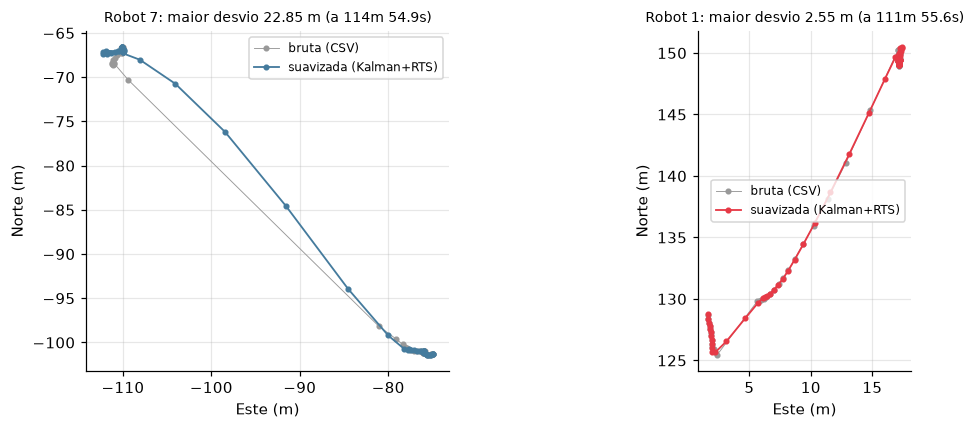

In [49]:
# Onde é que o suavizador mais altera a posição? Zoom nos 2 maiores desvios (Robot 7 e Robot 1)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, r in zip(axs, ("Robot 7", "Robot 1")):
    t = ds.trajectories[r]
    d = np.linalg.norm(t.pos_ned_raw - t.pos_ned, axis=0)
    k = int(np.argmax(d))
    s = slice(max(0, k - 30), k + 30)
    ax.plot(t.pos_ned_raw[1, s], t.pos_ned_raw[0, s], "o-", ms=3, lw=0.6, color="#999", label="bruta (CSV)")
    ax.plot(t.pos_ned[1, s], t.pos_ned[0, s], "o-", ms=3, lw=1.2, color=COR[r], label="suavizada (Kalman+RTS)")
    ax.set_aspect("equal"); ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)")
    ax.set_title(f"{r}: maior desvio {d[k]:.2f} m (a {tmiss(t.timestamps[k])})", fontsize=9); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretação (sem exagerar).**

1. Em média, a posição suavizada difere da bruta **menos de 3 cm** nos três robôs (percentil 95 abaixo de 5 cm): o filtro **quase não altera** o rasto, porque as medições são consideradas muito precisas (incerteza de poucos centímetros, Capítulo 3).
2. Os **máximos** (2,55 m no Robot 1; 22,8 m no Robot 7) acontecem junto dos **saltos de posição** (no Robot 7 há um passo bruto de cerca de 40 m entre duas amostras seguidas). Aí o suavizador distribui o salto por vários pontos em vez de o deixar como um degrau, o que arrasta alguns pontos vizinhos. Não elimina os saltos: continuam assinalados, calculados sobre os dados **brutos**.
3. O benefício principal é a **velocidade**: a velocidade estimada tem um ruído de curto prazo muito inferior ao das diferenças finitas (última coluna). É esta velocidade que alimenta a velocidade longitudinal, a previsão de 60 s e o CPA.
4. Nenhuma melhoria da *posição* é afirmada: não há aqui uma "verdade" independente para a comparar.

## 8.6 Validação com dados sintéticos (a mesma do teste automático)

Como não há "verdade" nos dados reais, a redução de ruído valida-se com uma trajetória sintética **conhecida** (movimento retilíneo uniforme com ruído gaussiano), como em `test_rts_reduces_noise`:

RMSE da posição ruidosa    : 0.966 m
RMSE da posição suavizada  : 0.230 m   (razão 0.24; o teste exige menos de 0,60)
Velocidade estimada média (nos pontos 10 a -10): [ 1.999 -1.001  0.185] m por s   (verdade: 2, -1, 0.2)


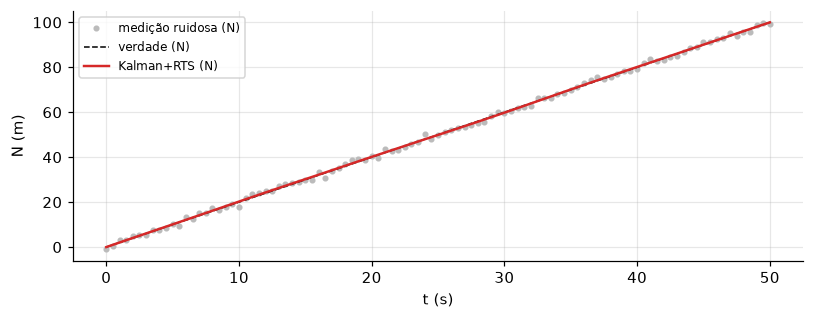

In [50]:
t = np.linspace(0, 50, 101)
verdade = np.stack([2.0 * t, -1.0 * t, 0.2 * t])                    # velocidade constante (2, -1, 0.2) m por s
ruidosa = verdade + np.random.default_rng(123).normal(0, 1.0, size=verdade.shape)   # ruído gaussiano, sigma = 1 m
sm_pos, sm_vel, _ = K.TrajectoryKalmanRTS(process_noise_q=0.01, default_meas_std=1.0).smooth(t, ruidosa)
rm = lambda a: np.sqrt(np.mean((a - verdade) ** 2))
print(f"RMSE da posição ruidosa    : {rm(ruidosa):.3f} m")
print(f"RMSE da posição suavizada  : {rm(sm_pos):.3f} m   (razão {rm(sm_pos)/rm(ruidosa):.2f}; o teste exige menos de 0,60)")
print("Velocidade estimada média (nos pontos 10 a -10):", np.round(sm_vel[:, 10:-10].mean(axis=1), 3), "m por s   (verdade: 2, -1, 0.2)")

fig, ax = plt.subplots(figsize=(7.5, 3))
ax.plot(t, ruidosa[0], ".", color="#bbb", label="medição ruidosa (N)")
ax.plot(t, verdade[0], "k--", lw=1, label="verdade (N)")
ax.plot(t, sm_pos[0], color="#d62828", lw=1.6, label="Kalman+RTS (N)")
ax.set_xlabel("t (s)"); ax.set_ylabel("N (m)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretação.** Com ruído de 1 m, o filtro reduz o erro de posição de 0,97 m para 0,23 m (cerca de um quarto) e recupera a velocidade verdadeira (1,999; −1,001; 0,185 contra 2; −1; 0,2). É a evidência de que o algoritmo **funciona como estimador**; nos dados reais o seu efeito sobre a posição é pequeno porque o ruído já era baixo.

## 8.7 Comparação com a interpolação linear e a spline (benchmark do projeto)

O comando `--benchmark` compara três métodos retirando pontos: ajusta cada método a 1 ponto em cada 6 e mede o erro nos restantes (`compare_interpolators_on_trajectory`, `interpolators.py`). **Atenção:** o benchmark do projeto usa como "verdade" a própria trajetória **já suavizada** pelo RTS (`traj.pos_ned`). Isso favorece métodos que interpolam bem curvas suaves. Para ser justo mostra-se também com as posições **brutas** (`pos_ned_raw`).

In [51]:
from multi_robot_system.core.math.interpolators import compare_interpolators_on_trajectory
linhas = []
for fonte, nome in (("pos_ned", "suavizada (como no --benchmark)"), ("pos_ned_raw", "bruta (CSV)")):
    for r in IDS:
        t = ds.trajectories[r]
        res = compare_interpolators_on_trajectory(t.timestamps, getattr(t, fonte), subsample_factor=6)
        for metodo, m in res.items():
            linhas.append({"Verdade": nome, "Robô": r, "Método": metodo, "RMSE (m)": m["rmse_m"], "Erro máx. (m)": m["max_err_m"]})
bench = pd.DataFrame(linhas)
tab = bench.groupby(["Verdade", "Método"])[["RMSE (m)", "Erro máx. (m)"]].mean().round(4)
display(tab)

RMSE (m)  Erro máx. (m)
Verdade                         Método                                
bruta (CSV)                     Kalman + RTS     0.2615        11.3113
                                Linear           0.2504        12.7280
                                Spline Cúbica    0.2572        13.2366
suavizada (como no --benchmark) Kalman + RTS     0.1738         5.2410
                                Linear           0.1460         4.9258
                                Spline Cúbica    0.1236         4.3452

**Interpretação (importante).** Em ambos os casos, **o Kalman+RTS é o método com maior RMSE**, embora por pouco quando a verdade é a trajetória bruta (0,262 m, contra 0,250 m da interpolação linear e 0,257 m da spline). Quem ganha depende da "verdade" usada: a linear com os dados brutos, a spline com os dados suavizados (0,124 m, contra 0,146 m da linear e 0,174 m do Kalman). Os erros máximos (4 a 13 m) vêm dos saltos de posição. Portanto **não se afirma** que o Kalman melhora a interpolação. O papel do Kalman no projeto é outro: **estimar a velocidade** e alisar ligeiramente a posição, com uma incerteza associada. A comparação existe para o grupo conhecer as alternativas e o seu custo.

## 8.8 Limitações do filtro tal como está implementado

- **Modelo de velocidade constante.** Em curvas fechadas o modelo é uma aproximação; o ruído de processo $q$ absorve o erro.
- **Medição só de posição.** A velocidade medida pelo robô (`twist`) e o yaw rate **não** entram no filtro (poderiam, como trabalho futuro).
- **$q$ fixo e igual nos três eixos**, e **$\mathbf{R}_k$ limitado** a $[0{,}05;20]$ m: a incerteza declarada abaixo de 5 cm nunca é usada.
- **Offline.** O suavizador RTS precisa do registo completo; não serve para tempo real.
- **O parâmetro `filter.default_meas_std_m` do YAML não é lido**: o valor 0,8 m está fixo no código.
- A covariância posterior $\mathbf{P}$ é guardada em `cov_diag` mas **não é usada** pelo dashboard (usa-se a incerteza declarada no CSV, `sigma_h_decl`, no Cockpit).

<a id="cap9"></a>
# CAPÍTULO 9 — DISTÂNCIAS

## 9.1 O problema

Para dizer se dois robôs estão perto um do outro é preciso um número: **a distância entre eles**. O projeto usa a **distância euclidiana tridimensional** entre as posições NED suavizadas (Capítulo 8). Não existe nenhuma medição direta da distância entre robôs (nenhum sonar ou acústica entre veículos): a distância é **calculada** a partir das posições de cada um, que estão num referencial comum (Capítulo 4).

## 9.2 Fundamentação matemática

Sejam $\mathbf{p}_i=(N_i,E_i,D_i)$ e $\mathbf{p}_j=(N_j,E_j,D_j)$ as posições em NED, em metros. A diferença e a distância 3D são

$$\Delta\mathbf{p}=\mathbf{p}_j-\mathbf{p}_i=\begin{bmatrix}\Delta N\\\Delta E\\\Delta D\end{bmatrix},\qquad d_{3D}=\|\Delta\mathbf{p}\|=\sqrt{\Delta N^2+\Delta E^2+\Delta D^2}$$

Distinguem-se ainda duas projeções, que o programa não usa como critério mas que ajudam a interpretar:

$$d_{H}=\sqrt{\Delta N^2+\Delta E^2}\ \text{(distância horizontal)},\qquad d_{V}=|\Delta D|\ \text{(separação vertical)},\qquad d_{3D}^2=d_H^2+d_V^2$$

**Hipóteses e aproximações.**

1. **Plano tangente local.** NED é um referencial plano, tangente à Terra na origem (Capítulo 4). A distância calculada é a corda no plano, não o arco sobre o elipsoide. O erro cresce com o quadrado da distância à origem: aproximadamente $\dfrac{r^2}{2R}$, com $R\approx6{,}371\times10^{6}$ m. A secção 9.5 calcula este valor para os dados reais.
2. **Mesmo instante.** Os robôs são amostrados em instantes diferentes (Capítulo 3). A distância só se calcula depois de **interpolar** as duas posições para o mesmo instante (`np.interp`, linear).
3. **Só existe distância quando os dois robôs têm dados.** Fora da janela de um robô, o par não existe (não é um erro, nem uma distância infinita).
4. **A incerteza das posições não é propagada** para a distância: o programa dá um número, não um intervalo.

## 9.3 Implementação: onde e como é calculada

A distância entre robôs é calculada em **três** sítios, com a mesma fórmula mas grelhas de tempo diferentes. Convém saber qual é qual:

| Onde | Função | Grelha de tempo | Para quê |
|---|---|---|---|
| `mission_report.py` | `compute_mission_report` | **1 s**, só na janela comum do par | Relatório, mínimos, tempos abaixo dos limiares, encontros |
| `web_server.py` (JavaScript) | `pairDistance`, `updateProximityBanner`, `detectCollision` | **2 s** (a grelha do navegador, posições arredondadas ao centímetro) | Faixa de aviso, colisão, painel de vizinhos |
| `plotly_views.py` | `create_proximity_timeline_figure` | **2 s**, com `NaN` fora da janela de cada robô | Gráfico "Distâncias" |

In [52]:
mostrar_js("pairDistance")
print()
mostrar_codigo(compute_mission_report, de="times = np.arange(lo, hi", ate="d = np.linalg.norm(pa - pb, axis=0)")

# multi_robot_system/visualization/web_server.py, linhas 1904 a 1907
1904          function pairDistance(ra, rb, k) {
1905              const dn = ra.N[k] - rb.N[k], de = ra.E[k] - rb.E[k], dd = ra.D[k] - rb.D[k];
1906              return Math.sqrt(dn * dn + de * de + dd * dd);
1907          }

# multi_robot_system/core/data/mission_report.py, linhas 53 a 56
  53              times = np.arange(lo, hi + 1e-9, dt_s)
  54              pa = np.vstack([np.interp(times, ta.timestamps, ta.pos_ned[k]) for k in range(3)])
  55              pb = np.vstack([np.interp(times, tb.timestamps, tb.pos_ned[k]) for k in range(3)])
  56              d = np.linalg.norm(pa - pb, axis=0)


**Explicação linha a linha**

- `pairDistance`: o JavaScript calcula $\sqrt{dn^2+de^2+dd^2}$ diretamente, sem `Math.hypot`. `ra.N[k]` é a posição Norte do robô A no passo $k$ da grelha.
- `lo = max(início A, início B)` e `hi = min(fim A, fim B)`: a **janela comum** do par. O relatório só calcula distâncias aí.
- `times = np.arange(lo, hi + 1e-9, dt_s)`: grelha de 1 s dentro da janela.
- `np.vstack([np.interp(times, ta.timestamps, ta.pos_ned[k]) for k in range(3)])`: interpola as **três componentes** do robô A para a grelha; o mesmo para B.
- `d = np.linalg.norm(pa - pb, axis=0)`: norma euclidiana de cada coluna da diferença: a distância 3D em cada instante.

## 9.4 Exemplo numérico: uma distância à mão

Usa-se o instante de maior aproximação entre o Robot 1 e o Robot 4 (calculado pelo programa na secção 4.8).

In [53]:
p1 = est["Robot 1"]["pos_ned"]; p4 = est["Robot 4"]["pos_ned"]
dp = p4 - p1
print(f"Instante: {tmiss(TE)}")
print("p1 (N, E, D) =", np.round(p1, 3), "m")
print("p4 (N, E, D) =", np.round(p4, 3), "m")
print("Δp = p4 - p1 =", np.round(dp, 3), "m\n")
print(f"ΔN² + ΔE² + ΔD² = {dp[0]**2:.3f} + {dp[1]**2:.3f} + {dp[2]**2:.3f} = {np.sum(dp**2):.3f} m²")
print(f"d3D = raiz = {np.sqrt(np.sum(dp**2)):.3f} m")
print(f"d horizontal = {np.hypot(dp[0], dp[1]):.3f} m;   separação vertical |ΔD| = {abs(dp[2]):.3f} m")
print(f"\nValor do programa (relatório, grelha de 1 s): d_min = {par14['d_min']:.3f} m")
print(f"Diferença: {abs(np.linalg.norm(dp) - par14['d_min']):.4f} m (TE é exatamente o instante da grelha de 1 s do relatório em que a distância é mínima)")

Instante: 54m 9.3s
p1 (N, E, D) = [52.089 82.591 28.598] m
p4 (N, E, D) = [ 32.02  101.633  27.802] m
Δp = p4 - p1 = [-20.069  19.041  -0.796] m

ΔN² + ΔE² + ΔD² = 402.781 + 362.572 + 0.634 = 765.987 m²
d3D = raiz = 27.676 m
d horizontal = 27.665 m;   separação vertical |ΔD| = 0.796 m

Valor do programa (relatório, grelha de 1 s): d_min = 27.676 m
Diferença: 0.0000 m (TE é exatamente o instante da grelha de 1 s do relatório em que a distância é mínima)


**Interpretação.** A conta à mão coincide com o valor do relatório até à precisão da grelha. Repara-se que a maior parte da distância é **horizontal**: os dois robôs navegam a profundidades próximas, por isso a separação vertical pesa pouco.

## 9.5 Distâncias ao longo da missão

Calcula-se a matriz de distâncias para os três pares e compara-se com a que o dashboard recebe. Para isso reconstrói-se o objeto `timeline` que o Python envia ao navegador (`MissionWebDashboard.build_dashboard_html`) e lê-se de lá a grelha de 2 s, que é o que o JavaScript usa.

In [54]:
import json
from multi_robot_system.visualization.web_server import MissionWebDashboard
_html = MissionWebDashboard(ds, cfg).build_dashboard_html()
_i = _html.index("const timeline = ") + len("const timeline = ")
TL, _ = json.JSONDecoder().raw_decode(_html[_i:])          # exatamente o que o JavaScript recebe
print(f"HTML do dashboard: {len(_html) / 1e6:.1f} MB;  timeline: {TL['num_steps']} passos de {TL['dt_step']:g} s;  chaves: {', '.join(k for k in TL if k != 'scene')}")
print("Limiares no dashboard (m): perigo", TL["collision_threshold_m"], "| aviso", TL["proximity_warning_m"], "| contacto", TL["contact_distance_m"])

PARES = [("Robot 1", "Robot 4"), ("Robot 1", "Robot 7"), ("Robot 4", "Robot 7")]
K_ = np.arange(TL["num_steps"])
def dist_2s(a, b):
    """Réplica Python de pairDistance sobre a grelha de 2 s do dashboard; NaN fora da janela comum."""
    ra, rb = TL["robots"][a], TL["robots"][b]
    d = np.sqrt((np.array(ra["N"]) - rb["N"]) ** 2 + (np.array(ra["E"]) - rb["E"]) ** 2 + (np.array(ra["D"]) - rb["D"]) ** 2)
    ativo = (K_ >= max(ra["k0"], rb["k0"])) & (K_ <= min(ra["k1"], rb["k1"]))
    return np.where(ativo, d, np.nan)

linhas = []
for a, b in PARES:
    p = next(q for q in rep["pairs"] if (q["a"], q["b"]) == (a, b))
    d2 = dist_2s(a, b)
    linhas.append({"Par": f"{a} - {b}",
                   "Janela comum": f"{tmiss(T0 + p['overlap'][0])} a {tmiss(T0 + p['overlap'][1])}",
                   "d mínima (relatório, 1 s)": p["d_min"], "em": tmiss(T0 + p["t_min"]),
                   "d mínima (dashboard, 2 s)": np.nanmin(d2), "diferença (m)": np.nanmin(d2) - p["d_min"],
                   "tempo < 60 m (s)": p["below"]["w60"], "< 30 m (s)": p["below"]["w30"], "< 10 m (s)": p["below"]["w10"]})
tab_d = pd.DataFrame(linhas).set_index("Par")
display(tab_d.round(2).T)

# Curvatura da Terra ignorada pelo plano NED
alc = max(np.hypot(ds.trajectories[r].pos_ned[0], ds.trajectories[r].pos_ned[1]).max() for r in IDS)
print(f"\nMaior afastamento horizontal à origem em todos os robôs: {alc:.0f} m  ->  erro do plano tangente ≈ r² / (2 R) = {alc**2 / (2 * 6.371e6) * 1000:.1f} mm")

HTML do dashboard: 3.2 MB;  timeline: 4007 passos de 2 s;  chaves: dt_step, t0_base, t_max, num_steps, axis_length_m, collision_threshold_m, proximity_warning_m, contact_distance_m, radar_range_m, robots, origin, sub_mesh, sub_text, report
Limiares no dashboard (m): perigo 10.0 | aviso 30.0 | contacto 2.0


Par,Robot 1 - Robot 4,Robot 1 - Robot 7,Robot 4 - Robot 7
Janela comum,29m 59.3s a 69m 55.5s,29m 59.3s a 114m 49.1s,20m 0.2s a 69m 55.5s
"d mínima (relatório, 1 s)",27.68,174.95,206.69
em,54m 9.3s,37m 21.3s,36m 33.2s
"d mínima (dashboard, 2 s)",27.73,174.99,206.69
diferença (m),0.05,0.03,-0.0
tempo < 60 m (s),950.0,0.0,0.0
< 30 m (s),28.0,0.0,0.0
< 10 m (s),0.0,0.0,0.0



Maior afastamento horizontal à origem em todos os robôs: 239 m  ->  erro do plano tangente ≈ r² / (2 R) = 4.5 mm


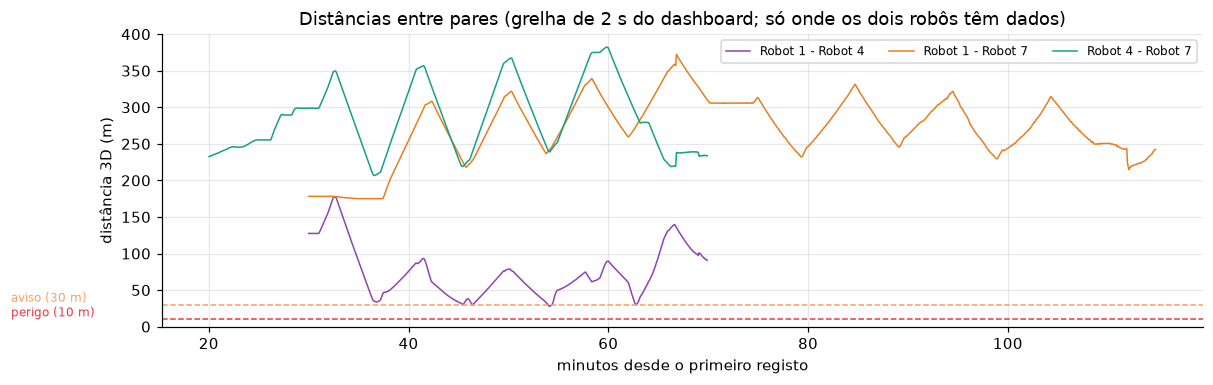

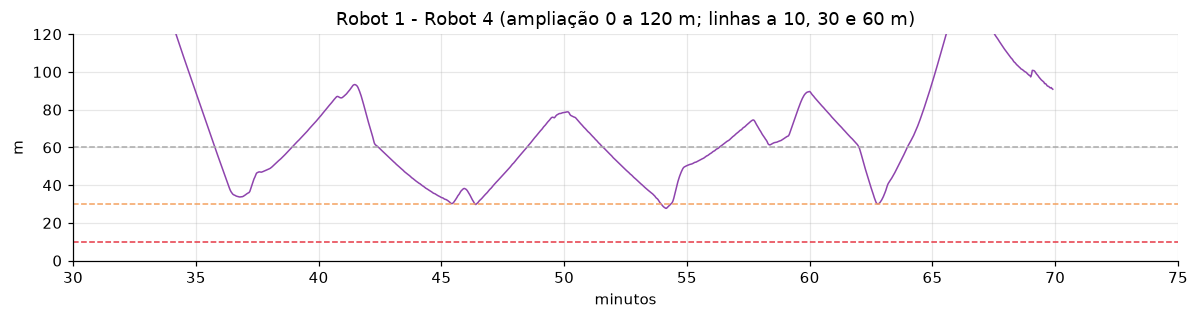

In [55]:
fig, ax = plt.subplots(figsize=(11, 3.6))
cores = {("Robot 1", "Robot 4"): "#8e44ad", ("Robot 1", "Robot 7"): "#e67e22", ("Robot 4", "Robot 7"): "#16a085"}
for (a, b) in PARES:
    ax.plot(K_ * TL["dt_step"] / 60, dist_2s(a, b), color=cores[(a, b)], lw=1.0, label=f"{a} - {b}")
for lim, cor, nome in ((TL["collision_threshold_m"], "#e63946", "perigo (10 m)"), (TL["proximity_warning_m"], "#f4a261", "aviso (30 m)")):
    ax.axhline(lim, color=cor, ls="--", lw=1); ax.text(0.2, lim + 4, nome, color=cor, fontsize=8)
ax.set_ylim(0, 400); ax.set_xlabel("minutos desde o primeiro registo"); ax.set_ylabel("distância 3D (m)")
ax.set_title("Distâncias entre pares (grelha de 2 s do dashboard; só onde os dois robôs têm dados)"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 3.0))
p14 = dist_2s("Robot 1", "Robot 4")
ax.plot(K_ * TL["dt_step"] / 60, p14, color="#8e44ad", lw=1.0)
for lim, cor in ((TL["collision_threshold_m"], "#e63946"), (TL["proximity_warning_m"], "#f4a261"), (60, "#aaa")):
    ax.axhline(lim, color=cor, ls="--", lw=1)
ax.set_ylim(0, 120); ax.set_xlim(30, 75); ax.set_xlabel("minutos"); ax.set_ylabel("m")
ax.set_title("Robot 1 - Robot 4 (ampliação 0 a 120 m; linhas a 10, 30 e 60 m)")
plt.tight_layout(); plt.show()

**Interpretação.**

1. **Nenhum par chegou a 10 m**, e muito menos a 2 m. A menor distância de toda a missão é entre o Robot 1 e o Robot 4: cerca de 27,7 m, aos 54 min 9 s. O Robot 7 nunca se aproxima dos outros a menos de 170 m.
2. A diferença entre a grelha de 1 s (relatório) e a de 2 s (dashboard) é de **centímetros**: a grelha de 2 s e o arredondamento ao centímetro não alteram nenhuma conclusão.
3. O erro do plano tangente é de **milímetros** para os afastamentos desta missão (no máximo cerca de 240 m). Não afeta nenhum limiar.
4. Os tempos abaixo de 60 m e de 30 m dependem da definição de "encontro" do relatório: 60 m define o encontro, 30 m o aviso, 10 m o perigo.

## 9.6 Sensibilidade: usar posições brutas ou suavizadas

A distância mínima muda se se usarem as posições brutas (`pos_ned_raw`) em vez das suavizadas? Esta é a pergunta que mostra se o filtro do Capítulo 8 alterou as conclusões de segurança.

In [56]:
def dmin_par(a, b, campo, dt=1.0):
    ta, tb = ds.trajectories[a], ds.trajectories[b]
    lo, hi = max(ta.timestamps[0], tb.timestamps[0]), min(ta.timestamps[-1], tb.timestamps[-1])
    t = np.arange(lo, hi + 1e-9, dt)
    pa = np.vstack([np.interp(t, ta.timestamps, getattr(ta, campo)[k]) for k in range(3)])
    pb = np.vstack([np.interp(t, tb.timestamps, getattr(tb, campo)[k]) for k in range(3)])
    d = np.linalg.norm(pa - pb, axis=0)
    return d.min(), t[d.argmin()] - T0

linhas = []
for a, b in PARES:
    ds_, ts_ = dmin_par(a, b, "pos_ned"); db_, tb_ = dmin_par(a, b, "pos_ned_raw")
    linhas.append({"Par": f"{a} - {b}", "d mínima suavizada (m)": ds_, "d mínima bruta (m)": db_, "diferença (m)": db_ - ds_, "instantes": f"{ts_:.0f} s e {tb_:.0f} s"})
display(pd.DataFrame(linhas).set_index("Par").round(3))

,d mínima suavizada (m),d mínima bruta (m),diferença (m),instantes
Par,,,,
Robot 1 - Robot 4,27.676,27.661,-0.015,3249 s e 3249 s
Robot 1 - Robot 7,174.953,174.951,-0.002,2241 s e 2241 s
Robot 4 - Robot 7,206.692,206.692,-0.000,2193 s e 2193 s


**Interpretação.** A distância mínima praticamente não depende de se usarem posições brutas ou suavizadas (diferença na ordem dos centímetros ou menos). A conclusão "os robôs não se aproximaram abaixo de 27 m" não depende do filtro.

## 9.7 Limitações

- A distância é **entre as posições de referência** dos robôs (os pontos a que o CSV se refere). **Não** considera o tamanho dos veículos: dois robôs "a 2 m" podem estar em contacto físico se o casco for maior do que isso. A malha 3D do dashboard é só visual.
- Sem propagação de incerteza: não há intervalo de confiança na distância.
- A interpolação linear entre amostras pode suavizar mudanças bruscas (saltos de posição, Capítulo 3), e um salto pode **criar ou esconder** uma aproximação. O relatório assinala se um encontro está perto de um salto (`jump_near`).

<a id="cap10"></a>
# CAPÍTULO 10 — PROXIMIDADE E RISCO DE COLISÃO

## 10.1 O que o projeto faz — e o que não faz

Este capítulo separa três coisas diferentes, que é importante não confundir:

| Capacidade | O que significa | No projeto |
|---|---|---|
| **Deteção** | Dizer que, **agora**, dois robôs estão perto | **Sim.** Compara a distância atual com os limiares: aviso (30 m), perigo (10 m), contacto (2 m). |
| **Previsão de risco** | Estimar o que vai acontecer **se nada mudar** | **Parcial.** Calcula o CPA e o TCPA com movimento em linha reta (60 s). Mostra-os no painel de vizinhos e na previsão desenhada, mas o **alerta do dashboard não depende deles**. |
| **Prevenção** | Agir para evitar a colisão | **Não.** O programa não envia comandos aos robôs, não planeia desvios, não altera trajetórias. É um **visualizador de dados já gravados**. |

A secção 10.8 mostra a evidência desta tabela no código.

## 10.2 Os limiares

Vêm da secção `spatial` do ficheiro de configuração (`mission_config.yaml`), com valores por omissão no código:

| Chave | Valor | Efeito |
|---|---|---|
| `collision_threshold_m` | 10 m | abaixo disto: **PERIGO DE COLISÃO** (faixa vermelha a piscar) |
| `proximity_warning_m` | 30 m | abaixo disto: **ATENÇÃO** (faixa amarela); no código nunca é inferior ao limiar de perigo |
| `contact_distance_m` | 2 m | abaixo disto: **COLISÃO** (o *Play* pára, os dois robôs ficam parados na visualização) |
| encontro (fixo no código) | 60 m | só no relatório: um "encontro" é um período contínuo abaixo de 60 m |

In [57]:
import yaml
print(yaml.safe_dump({"spatial": cfg["spatial"]}, allow_unicode=True, sort_keys=False))
print("Encontro (relatório):", rep["thresholds"]["encounter"], "m   (valor por omissão de compute_mission_report; não vem do YAML)")
from multi_robot_system.core.data import mission_report as MR
mostrar_codigo(MR._level)

spatial:
  neighbor_radius_m: 250.0
  collision_threshold_m: 10.0
  contact_distance_m: 2.0
  proximity_warning_m: 30.0
  radar_range_m: 100.0
  seabed_margin_m: 5.0

Encontro (relatório): 60.0 m   (valor por omissão de compute_mission_report; não vem do YAML)
# multi_robot_system/core/data/mission_report.py, linhas 14 a 20
  14  def _level(d_min: float, danger_m: float, warning_m: float) -> str:
  15      """Classifica a distância mínima de um encontro: perigo, atenção ou simples aproximação."""
  16      if d_min < danger_m:
  17          return "perigo"
  18      if d_min < warning_m:
  19          return "atencao"
  20      return "aproximacao"


## 10.3 Deteção: faixa de proximidade

A cada instante, o JavaScript percorre os pares de robôs **ativos** (dentro da sua janela), calcula a distância 3D e escolhe o nível:

In [58]:
mostrar_js("updateProximityBanner")

# multi_robot_system/visualization/web_server.py, linhas 1965 a 1993
1965          // ---------- Aviso de proximidade (Vista Global e Vista 3ª Pessoa) ----------
1966          // Amarelo: dois robôs ativos a menos de proximity_warning_m. Vermelho a piscar: menos de collision_threshold_m.
1967          // Método: para cada par de robôs ativos, distância 3D = raiz de (dN2 + dE2 + dD2).
1968          // Obtemos: faixa amarela (abaixo do aviso) ou vermelha a piscar (abaixo do limiar de colisão).
1969          function updateProximityBanner(f) {
1970              const box = document.getElementById('proximity-banner');
1971              if (!box) return;
1972              if (currentView !== 'global' && currentView !== 'pov' && currentView !== 'fp') { box.style.display = 'none'; return; }
1973              box.style.top = (currentView === 'fp' && hudOn) ? '124px' : '28px';   // na 1ª pessoa fica por baixo da fita de rumo
1974              const act = robotKeys.filter(id => isActive(timeline

**Explicação linha a linha.**

- `act = robotKeys.filter(...)`: só os robôs com dados neste instante.
- Dois ciclos `for i... for j > i`: todos os pares, sem repetir.
- `a = stateAt(...)`, `b = stateAt(...)`: posições interpoladas no instante atual (secção 7.7).
- `d = Math.sqrt(...)`: a distância 3D da secção 9.2.
- `if (d < timeline.proximity_warning_m) near.push(...)`: só entram na lista os pares abaixo dos 30 m.
- `danger = col !== null || near[0].d < timeline.collision_threshold_m`: **vermelho** se existe colisão ou se o par mais próximo está abaixo de 10 m; senão **amarelo**.
- O texto é "COLISÃO", "PERIGO DE COLISÃO" ou "ATENÇÃO: ROBOTS PRÓXIMOS".

A deteção é, portanto, **só uma comparação de distância atual com um limiar**: não há memória, não há previsão.

## 10.4 Previsão: o ponto de maior aproximação (CPA)

**O problema.** Dois robôs a 40 m um do outro podem estar a afastar-se ou a convergir. A distância atual não distingue os dois casos. O CPA (*Closest Point of Approach*) responde: **se ambos mantiverem a velocidade, qual será a menor distância e quando?**

**Fundamentação.** Com posições $\mathbf{p}_i,\mathbf{p}_j$ e velocidades $\mathbf{v}_i,\mathbf{v}_j$ constantes, a posição relativa evolui como

$$\mathbf{r}(t)=\Delta\mathbf{p}+\Delta\mathbf{v}\,t,\qquad \Delta\mathbf{p}=\mathbf{p}_j-\mathbf{p}_i,\quad \Delta\mathbf{v}=\mathbf{v}_j-\mathbf{v}_i$$

O quadrado da distância é um polinómio do segundo grau em $t$:

$$\|\mathbf{r}(t)\|^2=\|\Delta\mathbf{p}\|^2+2\,(\Delta\mathbf{p}\cdot\Delta\mathbf{v})\,t+\|\Delta\mathbf{v}\|^2\,t^2$$

Derivando e igualando a zero obtém-se o instante da menor distância (TCPA) e a distância nesse instante (CPA):

$$t^{*}=-\frac{\Delta\mathbf{p}\cdot\Delta\mathbf{v}}{\|\Delta\mathbf{v}\|^2},\qquad d_{CPA}=\|\Delta\mathbf{p}+\Delta\mathbf{v}\,t^{*}\|$$

O sinal do produto escalar diz se os robôs convergem ($\Delta\mathbf{p}\cdot\Delta\mathbf{v}<0$, $t^{*}>0$) ou divergem ($t^{*}\le0$).

**Casos especiais tratados no código:**

1. $\|\Delta\mathbf{v}\|^2<10^{-8}$: velocidade relativa nula; a distância mantém-se: $t^{*}=0$, $d_{CPA}=\|\Delta\mathbf{p}\|$.
2. $t^{*}\le0$: a afastar-se; a menor distância futura é a atual: $t^{*}=0$, $d_{CPA}=\|\Delta\mathbf{p}\|$.
3. $t^{*}>60$ s: o horizonte é limitado a 60 s: usa-se $t=60$ e $d_{CPA}$ é a distância **aos 60 s**, que **não** é o mínimo verdadeiro (o mínimo estaria mais à frente).

In [59]:
from multi_robot_system.core.math import proximity as PX
mostrar_codigo(PX.compute_analytic_cpa)

# multi_robot_system/core/math/proximity.py, linhas 62 a 95
  62  def compute_analytic_cpa(
  63      p1: np.ndarray,
  64      v1: np.ndarray,
  65      p2: np.ndarray,
  66      v2: np.ndarray,
  67      lookahead_limit_s: float = 60.0
  68  ) -> Tuple[float, float]:
  69      """Calcula analiticamente o instante (t_cpa em s) e a distância mínima (d_cpa em m).
  70  
  71      Baseado na cinemática linear: r(t) = Delta_p + Delta_v * t.
  72      """
  73      dp = p2 - p1
  74      dv = v2 - v1
  75  
  76      dv_sq = float(np.dot(dv, dv))
  77      dp_sq = float(np.dot(dp, dp))
  78  
  79      # Se a velocidade relativa for praticamente nula, distância mantém-se constante
  80      if dv_sq < 1e-8:
  81          return 0.0, float(np.sqrt(max(0.0, dp_sq)))
  82  
  83      # t_cpa = - (dp . dv) / ||dv||^2
  84      t_cpa_raw = -float(np.dot(dp, dv)) / dv_sq
  85  
  86      # Se t_cpa for negativo, os robôs estão a afastar-se; a menor distância futura é agora (t=0)
  87      if t_c

**Explicação linha a linha**

- `dp = p2 - p1` e `dv = v2 - v1`: $\Delta\mathbf{p}$ e $\Delta\mathbf{v}$.
- `dv_sq = float(np.dot(dv, dv))`: $\|\Delta\mathbf{v}\|^2$; `dp_sq` é $\|\Delta\mathbf{p}\|^2$.
- `if dv_sq < 1e-8`: caso 1.
- `t_cpa_raw = -float(np.dot(dp, dv)) / dv_sq`: $t^{*}$.
- `if t_cpa_raw <= 0.0`: caso 2. Caso contrário, `t_cpa = min(t_cpa_raw, lookahead_limit_s)` (caso 3) e `d_cpa = norm(dp + dv * t_cpa)`.

### Os três testes automáticos do projeto, reproduzidos

`tests/test_cpa.py` testa três situações com solução conhecida. Reproduzem-se aqui, com a resposta esperada calculada à mão:

In [60]:
casos = [
    ("Frente a frente", [0, 0, 0], [2, 0, 0], [100, 0, 0], [-3, 0, 0], "t* = 100 a dividir por (2+3) = 20 s; d = 0 m"),
    ("Passagem perpendicular", [0, -50, 0], [0, 5, 0], [8, 0, 0], [0, 0, 0], "t* = 50 a dividir por 5 = 10 s; d = 8 m"),
    ("A afastar-se", [0, 0, 0], [-1, 0, 0], [20, 0, 0], [1, 0, 0], "t* <= 0 -> t = 0 s; d = 20 m (distância atual)"),
]
linhas = []
for nome, p1_, v1_, p2_, v2_, esperado in casos:
    t_, d_ = PX.compute_analytic_cpa(*(np.array(x, float) for x in (p1_, v1_, p2_, v2_)))
    linhas.append({"Caso": nome, "TCPA (s)": t_, "CPA (m)": d_, "Esperado (à mão)": esperado})
display(pd.DataFrame(linhas).set_index("Caso").round(6))

,TCPA (s),CPA (m),Esperado (à mão)
Caso,,,
Frente a frente,20.0,0.0,t* = 100 a dividir por (2+3) = 20 s; d = 0 m
Passagem perpendicular,10.0,8.0,t* = 50 a dividir por 5 = 10 s; d = 8 m
A afastar-se,0.0,20.0,t* <= 0 -> t = 0 s; d = 20 m (distância atual)


**Interpretação.** Os três casos dão o resultado calculado à mão. Isto valida o código nos casos limpos (movimento exatamente retilíneo uniforme). Os dados reais não satisfazem essa hipótese; a secção 10.6 mede o efeito.

## 10.5 Exemplo numérico com dados reais

Escolhe-se um instante 60 s antes da maior aproximação Robot 1 - Robot 4 e calcula-se o CPA à mão a partir dos estados do programa, comparando com `evaluate_proximity_and_cpa`.

In [61]:
t_ex = TE - 60.0
st = ds.get_state_at_time(t_ex)
p1_, v1_ = st["Robot 1"]["pos_ned"], st["Robot 1"]["vel_ned"]
p4_, v4_ = st["Robot 4"]["pos_ned"], st["Robot 4"]["vel_ned"]
dp_, dv_ = p4_ - p1_, v4_ - v1_
print(f"Instante: {tmiss(t_ex)}")
print("p1 =", np.round(p1_, 2), "  v1 =", np.round(v1_, 3))
print("p4 =", np.round(p4_, 2), "  v4 =", np.round(v4_, 3))
print("Δp =", np.round(dp_, 2), "m    Δv =", np.round(dv_, 3), "m por s")
print(f"\ndistância atual = |Δp| = {np.linalg.norm(dp_):.2f} m")
print(f"Δp · Δv = {dp_ @ dv_:.3f}   |Δv|² = {dv_ @ dv_:.4f}")
t_star = -(dp_ @ dv_) / (dv_ @ dv_)
print(f"t* = -(Δp·Δv) / |Δv|² = {t_star:.2f} s   ->   {'dentro do horizonte de 60 s' if 0 < t_star <= 60 else 'fora do horizonte útil'}")
t_use = min(max(t_star, 0.0), 60.0)
print(f"CPA = |Δp + Δv t*| = {np.linalg.norm(dp_ + dv_ * t_use):.2f} m")

res = next(c for c in ds.evaluate_cpa_at_time(t_ex) if (c.robot_i, c.robot_j) == ("Robot 1", "Robot 4"))
print(f"\nPrograma (evaluate_proximity_and_cpa): distância {res.current_distance_m:.2f} m; TCPA {res.time_to_cpa_s:.2f} s; CPA {res.cpa_distance_m:.2f} m; risco = {res.is_collision_risk}")
print("Azimute, elevação e distância no corpo do Robot 1:", tuple(round(x, 2) for x in res.relative_aer))

d_real = np.linalg.norm(ds.get_state_at_time(t_ex + t_use)["Robot 4"]["pos_ned"] - ds.get_state_at_time(t_ex + t_use)["Robot 1"]["pos_ned"])
print(f"\nDistância REAL {t_use:.1f} s depois, nos dados: {d_real:.2f} m  (previsto: {np.linalg.norm(dp_ + dv_ * t_use):.2f} m)")

Instante: 53m 9.3s
p1 = [68.93 72.09 28.61]   v1 = [-0.463  0.001 -0.013]
p4 = [ 61.44 111.77  27.73]   v4 = [-0.573 -0.204 -0.048]
Δp = [-7.49 39.68 -0.89] m    Δv = [-0.109 -0.204 -0.036] m por s

distância atual = |Δp| = 40.39 m
Δp · Δv = -7.265   |Δv|² = 0.0550
t* = -(Δp·Δv) / |Δv|² = 132.01 s   ->   fora do horizonte útil
CPA = |Δp + Δv t*| = 30.95 m

Programa (evaluate_proximity_and_cpa): distância 40.39 m; TCPA 60.00 s; CPA 30.95 m; risco = False
Azimute, elevação e distância no corpo do Robot 1: (-76.81, -0.55, 40.39)

Distância REAL 60.0 s depois, nos dados: 27.68 m  (previsto: 30.95 m)


**Interpretação.** O cálculo à mão e o programa coincidem (distância, CPA e risco). Neste instante $t^{*}=132$ s está **fora do horizonte de 60 s**: é o caso especial 3, em que o programa usa $t=60$ s e o CPA (30,95 m) é a distância prevista **aos 60 s**, não o mínimo verdadeiro. A última linha confronta a previsão com a realidade: 27,68 m, ou seja, a previsão errou em cerca de 3 m. Uma amostra isolada não prova nada; a secção seguinte repete a comparação em toda a janela comum.

## 10.6 Quão boa é a previsão? Teste sistemático sobre os dados reais

Para cada instante da janela comum do par Robot 1 - Robot 4 (de 5 em 5 segundos): calcula-se o CPA previsto e compara-se com a distância **real** no instante previsto. Só entram os instantes em que os robôs convergem ($0<t^{*}\le60$ s).

Este teste **não faz parte do projeto**: é uma avaliação feita neste relatório para medir os limites da previsão em linha reta.

In [62]:
def estado_interp(r, t):
    tr = ds.trajectories[r]
    return (np.array([np.interp(t, tr.timestamps, tr.pos_ned[k]) for k in range(3)]),
            np.array([np.interp(t, tr.timestamps, tr.vel_ned[k]) for k in range(3)]))

a_, b_ = "Robot 1", "Robot 4"
lo = max(ds.trajectories[a_].timestamps[0], ds.trajectories[b_].timestamps[0]); hi = min(ds.trajectories[a_].timestamps[-1], ds.trajectories[b_].timestamps[-1])
linhas = []
for t in np.arange(lo, hi - 60.0, 5.0):
    pa, va = estado_interp(a_, t); pb, vb = estado_interp(b_, t)
    t_c, d_c = PX.compute_analytic_cpa(pa, va, pb, vb, 60.0)
    if t_c <= 0.0:
        continue                                           # a afastar-se ou velocidade relativa nula
    dpv, dvv = pb - pa, vb - va
    t_bruto = -(dpv @ dvv) / (dvv @ dvv)                   # t* sem o corte a 60 s
    qa, _ = estado_interp(a_, t + t_c); qb, _ = estado_interp(b_, t + t_c)
    d_real = np.linalg.norm(qb - qa)
    d_min_real = min(np.linalg.norm(estado_interp(b_, t + s)[0] - estado_interp(a_, t + s)[0]) for s in np.arange(0, 60.1, 2.0))
    linhas.append({"t": t - T0, "TCPA": t_c, "t_bruto": t_bruto, "d_atual": np.linalg.norm(pb - pa), "CPA_previsto": d_c, "d_real_em_TCPA": d_real, "d_min_real_60s": d_min_real})
av = pd.DataFrame(linhas)
av["erro_abs"] = (av["CPA_previsto"] - av["d_real_em_TCPA"]).abs()
av["classe"] = pd.cut(av["t_bruto"], [0, 20, 60, np.inf], labels=["t* até 20 s", "t* de 20 a 60 s", "t* acima de 60 s (cortado a 60 s)"])
print(f"{len(av)} instantes com aproximação (de {int((hi - lo - 60) // 5)} testados)")
res = av.groupby("classe", observed=True).agg(n=("erro_abs", "size"), erro_mediano_m=("erro_abs", "median"), erro_p90_m=("erro_abs", lambda x: np.percentile(x, 90)),
                                               distancia_atual_media_m=("d_atual", "mean")).round(2)
display(res)

# O que a previsão sobre a menor distância futura diz, comparado com o que aconteceu
av["subestima"] = av["CPA_previsto"] < av["d_min_real_60s"] - 5
print("Correlação entre CPA previsto e menor distância real nos 60 s seguintes:", round(np.corrcoef(av["CPA_previsto"], av["d_min_real_60s"])[0, 1], 3))
print("Menor CPA previsto em todos os testes: %.1f m;  menor distância real em qualquer instante testado + 60 s: %.1f m" % (av["CPA_previsto"].min(), av["d_min_real_60s"].min()))
# Ilustração (NÃO é uma regra do projeto): se o aviso fosse 'CPA previsto < 30 m', quantos avisos coincidiriam com uma distância real < 30 m nos 60 s seguintes?
prev, real = av["CPA_previsto"] < 30, av["d_min_real_60s"] < 30
print(f"\nAvisos hipotéticos (CPA previsto < 30 m): {int(prev.sum())};  destes, com distância real < 30 m nos 60 s seguintes: {int((prev & real).sum())};  instantes com distância real < 30 m sem aviso: {int((~prev & real).sum())}")

230 instantes com aproximação (de 467 testados)


,n,erro_mediano_m,erro_p90_m,distancia_atual_media_m
classe,,,,
t* até 20 s,10,1.05,4.51,42.88
t* de 20 a 60 s,25,8.95,18.31,58.85
t* acima de 60 s (cortado a 60 s),195,1.92,16.24,79.27


Correlação entre CPA previsto e menor distância real nos 60 s seguintes: 0.974
Menor CPA previsto em todos os testes: 12.6 m;  menor distância real em qualquer instante testado + 60 s: 27.7 m

Avisos hipotéticos (CPA previsto < 30 m): 42;  destes, com distância real < 30 m nos 60 s seguintes: 16;  instantes com distância real < 30 m sem aviso: 4


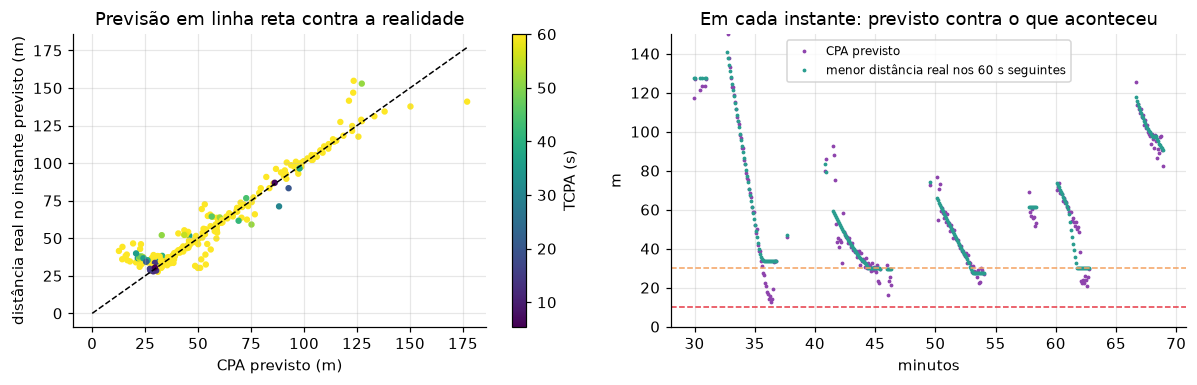

In [63]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axs[0]
sc = ax.scatter(av["CPA_previsto"], av["d_real_em_TCPA"], c=av["TCPA"], cmap="viridis", s=10)
m = max(av["CPA_previsto"].max(), av["d_real_em_TCPA"].max()); ax.plot([0, m], [0, m], "k--", lw=1)
ax.set_xlabel("CPA previsto (m)"); ax.set_ylabel("distância real no instante previsto (m)"); ax.set_title("Previsão em linha reta contra a realidade")
plt.colorbar(sc, ax=ax, label="TCPA (s)")
ax = axs[1]
ax.plot(av["t"] / 60, av["CPA_previsto"], ".", ms=3, color="#8e44ad", label="CPA previsto")
ax.plot(av["t"] / 60, av["d_min_real_60s"], ".", ms=3, color="#2a9d8f", label="menor distância real nos 60 s seguintes")
ax.axhline(30, color="#f4a261", ls="--", lw=1); ax.axhline(10, color="#e63946", ls="--", lw=1)
ax.set_xlabel("minutos"); ax.set_ylabel("m"); ax.set_ylim(0, 150); ax.legend(fontsize=8); ax.set_title("Em cada instante: previsto contra o que aconteceu")
plt.tight_layout(); plt.show()

**Interpretação.**

1. Em 230 dos 467 instantes testados os robôs convergem. Quando o CPA está a **menos de 20 s**, a previsão é boa (erro mediano de 1,05 m, percentil 90 de 4,5 m, mas só 10 casos). Quando está **entre 20 e 60 s**, o erro mediano sobe para cerca de 9 m (percentil 90 de 18 m, 25 casos): os robôs viram e mudam de velocidade, e o modelo assume movimento retilíneo uniforme. A amostra é pequena, por isso estes números são **indicativos**, não uma estatística robusta.
2. A maior parte dos casos (195) tem $t^{*}>60$ s e é cortada a 60 s: aí o valor previsto é a distância **aos 60 s**; o erro mediano é de 1,9 m, mas o percentil 90 é de 16 m.
3. A correlação alta (0,97) entre o CPA previsto e a menor distância real dos 60 s seguintes deve ser lida com cuidado: a maior parte dos instantes tem distâncias grandes e semelhantes, o que a favorece.
4. O ensaio hipotético com um aviso "CPA previsto abaixo de 30 m" (**não é uma regra do projeto**) dá 42 avisos, dos quais só 16 coincidiram com uma distância real abaixo de 30 m, e deixou passar 4 instantes. O CPA previsto chegou a 12,6 m quando a menor distância real nunca baixou de 27,7 m: **a previsão em linha reta pode subestimar a distância**, o que levaria a falsos alarmes.
5. O CPA é, portanto, um **indicador de tendência** (a convergir ou a afastar, e com que ordem de grandeza), **não uma garantia**. Um sistema de segurança real teria de ter em conta a incerteza e as manobras.
6. Como nenhum par chegou a 10 m, **não há aqui nenhum caso de verdadeiro perigo**: não é possível medir deteções corretas para o limiar de perigo. Fica como limitação dos dados.

## 10.7 Deteção de colisão (contacto)

O dashboard tem ainda uma deteção de **contacto**: o primeiro instante em que dois robôs ativos estão a menos de `contact_distance_m` (2 m). Se existir, o *Play* pára aí, aparece "COLISÃO" e os dois robôs ficam parados na visualização.

In [64]:
mostrar_js("detectCollision")

# multi_robot_system/visualization/web_server.py, linhas 1909 a 1929
1909          function detectCollision() {
1910              const lim = timeline.contact_distance_m || 2.0;
1911              let best = null;
1912              for (let i = 0; i < robotKeys.length; i++) {
1913                  for (let j = i + 1; j < robotKeys.length; j++) {
1914                      const ra = timeline.robots[robotKeys[i]], rb = timeline.robots[robotKeys[j]];
1915                      for (let k = 0; k < numSteps; k++) {
1916                          if (!(isActive(ra, k) && isActive(rb, k))) continue;
1917                          if (pairDistance(ra, rb, k) < lim) {
1918                              if (best === null || k < best.k) best = { k: k, a: robotKeys[i], b: robotKeys[j] };
1919                              break;
1920                          }
1921                      }
1922                  }
1923              }
1924              if (best === null) return;
1925              const ra =

**Explicação linha a linha**

- `lim = timeline.contact_distance_m || 2.0`: o limiar.
- Para cada par `(i, j)` e para cada passo `k` da grelha de 2 s, **só se ambos estão ativos** (`isActive`) e a distância é menor do que `lim`, guarda-se o **primeiro** $k$ (`best`) do par e passa-se ao par seguinte (`break`).
- `if (best === null || k < best.k)`: entre os pares, fica o contacto mais cedo.
- Se não houver contacto (`best === null`), a função termina sem fazer nada: `collision` continua `null` e o botão "Robots parados" não aparece.

Reproduz-se a mesma lógica em Python sobre a **mesma grelha** que o navegador recebe:

In [65]:
lim = TL["contact_distance_m"]
achados = []
for a, b in PARES:
    d2 = dist_2s(a, b)
    abaixo = np.where(d2 < lim)[0]
    achados.append({"Par": f"{a} - {b}", "passos com d < %g m" % lim: len(abaixo), "d mínima na grelha de 2 s (m)": np.nanmin(d2)})
display(pd.DataFrame(achados).set_index("Par").round(2))
print("Colisão detetada nos dados fornecidos:", any(r["passos com d < %g m" % lim] > 0 for r in achados))

,passos com d < 2 m,d mínima na grelha de 2 s (m)
Par,,
Robot 1 - Robot 4,0,27.73
Robot 1 - Robot 7,0,174.99
Robot 4 - Robot 7,0,206.69


Colisão detetada nos dados fornecidos: False


**Resultado.** Nos três ficheiros fornecidos **não há contacto** (a menor distância é cerca de 27,7 m), por isso a faixa "COLISÃO" **não aparece** no dashboard e o botão que a acompanha fica escondido. A deteção existe e é testada com dados sintéticos (Capítulo 12), mas não é exercitada pelos dados reais.

### O que o "congelamento" faz (e não faz)

Quando há contacto, o código substitui, para os **dois** robôs, as séries de posição, atitude e velocidade a partir do passo da colisão por um valor repetido. Isto é **visual**: não altera os CSV, nem o Kalman, nem os robôs reais. O botão volta aos dados reais.

In [66]:
mostrar_js("applyCollisionFreeze")

# multi_robot_system/visualization/web_server.py, linhas 1931 a 1951
1931          // Obtemos: os dois robôs da colisão parados (freezeOn) ou com os dados reais (guardados em collisionOrig).
1932          function applyCollisionFreeze() {
1933              if (!collision) return;
1934              const kc = collision.k;
1935              [collision.a, collision.b].forEach(id => {
1936                  const r = timeline.robots[id];
1937                  if (!collisionOrig[id]) collisionOrig[id] = {};
1938                  FREEZE_KEYS.forEach(key => {
1939                      if (!collisionOrig[id][key]) collisionOrig[id][key] = r[key];
1940                      const src = collisionOrig[id][key];
1941                      if (!freezeOn) { r[key] = src; return; }
1942                      const out = src.slice(0, kc + 1);
1943                      const hold = ZERO_KEYS.indexOf(key) >= 0 ? 0 : src[kc];
1944                      for (let k = kc + 1; k < src.length; k++) out.push(hold);

**Explicação.** `collisionOrig[id][key]` guarda a série original de cada grandeza (`FREEZE_KEYS`). Com `freezeOn`, a série passa a ser `src.slice(0, kc + 1)` seguida de `src[kc]` repetido (ou `0` para as velocidades, `ZERO_KEYS`). Sem `freezeOn`, restaura-se a original.

## 10.8 Onde o alerta nasce, e onde não nasce

Para deixar claro que a previsão (CPA) **não dispara** o alerta do dashboard, procura-se no código quem lê o campo `is_collision_risk` (a única "decisão de risco" com CPA):

In [67]:
import subprocess
out = subprocess.run(["grep", "-rn", "is_collision_risk\\|evaluate_cpa_at_time\\|create_cockpit_figure", "multi_robot_system", "--include=*.py"], capture_output=True, text=True).stdout
print("\n".join(l for l in out.splitlines() if "/tests/" not in l))

multi_robot_system/visualization/cockpit_view.py:21:def create_cockpit_figure(
multi_robot_system/visualization/cockpit_view.py:130:            target_colors.append("#e63946" if cpa.is_collision_risk else "#52b788")
multi_robot_system/visualization/cockpit_view.py:166:    collision_imminent = any(c.is_collision_risk for c in cpa_results)
multi_robot_system/visualization/web_server.py:41:from multi_robot_system.visualization.cockpit_view import create_cockpit_figure
multi_robot_system/core/math/proximity.py:27:    is_collision_risk: bool  # True se cpa_distance_m < 10m ou current_distance_m < 10m
multi_robot_system/core/math/proximity.py:137:                is_collision_risk=is_risk,
multi_robot_system/core/data/trajectory.py:136:    def evaluate_cpa_at_time(self, t: float, collision_threshold_m: float = 10.0) -> List[CPAResult]:


**Leitura.** `is_collision_risk` só é lido em `cockpit_view.py` (`create_cockpit_figure`), e `create_cockpit_figure` é **importada** em `web_server.py` mas não é chamada no dashboard (o separador "Cockpit" do navegador é desenhado em JavaScript). Logo, os alertas que se veem hoje (faixa amarela, faixa vermelha, COLISÃO) vêm das **distâncias atuais**, não do CPA. O CPA e o TCPA aparecem como **informação** na tabela do painel de vizinhos (`neighboursPanel`, replicado no Capítulo 11).

Este facto determina o que se pode afirmar no relatório:

- O sistema **deteta** proximidade e contacto. ✔
- O sistema **mostra** uma estimativa de aproximação futura (CPA e TCPA), com as limitações da secção 10.6. ✔ (informativo)
- O sistema **não previne** colisões: não decide nem atua. ✘
- O alerta de risco **previsto** (`is_collision_risk` com CPA) existe em Python, está implementado e testado em isolamento, mas **não está ligado** ao dashboard atual.

## 10.9 Limitações

- Sem tamanho dos veículos, sem incerteza, sem manobras (secção 9.7).
- CPA em linha reta; horizonte de 60 s; a velocidade vem do filtro (Capítulo 8).
- O alerta de perigo só vê a distância **atual**: um robô a convergir a alta velocidade só dispara depois de ultrapassar o limiar.
- Os dados fornecidos não contêm nenhum evento de perigo: o desempenho do alerta nunca foi posto à prova com dados reais.

<a id="cap11"></a>
# CAPÍTULO 11 — VISUALIZAÇÃO E DASHBOARD

## 11.1 Como o dashboard funciona

O dashboard é **uma única página web** gerada pelo Python e desenhada no navegador. Há três camadas:

| Camada | Onde | O que faz |
|---|---|---|
| **1. Cálculo** | Python (NumPy, SciPy) | Lê os CSV, converte para NED, filtra (Kalman e RTS), calcula o relatório de encontros. |
| **2. Dados** | JSON embutido na página (`timeline`) | Para cada robô, séries numa **grelha de 2 s**: posição NED, ângulos, velocidades, incerteza. |
| **3. Desenho** | JavaScript e Plotly (CDN) | Interpola entre amostras, roda vetores, calcula distâncias, avisos e CPA, e desenha as vistas. |

**O JavaScript não recalcula a trajetória**: só interpola entre amostras do `timeline`. Mas **repete** algumas contas (distância, rotação para o corpo, CPA, deteção de colisão), porque precisa delas a cada quadro. Por isso, neste relatório, essas contas foram verificadas com réplicas em Python.

### O objeto `timeline`
O notebook reconstrói-o com o código do projeto (`build_dashboard_html`) e lê-o da página, tal como o navegador o faz.

In [68]:
r1 = TL["robots"]["Robot 1"]
series = {k: v for k, v in r1.items() if isinstance(v, list) and len(v) == TL["num_steps"]}
linhas = [{"Série": k, "n.º de valores": len(v), "valor no passo 1000": v[1000]} for k, v in series.items()]
display(pd.DataFrame(linhas).set_index("Série"))
print("Outros campos de cada robô:", {k: (round(v, 2) if isinstance(v, float) else (v if not isinstance(v, list) else f"lista de {len(v)}")) for k, v in r1.items() if k not in series})
tam = {k: len(json.dumps(v)) for k, v in TL.items()}
print(f"\nTamanho do JSON do timeline: {sum(tam.values()) / 1e6:.2f} MB (de {len(_html) / 1e6:.2f} MB de HTML). Maiores partes:",
      {k: f"{v / 1e6:.2f} MB" for k, v in sorted(tam.items(), key=lambda x: -x[1])[:3]})

,n.º de valores,valor no passo 1000
Série,,
N,4007,14.150
E,4007,15.120
D,4007,7.700
roll,4007,0.300
pitch,4007,1.390
yaw,4007,160.860
spd,4007,0.020
turn,4007,0.750
dist,4007,12.900


Outros campos de cada robô: {'label': 'AUV Alpha (Robot 1)', 'color': '#E63946', 'k0': 899.63, 'k1': 3444.53, 'jumps': 'lista de 2'}

Tamanho do JSON do timeline: 1.39 MB (de 3.19 MB de HTML). Maiores partes: {'robots': '1.37 MB', 'sub_mesh': '0.01 MB', 'report': '0.00 MB'}


**Interpretação.** Cada robô tem as mesmas $N=4007$ posições na grelha de 2 s, mesmo fora da sua janela de operação (aí repete o primeiro ou o último valor). Por isso há os campos `k0` e `k1`, que marcam em que passos o robô **está realmente ativo**; o JavaScript só desenha e calcula distâncias quando `isActive`. Os valores são arredondados (a posição ao centímetro, por exemplo) e o `timeline` ocupa cerca de 1,4 MB dos 3,2 MB da página (o resto é o `plotly.js` embutido nas figuras, o JavaScript e a malha 3D).

### Como a página é servida
`python3 multi_robot_system/main.py --web` constrói o HTML **uma vez** e serve-o com o servidor HTTP da biblioteca padrão:

In [69]:
mostrar_linhas(JS_FICHEIRO, "class DashboardHTTPHandler", 12)
print("   ...")
mostrar_linhas(JS_FICHEIRO, "server = ThreadingHTTPServer", 2)

# multi_robot_system/visualization/web_server.py, linhas 2270 a 2281
2270          class DashboardHTTPHandler(SimpleHTTPRequestHandler):
2271              """Servidor mínimo: responde à página principal com o HTML já construído (html_cache)."""
2272              def do_GET(self):
2273                  if self.path == "/" or self.path.startswith("/?"):
2274                      self.send_response(200)
2275                      self.send_header("Content-Type", "text/html; charset=utf-8")
2276                      self.end_headers()
2277                      self.wfile.write(html_cache.encode("utf-8"))
2278                  else:
2279                      super().do_GET()
2280  
2281              def log_message(self, format, *args):
   ...
# multi_robot_system/visualization/web_server.py, linhas 2284 a 2285
2284          server = ThreadingHTTPServer((self.host, self.port), DashboardHTTPHandler)
2285          url = f"http://{self.host}:{self.port}"


**Explicação.** `do_GET` responde ao endereço `/` com o HTML já construído (`html_cache`) e código 200; qualquer outro caminho cai no servidor de ficheiros por omissão. `ThreadingHTTPServer((host, porta), ...)` atende cada pedido numa *thread*. Não há base de dados, nem *back-end* que calcule em tempo real: o servidor só **entrega** a página, e todo o dinamismo (reprodução, vistas, avisos) corre no navegador. O `plotly.js` é carregado de uma **CDN**, por isso a primeira abertura precisa de Internet (secção 11.6).

## 11.2 Os seis separadores, com a matemática de cada um

| N.º | Separador | Matemática usada | Capítulos |
|---|---|---|---|
| 1 | Vista Global 3D | posições NED; casco do robô orientado pela matriz de rotação; previsão de 60 s; faixa de aviso | 4, 5, 7, 10 |
| 2 | Vista 3.ª Pessoa | câmara atrás e acima do robô ativo; radar com a proa para cima (vetor para o corpo, azimute e distância) | 4, 5, 6 |
| 3 | Cockpit | atitude (roll, pitch, yaw), rumo e rota, velocidades, tabela de vizinhos (AER, CPA e TCPA) | 5, 6, 7, 10 |
| 4 | Distâncias CPA 2D | distância 3D entre pares ao longo do tempo | 9 |
| 5 | Encontros e relatório | mínimos, tempos abaixo dos limiares, encontros, saltos de posição | 3, 9, 10 |
| 6 | Vista 1.ª Pessoa | câmara no nariz do robô; fita de rumo; vizinho mais próximo | 5, 6, 10 |

Seguem-se capturas **reais** do dashboard com os dados fornecidos, e a verificação numérica do que mostram.

### Vista Global 3D
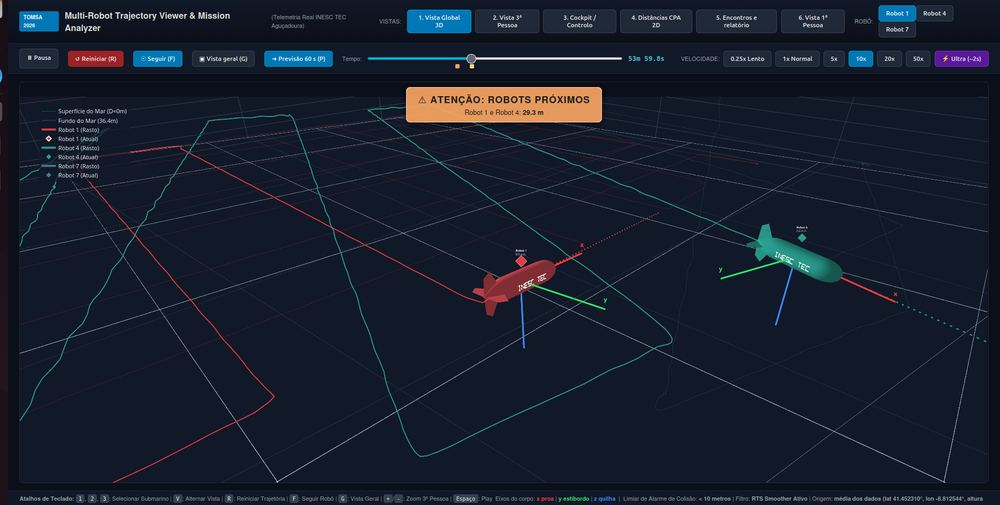

*Dashboard em execução aos 53 min 59,8 s: o Robot 1 e o Robot 4 a 29,3 m, por isso a faixa amarela "ATENÇÃO: ROBOTS PRÓXIMOS". Os rastos são as posições suavizadas.*

### Vista 3.ª Pessoa
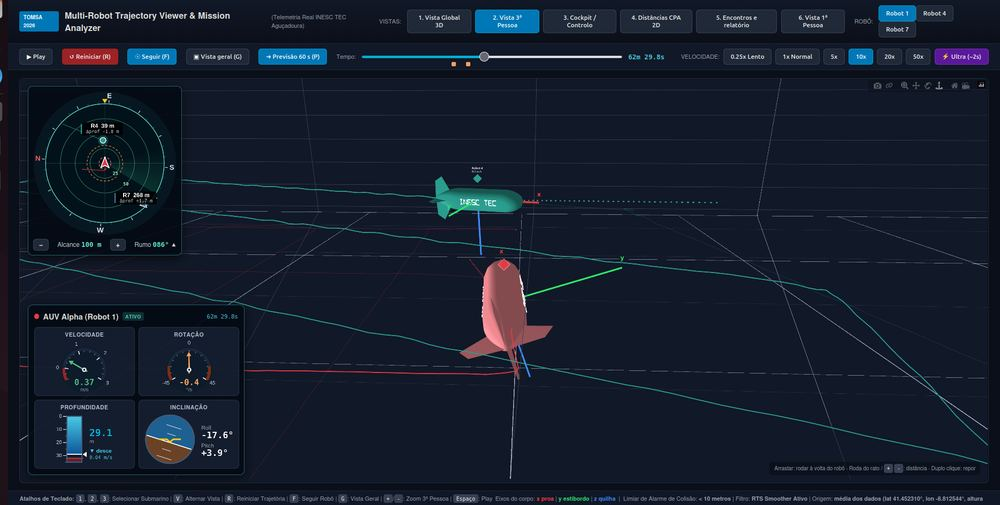

*Aos 62 min 29,8 s, com o Robot 1 ativo: o radar (canto superior esquerdo) mostra o Robot 4 a 39 m e o Robot 7 a 268 m. A 39 m não há faixa de aviso (limiar de 30 m).*

### Cockpit
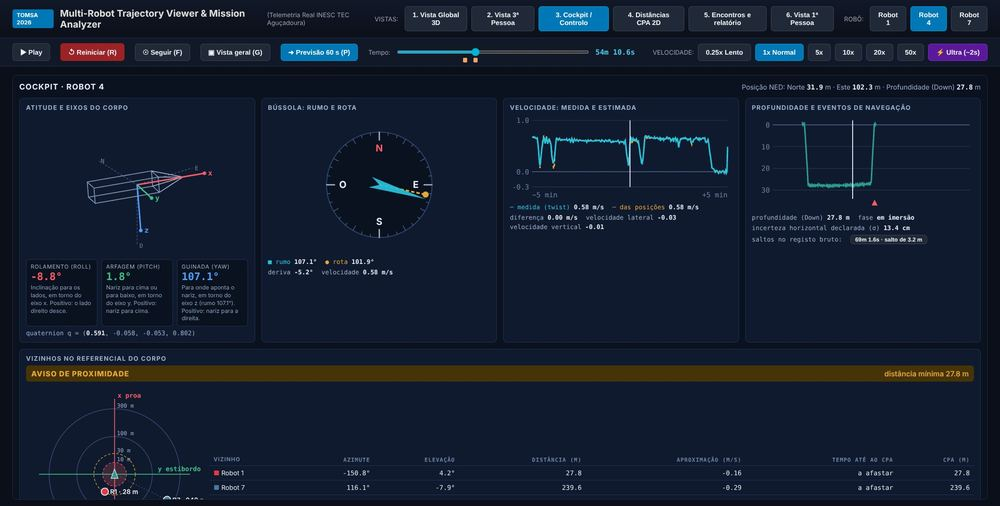

*Cockpit do Robot 4 aos 54 min 10,6 s: atitude (roll, pitch, yaw e eixos do corpo), bússola com rumo e rota, velocidade medida e estimada, profundidade, e a tabela de **vizinhos** na parte inferior.*

### Distâncias CPA 2D
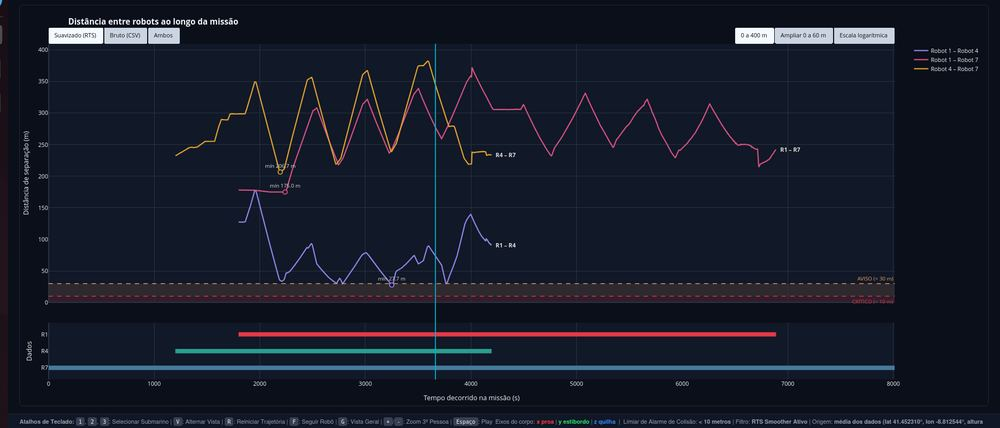

*Distância 3D entre cada par de robôs; as faixas marcam os limiares de aviso e de perigo.*

### Encontros e relatório
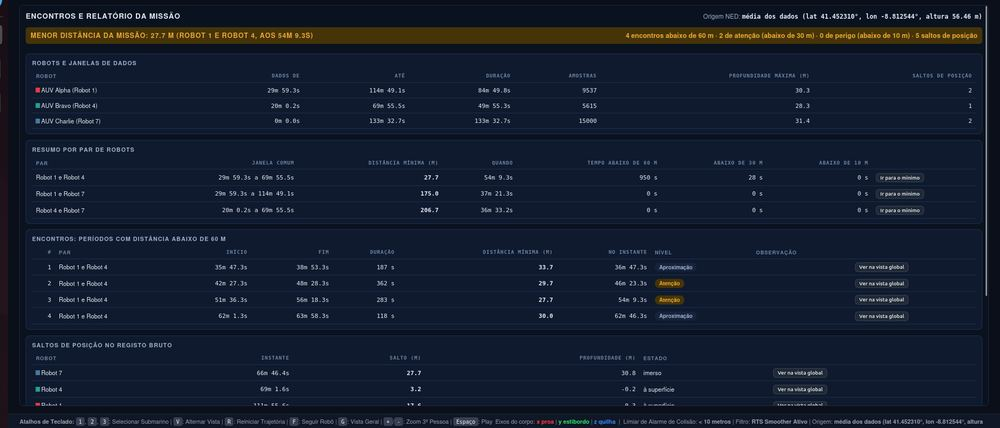

*Relatório da missão: menor distância 27,7 m (Robot 1 e Robot 4, aos 54 min 9,3 s), 4 encontros abaixo de 60 m, 2 de atenção, 0 de perigo e 5 saltos de posição.*

### Vista 1.ª Pessoa
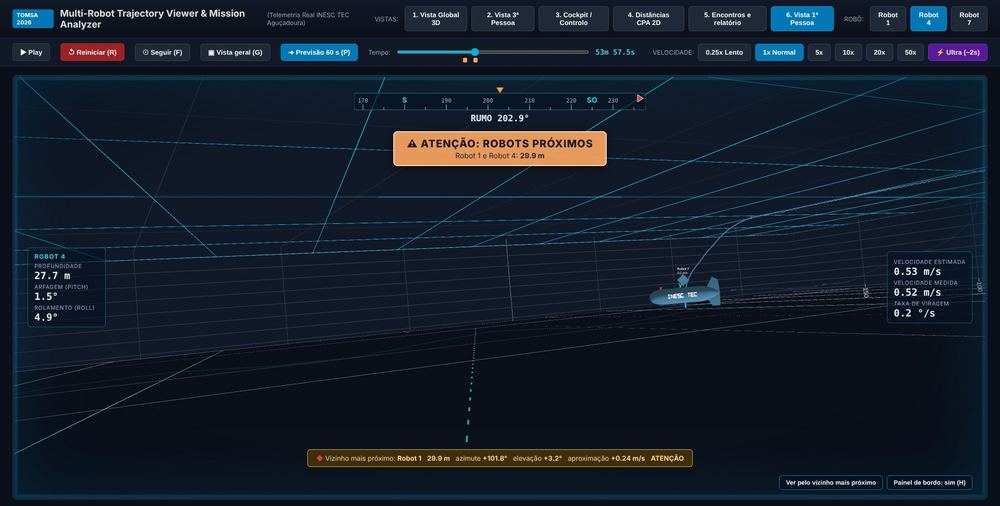

*Robot 4 aos 53 min 57,5 s: fita de rumo (202,9°), profundidade, pitch, roll, velocidades, taxa de viragem e o vizinho mais próximo (Robot 1, a 29,9 m).*

## 11.3 Verificação 1: o relatório que o dashboard mostra
O número de encontros, níveis e saltos da captura anterior vêm de `compute_mission_report`. Confirma-se com o objeto `rep` (Capítulo 4) e com o cálculo independente da secção 9.6:

In [70]:
p = next(q for q in rep["pairs"] if (q["a"], q["b"]) == ("Robot 1", "Robot 4"))
niveis = pd.Series([e["level"] for e in p["episodes"]]).value_counts()
print(f"Menor distância da missão: {min(q['d_min'] for q in rep['pairs'] if q['d_min'] is not None):.1f} m  (Robot 1 e Robot 4, aos {tmiss(T0 + p['t_min'])})")
print("Encontros (abaixo de 60 m):", len(p["episodes"]), "  níveis:", niveis.to_dict(), "  saltos de posição:", len(rep["jumps"]))
for e in p["episodes"]:
    print(f"  de {tmiss(T0 + e['t0'])} a {tmiss(T0 + e['t1'])}: mínimo {e['d_min']:.1f} m aos {tmiss(T0 + e['t_min'])}  ({e['level']})")

# Instantes das capturas 'terceira' (62 min 29,8 s)
t_cap = T0 + 62 * 60 + 29.8
st = ds.get_state_at_time(t_cap)
d = {(a, b): np.linalg.norm(st[b]["pos_ned"] - st[a]["pos_ned"]) for a, b in (("Robot 1", "Robot 4"), ("Robot 1", "Robot 7"))}
print(f"\nAos 62 min 29,8 s: Robot 1 - Robot 4 = {d[('Robot 1', 'Robot 4')]:.1f} m;  Robot 1 - Robot 7 = {d[('Robot 1', 'Robot 7')]:.1f} m   (a captura mostra R4 a 39 m e R7 a 268 m)")

Menor distância da missão: 27.7 m  (Robot 1 e Robot 4, aos 54m 9.3s)
Encontros (abaixo de 60 m): 4   níveis: {'aproximacao': 2, 'atencao': 2}   saltos de posição: 5
  de 35m 47.3s a 38m 53.3s: mínimo 33.7 m aos 36m 47.3s  (aproximacao)
  de 42m 27.3s a 48m 28.3s: mínimo 29.7 m aos 46m 23.3s  (atencao)
  de 51m 36.3s a 56m 18.3s: mínimo 27.7 m aos 54m 9.3s  (atencao)
  de 62m 1.3s a 63m 58.3s: mínimo 30.0 m aos 62m 46.3s  (aproximacao)

Aos 62 min 29,8 s: Robot 1 - Robot 4 = 38.8 m;  Robot 1 - Robot 7 = 268.1 m   (a captura mostra R4 a 39 m e R7 a 268 m)


**Interpretação.** Os números da captura (27,7 m aos 54 min 9,3 s; 4 encontros; 2 de atenção; 5 saltos; R4 a 39 m e R7 a 268 m) coincidem com o cálculo independente. A faixa não aparece aos 62 min 29,8 s porque 39 m está acima de 30 m.

## 11.4 Verificação 2: o navegador interpola como o Python?
O navegador não tem os 9 537 pontos do Robot 1: só a grelha de 2 s, interpolada linearmente (`valueAt`). O Python (`get_state_at_time`) interpola a partir dos pontos originais, e usa SLERP para a atitude. Mede-se a diferença nos mesmos instantes:

In [71]:
mostrar_js("valueAt")
rng = np.random.default_rng(7)
instantes = rng.uniform(ds.common_start, ds.common_end, 300)
def val_js(arr, f):
    i = int(np.floor(f))
    if i >= len(arr) - 1:
        return arr[-1]
    w = f - i
    return arr[i] * (1 - w) + arr[i + 1] * w            # réplica de valueAt

dif = {"posição (m)": [], "yaw (graus)": [], "pitch (graus)": [], "roll (graus)": [], "velocidade longitudinal (m por s)": []}
for t in instantes:
    f = (t - TL["t0_base"]) / TL["dt_step"]
    stp = ds.get_state_at_time(t)
    for r in IDS:
        s = TL["robots"][r]; q = stp[r]
        dif["posição (m)"].append(np.linalg.norm([val_js(s[k], f) - q["pos_ned"][i] for i, k in enumerate(("N", "E", "D"))]))
        dyaw = (val_js(s["yaw"], f) - q["euler_deg"][2] + 180) % 360 - 180
        dif["yaw (graus)"].append(abs(dyaw))
        dif["pitch (graus)"].append(abs(val_js(s["pitch"], f) - q["euler_deg"][1]))
        dif["roll (graus)"].append(abs(val_js(s["roll"], f) - q["euler_deg"][0]))
        dif["velocidade longitudinal (m por s)"].append(abs(val_js(s["spd"], f) - q["speed_longitudinal"]))
tab = pd.DataFrame({k: {"mediana": np.median(v), "percentil 95": np.percentile(v, 95), "máximo": np.max(v)} for k, v in dif.items()}).T
display(tab.round(3))

# multi_robot_system/visualization/web_server.py, linhas 595 a 602
 595          // Método: interpolação linear entre as duas amostras vizinhas (peso w = parte fracionária de f).
 596          // Obtemos: o valor de qualquer série (E, N, D, yaw, velocidade...) num instante entre amostras.
 597          function valueAt(arr, f) {
 598              const i = Math.floor(f);
 599              if (i >= arr.length - 1) return arr[arr.length - 1];
 600              const w = f - i;
 601              return arr[i] * (1 - w) + arr[i + 1] * w;
 602          }


,mediana,percentil 95,máximo
posição (m),0.007,0.035,0.256
yaw (graus),0.036,0.481,3.072
pitch (graus),0.082,0.892,5.497
roll (graus),0.043,0.649,4.358
velocidade longitudinal (m por s),0.003,0.019,0.343


**Explicação.** Para cada um de 300 instantes aleatórios da janela comum, calculam-se os estados dos três robôs pelos dois caminhos e compara-se a norma da diferença de posição e o módulo da diferença dos ângulos (o yaw com reposição em $[-180^\circ,180^\circ]$). A réplica de `valueAt` é a fórmula $a_i(1-w)+a_{i+1}w$.

**Interpretação.** Na posição, a diferença mediana é de menos de 1 cm, o percentil 95 é de 3,5 cm e o máximo é de 26 cm. Nos ângulos, a mediana é inferior a 0,1° e o percentil 95 inferior a 1°, mas o máximo chega a 3,1° (yaw), 5,5° (pitch) e 4,4° (roll). Ou seja, **no caso típico** a interpolação linear numa grelha de 2 s e o arredondamento ao centímetro chegam para desenhar, mas **nos piores instantes** o navegador mostra uma atitude com alguns graus de diferença (o ângulo pode variar entre pontos da grelha mais depressa do que a interpolação linear acompanha; não foi investigada a causa exata). É o **custo** de descer de milhares de pontos para uma grelha de 2 s. Nenhuma conclusão dos capítulos anteriores depende disso (a secção 9.5 já mostrou que a distância mínima só muda de 5 cm).

## 11.5 Verificação 3: a tabela de vizinhos do Cockpit

Reproduz-se, em Python, a lógica de `neighboursPanel` (azimute, elevação, distância, aproximação, TCPA e CPA), com os mesmos estados da grelha de 2 s e a mesma ordem de operações do JavaScript. Compara-se com a captura do Cockpit do Robot 4 aos 54 min 10,6 s (secção 11.2).

In [72]:
from multi_robot_system.core.math import rotations as ROT

def vizinhos_js(me, t_abs):
    """Réplica de neighboursPanel: tudo calculado a partir da grelha de 2 s do timeline (como no navegador)."""
    f = (t_abs - TL["t0_base"]) / TL["dt_step"]
    S = lambda r, k: val_js(TL["robots"][r][k], f)
    ang = np.radians([S(me, "roll"), S(me, "pitch"), S(me, "yaw")])
    Rwb = ROT.euler_zyx_to_rotation_matrix(*ang)
    linhas = []
    for o in sorted(TL["robots"]):
        if o == me:
            continue
        d = np.array([S(o, "N") - S(me, "N"), S(o, "E") - S(me, "E"), S(o, "D") - S(me, "D")])
        b = Rwb.T @ d
        hor = np.hypot(b[0], b[1]); rng_ = np.linalg.norm(b)
        az, el = np.degrees(np.arctan2(b[1], b[0])), np.degrees(np.arctan2(-b[2], hor))
        rv = np.array([S(o, "vN") - S(me, "vN"), S(o, "vE") - S(me, "vE"), S(o, "vD") - S(me, "vD")])
        vv, dot = rv @ rv, d @ rv
        clos = -dot / max(rng_, 1e-6)
        cpa = rng_
        if vv < 1e-8:
            tc_txt = "estável"
        elif -dot / vv <= 0:
            tc_txt = "a afastar"
        else:
            tc = -dot / vv; th = min(tc, 60.0)
            cpa = np.linalg.norm(d + rv * th)
            tc_txt = "> 60 s" if tc > 60 else f"{tc:.0f} s"
        linhas.append({"Vizinho": o, "Azimute (°)": az, "Elevação (°)": el, "Distância (m)": rng_, "Aproximação (m por s)": clos, "Tempo até ao CPA": tc_txt, "CPA (m)": cpa})
    return pd.DataFrame(linhas).set_index("Vizinho")

t_ck = T0 + 54 * 60 + 10.6
display(vizinhos_js("Robot 4", t_ck).round(2))
print("Captura (Cockpit do Robot 4 aos 54 min 10,6 s):  Robot 1: azimute -150,8°, elevação 4,2°, distância 27,8 m, aproximação -0,16 m por s, a afastar, CPA 27,8 m")
print("                                                 Robot 7: azimute 116,1°, elevação -7,9°, distância 239,6 m, aproximação -0,29 m por s, a afastar")

,Azimute (°),Elevação (°),Distância (m),Aproximação (m por s),Tempo até ao CPA,CPA (m)
Vizinho,,,,,,
Robot 1,-150.79,4.16,27.85,-0.16,a afastar,27.85
Robot 7,116.06,-7.90,239.56,-0.29,a afastar,239.56


Captura (Cockpit do Robot 4 aos 54 min 10,6 s):  Robot 1: azimute -150,8°, elevação 4,2°, distância 27,8 m, aproximação -0,16 m por s, a afastar, CPA 27,8 m
                                                 Robot 7: azimute 116,1°, elevação -7,9°, distância 239,6 m, aproximação -0,29 m por s, a afastar


**Interpretação.** A réplica reproduz os valores que o dashboard mostra: azimutes e elevações, distâncias, sinal da aproximação (negativa = a afastar-se) e o texto "a afastar" (porque $t^{*}\le0$). Verifica-se assim, de ponta a ponta, que a matemática dos capítulos 4, 5 e 10 é a que aparece no ecrã.

## 11.6 Execução, exportações e limitações

In [73]:
env = {k: v for k, v in os.environ.items() if k != "MPLBACKEND"}
env["PYTHONPATH"] = "."
r = subprocess.run([sys.executable, "multi_robot_system/main.py", "--help"], capture_output=True, text=True, env=env)
print(r.stdout[:2500])

usage: main.py [-h] [--config CONFIG]
               [--dados CSV_OU_PASTA [CSV_OU_PASTA ...]] [--web] [--export]
               [--benchmark] [--bundle] [--test] [--all]

TOMSA 2026 - Multi-Robot Subsea Trajectory System (INESC TEC Aguçadoura)

options:
  -h, --help            show this help message and exit
  --config CONFIG       Caminho para o ficheiro de configuração YAML
  --dados CSV_OU_PASTA [CSV_OU_PASTA ...]
                        Ficheiros CSV (ou uma pasta com CSV) a usar no lugar
                        dos da configuração. Ex.: --dados novos/robot1.csv
                        novos/robot4.csv
  --web                 Inicia o servidor e abre o Dashboard no browser
                        (Plotly)
  --export              Exporta ficheiros GeoJSON (QGIS), KML 3D (Google
                        Earth) e CSV sincronizado
  --benchmark           Executa o benchmark de comparação dos interpoladores
                        (Linear vs Spline vs RTS)
  --bundle              Gera o

**Resumo dos modos** (testados no README, secção 10): `--web` serve o dashboard; `--export` grava GeoJSON, KML 3D e CSV sincronizado; `--benchmark` compara Linear, Spline e Kalman+RTS (secção 8.7); `--bundle` grava uma página HTML autónoma; `--test` corre o `pytest`.

**Limitações da visualização**

- **Precisa de Internet** na primeira abertura, porque o `plotly.js` vem de uma CDN. Não foi testado o arranque sem Internet.
- O código JavaScript (mais de 1 500 linhas dentro de `web_server.py`, em texto) **não tem testes automáticos de interface**. A verificação foi feita por réplicas em Python (este capítulo e o 10) e por testes que confirmam que as funções existem na página (`test_colisao`). A aparência foi validada visualmente num navegador de teste (Chromium), não em Firefox, Safari nem Edge.
- A malha 3D do casco é **ilustrativa**: não corresponde à geometria real dos veículos, e não entra em nenhum cálculo de distância.
- Os rastos mostram posições **estimadas** (suavizadas), não as medições originais; ambas estão no programa (`pos_ned` e `pos_ned_raw`).

<a id="cap12"></a><a id="evidencias"></a>
# CAPÍTULO 12 — TESTES E VALIDAÇÃO

*Este capítulo e o seguinte constituem a secção "Resultados / Evidências" do modelo da unidade curricular.*

## 12.1 Estratégia

Há quatro níveis de verificação, do mais forte ao mais fraco:

1. **Testes automáticos do projeto** (`pytest`): correm sempre que se altera o código.
2. **Comparação com bibliotecas independentes** (`pymap3d`, `scipy`): a matemática do projeto contra implementações de referência.
3. **Réplicas neste relatório**: o que está em JavaScript foi reescrito em Python e comparado com a saída real.
4. **Inspeção visual** do dashboard em execução (capturas do Capítulo 11).

O que **não** foi testado vem listado na secção 12.6.

## 12.2 Testes automáticos do projeto

Corre-se aqui a suite real (`multi_robot_system/tests`), em modo apenas leitura (sem criar ficheiros de cache):

In [74]:
import re
env = {k: v for k, v in os.environ.items() if k != "MPLBACKEND"}      # o MPLBACKEND do Jupyter não existe fora do notebook
env["PYTHONPATH"] = "."
t0 = __import__("time").time()
r = subprocess.run([sys.executable, "-m", "pytest", "multi_robot_system/tests", "-v", "-p", "no:cacheprovider", "--tb=short", "-W", "ignore", "--color=no"],
                   capture_output=True, text=True, env=env)
duracao = __import__("time").time() - t0
partes = [re.match(r"(\S+)::(\S+)\s+(PASSED|FAILED|ERROR)", l) for l in r.stdout.splitlines()]
res = pd.DataFrame([{"ficheiro": m.group(1).split("/")[-1], "teste": m.group(2), "estado": m.group(3)} for m in partes if m])
print((r.stdout.strip().splitlines() or ["(sem saída)"])[-1], "" if res.shape[0] else r.stderr[-600:])
print(f"(executado em {duracao:.0f} s com {sys.version.split()[0]})\n")
display(res.groupby("ficheiro")["estado"].value_counts().unstack(fill_value=0))

============================== 32 passed in 4.46s ============================== 
(executado em 5 s com 3.13.16)



estado,PASSED
ficheiro,
test_colisao.py,1
test_cpa.py,3
test_csv_novo.py,3
test_geodesy.py,17
test_kalman_rts.py,1
test_lettering.py,2
test_mission_report.py,2
test_rotations.py,3


### O que cada ficheiro de testes valida

| Ficheiro | O que testa | Capítulo |
|---|---|---|
| `test_geodesy.py` | WGS-84 para ECEF e NED contra `pymap3d`; ida e volta ECEF e geodésicas; origem dá zero; direções cardeais | 4 |
| `test_rotations.py` | ortonormalidade da matriz, ida e volta Euler e quaternião, extremos do SLERP | 5, 6 |
| `test_kalman_rts.py` | o RTS reduz o ruído de uma trajetória sintética em mais de 40% | 8 |
| `test_cpa.py` | CPA e TCPA em três casos de solução conhecida (frente a frente, perpendicular, a afastar-se) | 10 |
| `test_mission_report.py` | encontro único, janela comum vazia, saltos | 9, 10 |
| `test_colisao.py` | o limiar de contacto chega ao painel e a função de deteção existe na página | 10, 11 |
| `test_csv_novo.py` | CSV com instantes repetidos e linhas em falta; CSV sem covariância nem `twist`; nomes dos robôs a partir dos ficheiros | 3 |
| `test_lettering.py` | geometria do texto sobre o casco do veículo (visual) | 11 |

**Limite desta evidência.** Os testes automáticos verificam casos **limpos ou sintéticos** e a *existência* de funções em JavaScript; **não** executam o JavaScript. Por isso as secções 11.3 a 11.5 e 10.6 existem.

## 12.3 Comparação com bibliotecas independentes, em todas as amostras

Os testes automáticos usam alguns pontos. Aqui compara-se com **todas as amostras reais** dos três robôs (30 152 pontos no total):

In [75]:
import pymap3d as pm
from scipy.spatial.transform import Rotation as SR

linhas = []
for r_ in IDS:
    t = ds.trajectories[r_]
    ned_ref = np.array(pm.geodetic2ned(t.lat, t.lon, t.alt, lat0, lon0, h0))
    e_ned = np.abs(ned_ref - t.pos_ned_raw).max()

    Rm = t.rot_matrices
    e_orto = np.abs(np.einsum("nji,njk->nik", Rm, Rm) - np.eye(3)).max()
    e_det = np.abs(np.linalg.det(Rm) - 1).max()

    sc = SR.from_quat(t.quaternions)                                   # [x, y, z, w], igual ao CSV
    e_mat = np.abs(sc.as_matrix() - Rm).max()
    eul_sc = sc.as_euler("xyz", degrees=True)
    de = (eul_sc - t.euler_deg + 180) % 360 - 180
    linhas.append({"Robô": r_, "amostras": len(t.timestamps), "NED: máx |projeto - pymap3d| (m)": e_ned,
                   "R: máx |RᵀR - I|": e_orto, "R: máx |det R - 1|": e_det, "R: máx |projeto - scipy|": e_mat, "Euler: máx |projeto - scipy| (graus)": np.abs(de).max()})
tab_v = pd.DataFrame(linhas).set_index("Robô")
display(tab_v.apply(lambda c: c.map(lambda v: f"{v:.2e}" if isinstance(v, float) else v)))

,amostras,NED: máx |projeto - pymap3d| (m),R: máx |RᵀR - I|,R: máx |det R - 1|,R: máx |projeto - scipy|,Euler: máx |projeto - scipy| (graus)
Robô,,,,,,
Robot 1,9537,3.26e-09,1.33e-15,1.55e-15,4.44e-16,5.68e-14
Robot 4,5615,2.65e-09,1.33e-15,1.33e-15,4.44e-16,8.53e-14
Robot 7,15000,2.65e-09,1.55e-15,1.55e-15,4.44e-16,8.53e-14


**Interpretação.** Em **todas** as amostras, o NED do projeto coincide com o da biblioteca `pymap3d` (diferença máxima de 3,3 nanómetros, isto é, erro de arredondamento), as matrizes são rotações próprias (ortonormais, determinante $+1$) até ao arredondamento, e coincidem com as do SciPy, tal como os ângulos de Euler. Isto sustenta os Capítulos 4 a 6 com uma implementação independente.

## 12.4 O programa não altera os dados originais

O projeto declara que os CSV originais ficam inalterados (`odom_loader.py`). Verifica-se com uma soma de controlo (SHA-256) antes e depois de carregar a missão de novo:

In [76]:
import hashlib, contextlib, io
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()[:16]
fich = sorted(Path("multi_robot_system/data").glob("robot*_s1.csv"))
antes = {f.name: sha(f) for f in fich}
with contextlib.redirect_stdout(io.StringIO()):
    load_mission("multi_robot_system/config/mission_config.yaml")
depois = {f.name: sha(f) for f in fich}
display(pd.DataFrame({"antes": antes, "depois": depois, "igual": {k: antes[k] == depois[k] for k in antes}}))

,antes,depois,igual
robot1_s1.csv,1bfd9e9d9830b9b5,1bfd9e9d9830b9b5,True
robot4_s1.csv,8ab18f7b06e09cd3,8ab18f7b06e09cd3,True
robot7_s1.csv,87c5f225c27d7fe7,87c5f225c27d7fe7,True


## 12.5 Colisão: deteção testada com dados sintéticos

Os dados reais **não contêm** nenhum contacto (secção 10.7), por isso a deteção de colisão não é exercitada por eles. Para a testar reproduz-se `detectCollision` em Python (mesma lógica: grelha de 2 s, limiar de contacto de 2 m, primeiro passo do par) sobre cenários **inventados**, com valores calculáveis à mão:

In [77]:
def detectar_colisao(robots, dt=2.0, lim=2.0):
    """Réplica de detectCollision (web_server.py): robots = {id: array (n, 3) em NED}; todos ativos em todos os passos."""
    ids = sorted(robots); n = len(next(iter(robots.values())))
    melhor = None
    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            for k in range(n):
                d = np.linalg.norm(robots[ids[i]][k] - robots[ids[j]][k])
                if d < lim:
                    if melhor is None or k < melhor["k"]:
                        melhor = {"k": k, "t_s": k * dt, "par": (ids[i], ids[j]), "d_m": round(float(d), 2)}
                    break
    return melhor

t_fino = np.arange(0, 120.01, 0.1)                     # tempo "verdadeiro", passo de 0,1 s
def cenario(gap, desvio_lateral, v=1.0):
    """A avança para Sul e B para Norte a v m por s, com o afastamento inicial 'gap' (m) e um desvio lateral (m)."""
    A = np.stack([gap / 2 - v * t_fino, np.zeros_like(t_fino), np.full_like(t_fino, 20.0)], axis=1)
    B = np.stack([-gap / 2 + v * t_fino, np.full_like(t_fino, desvio_lateral), np.full_like(t_fino, 20.0)], axis=1)
    return {"A": A, "B": B}

teste = [
    ("Frente a frente, folga de 120 m (encontram-se aos 60 s)", cenario(120, 0.0)),
    ("Passam a 5 m um do outro (desvio lateral de 5 m)", cenario(120, 5.0)),
    ("Frente a frente, folga de 122 m (cruzam-se aos 61 s)", cenario(122, 0.0)),
]
linhas = []
for nome, rb in teste:
    d_fina = np.linalg.norm(rb["A"] - rb["B"], axis=1)
    rb_2s = {k: v[::20] for k, v in rb.items()}             # o que o navegador vê: um passo de 2 s em cada 20 de 0,1 s
    linhas.append({"Cenário": nome, "menor distância verdadeira (m)": d_fina.min(), "deteção do projeto (grelha de 2 s)": detectar_colisao(rb_2s)})
display(pd.DataFrame(linhas).set_index("Cenário"))

,menor distância verdadeira (m),deteção do projeto (grelha de 2 s)
Cenário,,
"Frente a frente, folga de 120 m (encontram-se aos 60 s)",0.0,"{'k': 30, 't_s': 60.0, 'par': ('A', 'B'), 'd_m..."
Passam a 5 m um do outro (desvio lateral de 5 m),5.0,None
"Frente a frente, folga de 122 m (cruzam-se aos 61 s)",0.0,None


**Interpretação.**

1. **Frente a frente, 120 m**: os robôs aproximam-se a 2 m por segundo e a grelha de 2 s cai exatamente no instante do encontro: a deteção dispara no passo $k=30$ (60 s) com $d=0$ m. ✔
2. **Passam a 5 m**: a distância nunca desce de 5 m, **não há colisão**, só poderia haver o aviso amarelo e o vermelho (limiares de 30 m e 10 m). ✔
3. **Folga de 122 m**: os robôs **cruzam-se** aos 61 s (distância zero), mas a grelha de 2 s amostra os instantes 60 s e 62 s, com distância de 2 m (não inferior a 2 m, a condição é estrita). **A deteção não dispara.** ✘

O terceiro caso é uma **limitação real** do código atual: a deteção de contacto olha só para os instantes da grelha de 2 s, e dois robôs que se aproximem depressa podem "atravessar-se" entre dois passos sem que nenhum deles fique abaixo do limiar. Com as velocidades destes veículos (menos de 1 m por segundo, aproximação relativa no máximo de 2 m por segundo) o risco existe mas é pequeno; uma correção simples seria usar o **mínimo da distância no segmento** entre passos, ou uma grelha mais fina. **Não alterámos o código** (decisão de manter o que foi entregue); fica registado como trabalho futuro (Capítulo 14).

A captura abaixo é a do dashboard com um cenário **simulado** (dados inventados): mostra a faixa "COLISÃO" e os dois robôs parados.

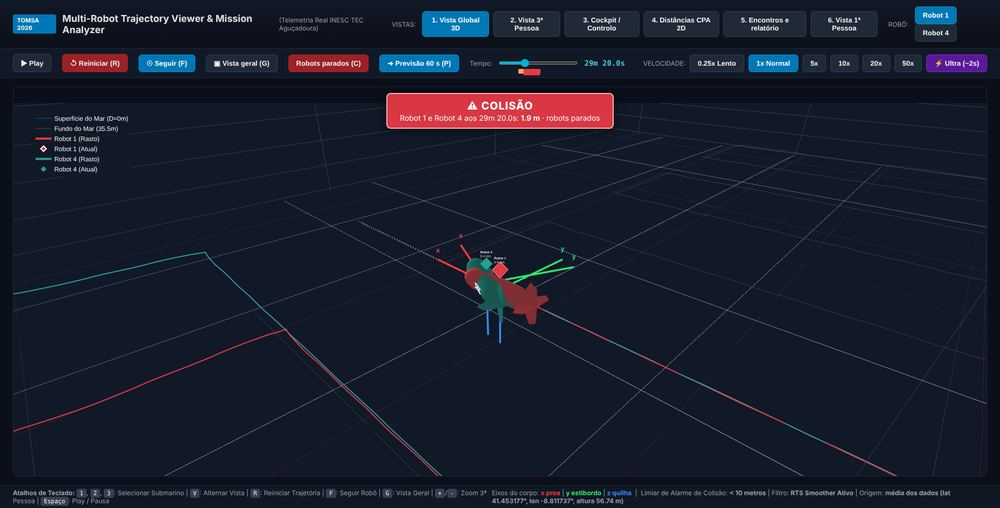

*Colisão **simulada**, com dados inventados (não são dados reais): Robot 1 e Robot 4 a 1,9 m; o Play pára e os dois robôs ficam parados.*

## 12.6 O que não foi testado

| Item | Razão |
|---|---|
| Código JavaScript em execução automática (sem navegador) | Não há testes de interface; a verificação é por réplicas e por inspeção visual. |
| Firefox, Safari, Edge, Windows, macOS | Sem acesso durante o desenvolvimento. |
| Arranque sem Internet | O `plotly.js` vem de uma CDN (confirmado só pela leitura do código). |
| Instalação em Ubuntu 22.04 e Python 3.10 ou anterior | Só se testou Ubuntu 24.04 e Python 3.11 a 3.13. |
| Alerta de perigo (abaixo de 10 m) e colisão com **dados reais** | Os dados não têm nenhum encontro abaixo de 27,7 m. |
| Qualidade do CPA como previsão de **colisão** | Sem eventos de perigo; só se mediu o erro de previsão da distância (secção 10.6). |
| `main.py` da raiz (código legado da Entrega 1) | **Não arranca** neste estado (`NameError: Optional` em `src/logger.py`); não foi alterado. |

<a id="cap13"></a>
# CAPÍTULO 13 — RESULTADOS E DISCUSSÃO

## 13.1 Resultados principais (calculados a partir dos dados)

In [78]:
quadro = []
for r_ in IDS:
    t = ds.trajectories[r_]
    quadro.append({"Robô": r_, "amostras": len(t.timestamps), "início": tmiss(t.timestamps[0]), "fim": tmiss(t.timestamps[-1]),
                   "duração (min)": t.duration_s / 60, "caminho horizontal (m)": t.total_distance_m, "velocidade média do caminho (m por s)": t.total_distance_m / t.duration_s,
                   "profundidade máx. (m)": t.max_depth_m, "saltos de posição": len(t.jump_events)})
display(pd.DataFrame(quadro).set_index("Robô").round(2))
display(tab_d.round(2).T)
print("Janela comum aos 3 robôs: %.1f s (%.1f min)" % (ds.common_end - ds.common_start, (ds.common_end - ds.common_start) / 60))

,amostras,início,fim,duração (min),caminho horizontal (m),velocidade média do caminho (m por s),profundidade máx. (m),saltos de posição
Robô,,,,,,,,
Robot 1,9537,29m 59.3s,114m 49.1s,84.83,2022.15,0.40,30.27,2
Robot 4,5615,20m 0.2s,69m 55.5s,49.92,1324.37,0.44,28.26,1
Robot 7,15000,0m 0.0s,133m 32.7s,133.54,962.26,0.12,31.40,2


Par,Robot 1 - Robot 4,Robot 1 - Robot 7,Robot 4 - Robot 7
Janela comum,29m 59.3s a 69m 55.5s,29m 59.3s a 114m 49.1s,20m 0.2s a 69m 55.5s
"d mínima (relatório, 1 s)",27.68,174.95,206.69
em,54m 9.3s,37m 21.3s,36m 33.2s
"d mínima (dashboard, 2 s)",27.73,174.99,206.69
diferença (m),0.05,0.03,-0.0
tempo < 60 m (s),950.0,0.0,0.0
< 30 m (s),28.0,0.0,0.0
< 10 m (s),0.0,0.0,0.0


Janela comum aos 3 robôs: 2396.3 s (39.9 min)


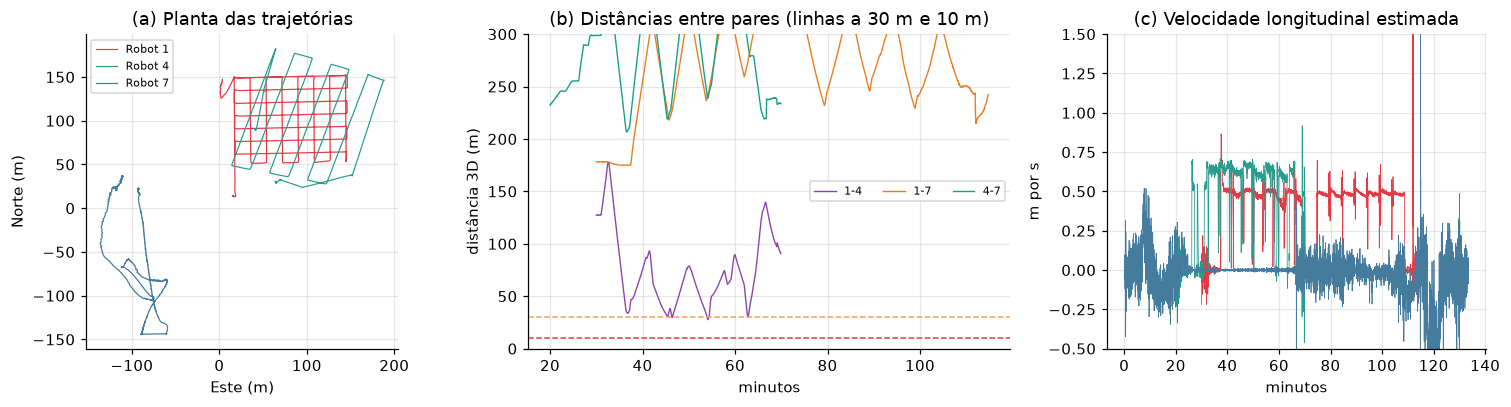

In [79]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.1, 1.4, 1.1]})
ax = axs[0]
for r_ in IDS:
    p = ds.trajectories[r_].pos_ned
    ax.plot(p[1], p[0], color=COR[r_], lw=0.8, label=r_)
ax.set_aspect("equal"); ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)"); ax.set_title("(a) Planta das trajetórias"); ax.legend(fontsize=7)
ax = axs[1]
for a_, b_ in PARES:
    ax.plot(K_ * TL["dt_step"] / 60, dist_2s(a_, b_), lw=0.9, label=f"{a_[-1]}-{b_[-1]}", color=cores[(a_, b_)])
ax.axhline(30, color="#f4a261", ls="--", lw=1); ax.axhline(10, color="#e63946", ls="--", lw=1)
ax.set_ylim(0, 300); ax.set_xlabel("minutos"); ax.set_ylabel("distância 3D (m)"); ax.set_title("(b) Distâncias entre pares (linhas a 30 m e 10 m)"); ax.legend(fontsize=7, ncol=3)
ax = axs[2]
for r_ in IDS:
    t = ds.trajectories[r_]
    ax.plot((t.timestamps - T0) / 60, t.speed_longitudinal, lw=0.5, color=COR[r_], label=r_)
ax.set_xlabel("minutos"); ax.set_ylabel("m por s"); ax.set_title("(c) Velocidade longitudinal estimada"); ax.set_ylim(-0.5, 1.5)
plt.tight_layout(); plt.show()

## 13.2 Discussão

**O que os resultados mostram**

1. **Os dados são consistentes.** As três trajetórias convertem-se para NED de forma idêntica à biblioteca de referência (12.3); as matrizes de rotação são próprias; a velocidade estimada pelo filtro concorda com a velocidade medida pelos robôs 1 e 4 (7.4).
2. **Nenhum par de robôs chegou perto do limiar de perigo.** A menor distância é de 27,7 m (Robot 1 e Robot 4, aos 54 min 9,3 s), a 17,7 m do limiar de 10 m; o Robot 7 nunca esteve a menos de 170 m dos outros. Em 4 encontros abaixo de 60 m (todos entre o Robot 1 e o Robot 4), dois chegaram a nível de atenção (abaixo de 30 m) e nenhum a perigo ou colisão (10.7).
3. **O filtro de Kalman altera pouco a posição** (menos de 3 cm em média) **mas melhora muito a velocidade** (ruído 2 a 7 vezes menor). Não melhora a *interpolação* em relação a uma spline (8.7).
4. **A previsão de aproximação (CPA) é um indicador, não uma garantia.** É boa a poucos segundos do CPA e piora com o horizonte; em linha reta pode subestimar a distância e gerar falsos alarmes (10.6).
5. **O dashboard apresenta o que o código calcula**: as capturas coincidem com as réplicas independentes (11.3 a 11.5).

**O que os resultados não permitem dizer**

- Que o sistema **evita colisões**. Não evita: só deteta e avisa (10.1).
- Que o alerta de perigo **funciona com eventos reais**. Não houve nenhum evento (12.6).
- Que o Kalman é "melhor" do que a interpolação linear ou a spline para reconstruir a trajetória: a comparação depende de qual é a "verdade" usada (8.7).
- Que o robô 7 foi bem seguido: a velocidade estimada concorda mal com a medida (correlação de 0,30) e tem desvios de até 22,8 m entre a posição bruta e a suavizada, junto de um salto de posição (8.5). O dashboard assinala os saltos mas não os corrige.
- Que a incerteza das posições seja conhecida: usa-se a incerteza declarada no CSV, não validada de forma independente (Capítulo 3).

**Aproximações assumidas, por capítulo**

| Capítulo | Aproximação |
|---|---|
| 4 | plano tangente local (NED) em vez do elipsoide; erro de milímetros neste alcance |
| 7 | velocidade constante entre amostras; posição interpolada linearmente |
| 8 | modelo de velocidade constante; ruído de processo fixo; só a posição é medida; processamento offline |
| 9 | distância entre pontos de referência (sem dimensões do veículo, sem incerteza) |
| 10 | CPA em linha reta, horizonte de 60 s; contacto avaliado numa grelha de 2 s |
| 11 | grelha de 2 s e arredondamento ao centímetro no navegador |

## 13.3 Mapa entre funcionalidades, código e matemática

Cada linha da tabela é **verificada automaticamente** nesta célula: o ficheiro existe e a função está lá (em Python, por importação; em JavaScript, por procura no texto de `web_server.py`).

In [80]:
import importlib
MAPA = [
    ("Leitura e limpeza dos CSV", "core/data/odom_loader.py", "load_single_robot_csv", "ordenação, remoção de duplicados, validação de colunas", 3),
    ("Incerteza declarada", "core/data/odom_loader.py", "parse_covariance_diagonal", "diagonal da covariância 6x6; σ = raiz da variância", 3),
    ("Saltos de posição", "core/data/odom_loader.py", "detect_position_jumps", "velocidade implícita acima de 2,5 m por segundo", 3),
    ("Origem NED", "core/data/odom_loader.py", "compute_reference_origin", "média de latitude e longitude; mediana das alturas", 4),
    ("WGS-84 para ECEF", "core/math/geodesy.py", "geodetic_to_ecef", "raio de curvatura do primeiro vertical", 4),
    ("ECEF para NED", "core/math/geodesy.py", "ecef_to_ned", "rotação de ECEF para o plano tangente local", 4),
    ("Quaternião para matriz", "core/math/rotations.py", "quaternion_to_rotation_matrix", "matriz de rotação do quaternião unitário", 5),
    ("Quaternião para Euler ZYX", "core/math/rotations.py", "quaternion_to_euler_zyx", "arctan2 e arcsin com tratamento do bloqueio de cardã", 5),
    ("Euler para matriz", "core/math/rotations.py", "euler_zyx_to_rotation_matrix", "R = Rz(yaw) Ry(pitch) Rx(roll)", 5),
    ("Interpolação de atitude", "core/math/rotations.py", "slerp", "interpolação esférica de quaterniões", 5),
    ("Vetor para o corpo; AER", "core/math/proximity.py", "compute_relative_body_vector", "Rᵀ (p_j - p_i)", 4),
    ("Azimute, elevação e distância", "core/math/proximity.py", "vector_to_aer", "arctan2 e norma", 6),
    ("Filtro de Kalman e RTS", "core/math/kalman_rts.py", "smooth", "predição, correção e suavizador de Rauch-Tung-Striebel", 8),
    ("Velocidade longitudinal", "core/math/kalman_rts.py", "compute_longitudinal_speed", "produto escalar com o vetor da proa", 7),
    ("Taxa de viragem", "core/math/kalman_rts.py", "compute_turn_rate", "derivada do yaw contínuo", 7),
    ("Estado interpolado", "core/data/trajectory.py", "get_state_at_time", "interpolação linear e SLERP", 7),
    ("Comparação de interpoladores", "core/math/interpolators.py", "compare_interpolators_on_trajectory", "RMSE, erro máximo", 8),
    ("CPA e TCPA", "core/math/proximity.py", "compute_analytic_cpa", "mínimo de uma quadrática em t", 10),
    ("Avaliação de proximidade", "core/math/proximity.py", "evaluate_proximity_and_cpa", "distância atual e CPA para cada par", 10),
    ("Relatório de encontros", "core/data/mission_report.py", "compute_mission_report", "norma euclidiana numa grelha de 1 s", 9),
    ("Faixa de proximidade (JS)", "visualization/web_server.py", "updateProximityBanner", "comparação da distância 3D com os limiares", 10),
    ("Deteção de colisão (JS)", "visualization/web_server.py", "detectCollision", "distância abaixo de 2 m na grelha de 2 s", 10),
    ("Rotação para o corpo (JS)", "visualization/web_server.py", "toBody", "Rᵀ ZYX", 4),
    ("Interpolação no navegador (JS)", "visualization/web_server.py", "valueAt", "interpolação linear na grelha de 2 s", 11),
    ("Tabela de vizinhos (JS)", "visualization/web_server.py", "neighboursPanel", "AER, aproximação, CPA e TCPA", 10),
    ("Dashboard (timeline)", "visualization/web_server.py", "build_dashboard_html", "amostragem em grelha de 2 s", 11),
]
txt_js = Path(JS_FICHEIRO).read_text(encoding="utf-8")
linhas = []
for func, fich, nome, metodo, cap in MAPA:
    caminho = Path("multi_robot_system") / fich
    if not caminho.exists():
        ok = "ficheiro em falta"
    elif fich.endswith("web_server.py"):
        ok = "sim" if (f"function {nome}" in txt_js or f"def {nome}" in txt_js) else "função em falta"
    else:
        tree = ast.parse(caminho.read_text(encoding="utf-8"))
        nomes = {n.name for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.ClassDef))}
        ok = "sim" if nome in nomes else "função em falta"
    linhas.append({"Funcionalidade": func, "Ficheiro": fich, "Função": nome, "Método matemático": metodo, "Capítulo": cap, "Existe no código": ok})
mapa = pd.DataFrame(linhas).set_index("Funcionalidade")
display(mapa)
print("Linhas verificadas:", len(mapa), " | todas existem:", bool((mapa["Existe no código"] == "sim").all()))

,Ficheiro,Função,Método matemático,Capítulo,Existe no código
Funcionalidade,,,,,
Leitura e limpeza dos CSV,core/data/odom_loader.py,load_single_robot_csv,"ordenação, remoção de duplicados, validação de...",3,sim
Incerteza declarada,core/data/odom_loader.py,parse_covariance_diagonal,diagonal da covariância 6x6; σ = raiz da variâ...,3,sim
Saltos de posição,core/data/odom_loader.py,detect_position_jumps,"velocidade implícita acima de 2,5 m por segundo",3,sim
Origem NED,core/data/odom_loader.py,compute_reference_origin,média de latitude e longitude; mediana das alt...,4,sim
WGS-84 para ECEF,core/math/geodesy.py,geodetic_to_ecef,raio de curvatura do primeiro vertical,4,sim
ECEF para NED,core/math/geodesy.py,ecef_to_ned,rotação de ECEF para o plano tangente local,4,sim
Quaternião para matriz,core/math/rotations.py,quaternion_to_rotation_matrix,matriz de rotação do quaternião unitário,5,sim
Quaternião para Euler ZYX,core/math/rotations.py,quaternion_to_euler_zyx,arctan2 e arcsin com tratamento do bloqueio de...,5,sim
Euler para matriz,core/math/rotations.py,euler_zyx_to_rotation_matrix,R = Rz(yaw) Ry(pitch) Rx(roll),5,sim


Linhas verificadas: 26  | todas existem: True


**Leitura.** O mapa mostra que a matemática dos Capítulos 4 a 10 está distribuída por módulos de Python em `core/math` (`geodesy`, `rotations`, `kalman_rts`, `proximity`, `interpolators`) e `core/data` (`odom_loader`, `trajectory`, `mission_report`), e por funções de JavaScript dentro de `web_server.py` (as quais, por não serem testadas automaticamente, foram verificadas por réplica neste relatório).

<a id="cap14"></a>
# CAPÍTULO 14 — CONCLUSÕES

## 14.1 Síntese

O projeto TOMSA lê os registos de odometria de três veículos subaquáticos reais do INESC TEC, converte-os para um referencial local (NED), estima posição e velocidade com um filtro de Kalman e suavizador RTS, calcula distâncias e o ponto de maior aproximação entre os robôs, e apresenta tudo num dashboard interativo de seis vistas. Neste relatório, a matemática de cada passo foi **deduzida, ligada ao código real, calculada à mão com dados reais e confrontada** com o programa e com bibliotecas independentes (`pymap3d`, `scipy`).

Nos dados fornecidos, **os robôs nunca se aproximaram abaixo de 27,7 m**: houve aviso (abaixo de 30 m), nunca perigo (10 m) nem colisão (2 m).

<a id="objetivos"></a>
## 14.2 Objetivos definidos *versus* objetivos atingidos

*(Secção "Análise crítica dos objetivos definidos versus objetivos atingidos" do modelo da unidade curricular.)*

Os objetivos são os do README do projeto (secção 1). A avaliação é uma **apreciação crítica**: "Atingido" significa que o objetivo foi cumprido **e** que existe evidência neste relatório.

| N.º | Objetivo definido | Estado | Evidência | Capítulo |
|---|---|---|---|---|
| 1 | Ler e limpar os CSV reais dos três robôs | **Atingido** | tratamento de duplicados, linhas em falta e CSV sem covariância (`test_csv_novo`); originais inalterados (SHA-256) | 3, 12 |
| 2 | Converter WGS-84 para ECEF e NED | **Atingido** | coincide com `pymap3d` em todas as amostras | 4, 12 |
| 3 | Orientação: quaterniões, matrizes de rotação, Euler ZYX | **Atingido** | matrizes próprias; coincidem com o SciPy; ZYX verificada | 5, 6, 12 |
| 4 | Estimar posição e velocidade (Kalman e RTS) | **Atingido** | réplica exata; redução de ruído em dados sintéticos; efeito sobre a posição real pequeno (não se afirma melhoria da posição) | 8 |
| 5 | Calcular distâncias entre robôs | **Atingido** | cálculo manual, relatório e dashboard concordam | 9 |
| 6 | Detetar proximidade e prever a aproximação (CPA) | **Atingido, com ressalvas** | deteção por distância atual; CPA só **informativo**, com erro que cresce com o horizonte | 10 |
| 7 | Prevenir ou evitar colisões | **Não atingido** (fora do âmbito) | o programa é um visualizador: não envia comandos aos robôs | 10 |
| 8 | Dashboard interativo com várias vistas | **Atingido** | seis vistas, verificadas por réplicas e capturas | 11 |
| 9 | Testes automáticos | **Atingido em parte** | suite de testes em Python; sem testes de interface do JavaScript | 12 |
| 10 | Aceitar outros CSV no mesmo formato (por exemplo, do docente) | **Atingido** | `--dados` e `test_csv_novo`; não testado com ficheiros reais diferentes | 3, 12 |
| 11 | Documentação: README e relatório | **Atingido** | README validado em instalações limpas (ver README, secção 10) | — |

### Análise crítica

- **O que correu bem.** A cadeia matemática está **toda ligada ao código real** e foi verificada de forma independente. A deteção de limitações (secções 10.6, 12.5) é um resultado do relatório, não um problema escondido.
- **O que ficou aquém.** Não há prevenção de colisões; o CPA não dispara nenhum alerta; o JavaScript não tem testes automáticos; a deteção de contacto pode falhar cruzamentos rápidos; o Robot 7 tem saltos de posição que o filtro só distribui.
- **O que os dados não permitem validar.** Qualquer afirmação sobre o desempenho dos alertas em situações perigosas, porque nos dados reais não houve nenhuma.
- **Riscos práticos.** O arranque precisa de Internet (CDN); o `main.py` do código legado não arranca.

## 14.3 Trabalho futuro

Cada ponto abaixo **não está implementado**; são propostas, ordenadas pelo que resolveria as limitações encontradas:

1. **Deteção de contacto robusta:** calcular o mínimo da distância no **segmento** entre dois passos (ou usar uma grelha mais fina), para não falhar cruzamentos rápidos (12.5).
2. **Ligar o CPA ao alerta:** definir uma regra com limiar e horizonte, e avaliá-la com dados que contenham encontros reais (10.6).
3. **Incerteza na distância:** propagar a covariância do filtro (`cov_diag`, hoje guardada e não usada) para um intervalo de confiança na distância.
4. **Kalman com mais informação:** usar a velocidade medida (`twist`) como observação; ajustar $q$ por eixo; modo causal (sem RTS) para tempo real.
5. **Dimensões dos veículos** nas distâncias (por exemplo, uma esfera envolvente).
6. **Testes de interface** do JavaScript (navegador automático) e arranque sem Internet (`plotly.js` local).
7. **Corrigir** o `main.py` do código legado (`from typing import Optional` em `src/logger.py`), que o impede de arrancar.

## 14.4 Nota sobre o âmbito deste relatório

Todas as explicações descrevem o código **tal como está** no repositório. Quando um conceito não está implementado, aparece só como trabalho futuro (14.3). Os testes e as verificações marcadas como **não executados** estão listados na secção 12.6.

<a id="equipa"></a>
## Análise crítica do trabalho da equipa

<div align="center">
<b>Tabela 1 - Avaliação Individual do Grupo</b>
</div>

<br>

| N | Nome | Ideação (%) | Código (%) | Documentação (%) | Total (%) |
|---|------|---------------:|--------------:|--------------------:|-------------:|
| 1211756 | Geovani Lopes | | | | |
| 1120542 | Luis Lei | | | | |
| 1261726 | Hugo Amado | | | | |
|---|Total:|100 %| 100 % | 100 % |100 %|

<br>

*As percentagens são preenchidas pelo grupo (não podem ser inferidas do repositório).*

**Comentário da equipa:** *(a preencher pelo grupo: distribuição de tarefas, dificuldades, decisões tomadas em conjunto e aprendizagens.)*